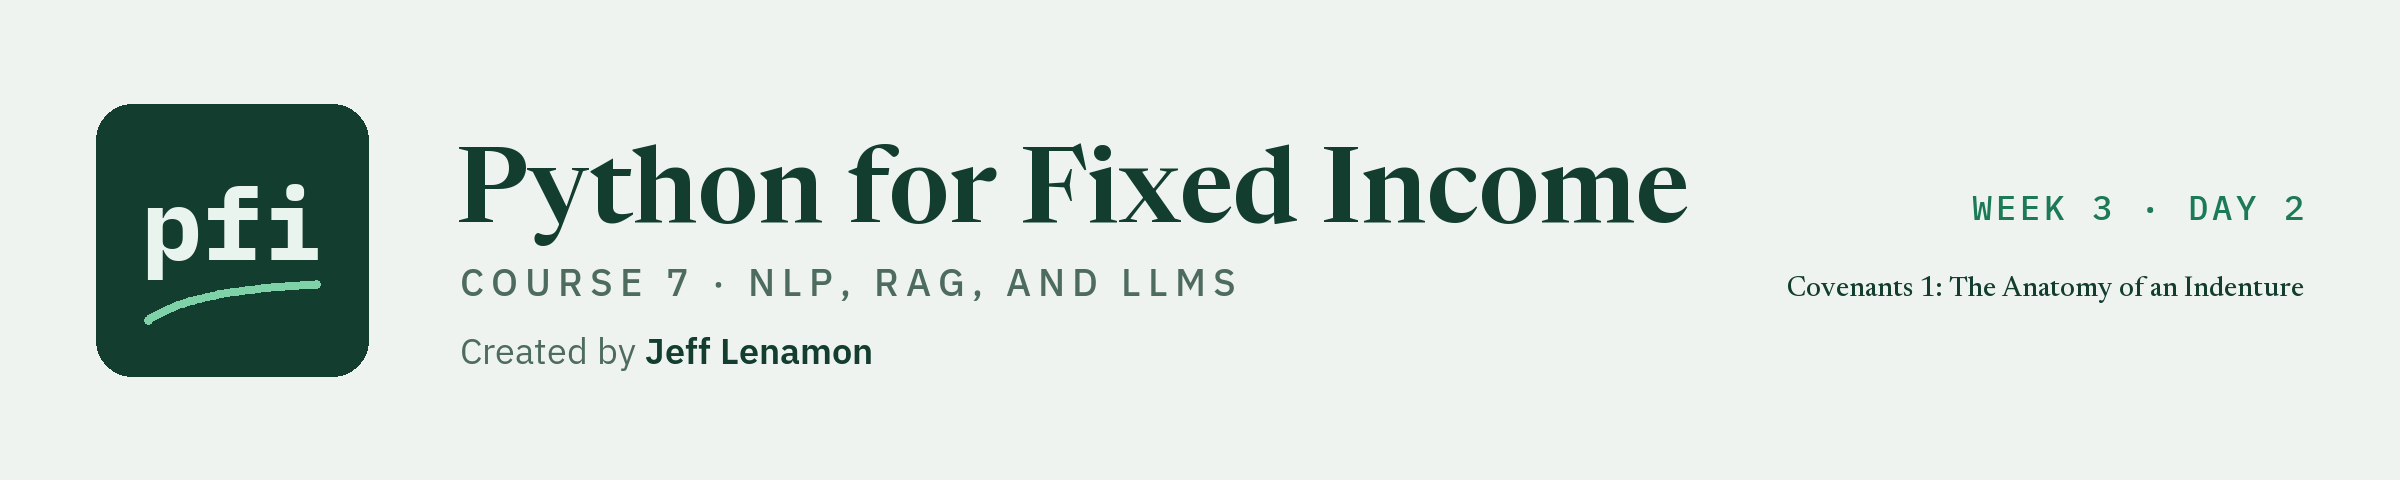

# Covenants 1: The Anatomy of an Indenture

Week 3, Day 2. Today you take one real indenture apart, write a schema for its covenants, send the debt covenant to a model with the definitions it uses, and check every number the response returns against the text.

**Data:** `course7_indentures/boyd_2021.txt`: Boyd Gaming Corporation, Indenture dated as of June 8, 2021, 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495: **real**, a public record on sec.gov, quoted for descriptive extraction only.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course7_nlp_and_llms/week3/day2/12_covenants_1_the_anatomy_of_an_indenture.ipynb)

Yesterday's requests asked about one sentence or one paragraph. Today's ask about a whole covenant. An **indenture** is the contract between a company that borrows by issuing notes and the holders of those notes, kept by a trustee. The covenants in it are promises the company makes for as long as the notes are outstanding: how much more debt it may take on, what it may pay out, what it may pledge. A desk reads them and records the numbers: a ratio test, a basket of a fixed dollar amount, a basket that grows with the company's assets.

This notebook does that reading with code and a model, in a way that can be checked. It finds the parts of the indenture by regular expression, builds a table of the definitions each covenant uses, writes the schema a response must fit, sends Section 4.12 to the free model with only the definitions it uses, and then checks every number the response returns: is the cited section real, is the quote in it, is the number in the quote. The checks decide what goes in the table, not the model.

**The rules for real documents, as on every day of this course.**

* **The document is real.** The indenture is a public record on sec.gov, filed by its issuer. A source line sits under every excerpt.
* **Every prompt asks what the document says.** Each request today asks for the terms of one section as JSON, with a quote beside every number, or "NOT IN TEXT". The system prompt that goes first in every request refuses anything else. No prompt asks for an opinion, a grade, a comparison of issuers, or a view about the future.
* **An extracted value is what a response returned.** It is called "the extracted value", with "its quote"; a value that passes the checks "passed the source check". Every number about a response is read from the saved file, and every number about the indenture from the text, through `textkit`.
* **The issuer's name appears only as the author of the document being read**: in the data line and the source lines.

**Rows.** No model is fitted or scored in this notebook: every number about the indenture describes the one document as filed, and every number about a response describes a **saved response**, the text a model returned to a request the course sent on 2026-10-08, stored in `data/course7_llm_responses/day12/` and replayed here. With your own key a run sends the requests again, and its text can differ.

Today you will:

1. Take the indenture apart: who signs it, its twelve articles, the twenty sections of Article 4.
2. Build the dictionary: `definitions_dict` for every definition of Section 1.01, and `terms_used` for the ones a covenant depends on.
3. Read the key covenants with regular expressions, each excerpt with its source line.
4. Write the schema as five pydantic models, and read part of its JSON form.
5. Send the first extraction of Section 4.12 and read what came back, with `parse_json` and `check_extraction`.
6. Change the prompt one sentence at a time, and read the checks after each change.
7. Extract five covenants into one checked table, `extractions.csv`, committed and diffed.
8. Check every prompt with `assert_extraction_only`.

Q. Set up today's work folder: the thread settings, the quiet-loading settings, the seed, and the indenture's text.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [ ]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course7_nlp_and_llms/requirements.txt
NEEDED = {
    "bs4": "beautifulsoup4==4.15.0",
    "huggingface_hub": "huggingface-hub==1.33.0",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "keras": "keras==3.15.1",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openai": "openai==3.26.0",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pydantic": "pydantic==2.13.5",
    "pypdf": "pypdf==6.19.0",
    "pypdfium2": "pypdfium2==5.14.0",
    "pytest": "pytest==9.1.1",
    "dotenv": "python-dotenv==1.2.4",
    "requests": "requests==2.34.2",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "sentence_transformers": "sentence-transformers==6.1.0",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "tensorflow": "tensorflow==2.21.0",
    "torch": "torch==2.14.1",
    "transformers": "transformers==5.19.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

28 packages checked, all present


In [1]:
# today's setup: thread settings, quiet model loading, the modules, the seed, the course data, a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These lines must run before numpy, pandas, scikit-learn, or PyTorch is imported: if you ran another cell first,
# restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

# the model libraries print download bars and notices; these lines must run before they are imported
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("sklearn", "scikit-learn"), ("torch", "torch"), ("transformers", "transformers"), ("sentence_transformers", "sentence-transformers"), ("openai", "openai"), ("pydantic", "pydantic"), ("bs4", "beautifulsoup4"), ("pypdf", "pypdf"), ("pypdfium2", "pypdfium2"), ("dotenv", "python-dotenv"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course7_nlp_and_llms/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "torch": "2.14.1", "transformers": "5.19.0", "sentence-transformers": "6.1.0", "openai": "3.26.0", "pydantic": "2.13.5", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name].split("+")[0] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "course7_fomc_statements.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course7_12_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["course7_indentures/boyd_2021.txt"]
for name in DATA_FILES:
    (work / name).parent.mkdir(parents=True, exist_ok=True)
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, torch 2.14.1, transformers 5.19.0, sentence-transformers 6.1.0, openai 3.26.0, pydantic 2.13.5, pytest 9.1.1
Work folder: pfi_course7_12_vofmp0mo, in your temp folder
Data files from the data folder of the course repo: course7_indentures/boyd_2021.txt
SEED = 42


* The setup cell is day 1's, line for line (day 1 explains each line), in the form without PyTorch: today runs no Hugging Face model.
* One data file: the Boyd indenture's text, made from the filed HTML by day 9's `html_to_text`.
* **A live run differs from this notebook.** It was saved in replay mode, with no key loaded. With your own key every request goes out again, and the model's text, and so the checks' results, can differ. Every response cell ends with the LLM line, which says which mode printed it.

Q. Write the earlier courses' modules today needs, unchanged: `mlkit.py`, `marketdata.py`, `bondmath.py`.

In [2]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


In [3]:
%%writefile marketdata.py
"""marketdata: dated market series for fixed income, checked against Excel.

Written day by day in Python for Fixed Income, Course 3: Market Data and Time Series.

Conventions, the same in every function:
- A series has a DatetimeIndex named date: naive calendar dates (no time, no time zone), unique and ascending.
- Yields are in percent (5.29 means 5.29 percent), as Treasury and FRED publish them. Spreads are in basis points.
- Changes of yields and spreads are in basis points. Price changes are simple returns in percent.
- Windows are counted in observations (rows of the market calendar), trailing, and include the current row.
- A missing observation is NaN. It is dropped before any change or window is computed, never filled.
- A secret (an API key) is never printed, written to a file, or put in an error message.
"""
import os  # environment variables
from pathlib import Path  # file paths


def get_secret(name: str, env_file: str | Path) -> str:
    """Return a secret such as an API key, looked up in three places in a fixed order.

    Units: none; the secret is text. Convention: the first place that holds a non-empty value wins:
    1. the environment variable `name`;
    2. Colab's Secrets panel (google.colab.userdata), only when running in Colab;
    3. the .env file at `env_file`, read with dotenv.dotenv_values, which does not change os.environ.
    The value is returned and never printed. Raises RuntimeError naming the secret and the three places
    looked, never a value and never the full path of the file.
    """
    # 1. the environment: a variable set in PowerShell, or by the program that started Python
    value = os.environ.get(name)
    if value:
        return value

    # 2. Colab's Secrets panel: the import works only inside Colab
    try:
        from google.colab import userdata
    except ImportError:
        userdata = None
    if userdata is not None:
        try:
            value = userdata.get(name)
        # a secret that is not there, or one the notebook has not been given access to
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            value = None
        if value:
            return value

    # 3. the .env file, imported here so Colab never needs python-dotenv
    env_path = Path(env_file)
    if env_path.is_file():
        from dotenv import dotenv_values
        value = dotenv_values(env_path).get(name)
        if value:
            return value

    # nothing found: say where we looked, with the file's name only (a full path shows a user name)
    raise RuntimeError(
        f"Secret {name} not found. Looked in: the environment variable {name}, "
        f"Colab's Secrets panel, and the file {env_path.name} given as env_file."
    )


import pandas as pd  # dated series, from day 2
import requests  # HTTP, from day 2

# FRED's endpoint for the observations of one series
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"


def fred_params(series_id: str, api_key: str, start: str | None = None, end: str | None = None) -> dict:
    """The query parameters for one request to FRED's series/observations endpoint.

    Units: start and end are dates as text, YYYY-MM-DD. Convention: JSON is asked for (file_type json);
    a start or end left as None is not sent, so FRED returns the series from its first or to its last date.
    Pure: builds a dict and sends nothing. The dict holds the key, so it is never printed.
    """
    # the three parameters every request needs
    params = {"series_id": series_id, "api_key": api_key, "file_type": "json"}
    # the optional date range
    if start is not None:
        params["observation_start"] = start
    if end is not None:
        params["observation_end"] = end
    return params


def parse_fred_observations(payload: dict, name: str) -> pd.Series:
    """Turn a FRED series/observations JSON answer into a float series.

    Units: as FRED publishes the series (percent for the Treasury and spread series).
    Convention: one value per observation, indexed by its date (a DatetimeIndex named date). FRED's
    missing marker "." becomes NaN and is kept: dropping it is a separate, visible step.
    Raises ValueError if the answer has no "observations" list.
    """
    # stop on an answer that is not a series/observations answer
    if "observations" not in payload:
        raise ValueError(f"the answer for {name} has no 'observations'; keys are {sorted(payload)}")
    observations = payload["observations"]
    # each date as a calendar date
    dates = pd.to_datetime([obs["date"] for obs in observations], format="%Y-%m-%d")
    # each value as a float; "." is FRED's mark for a day with no value, so it becomes NaN, never 0
    values = [float("nan") if obs["value"] == "." else float(obs["value"]) for obs in observations]
    series = pd.Series(values, index=dates, name=name, dtype="float64")
    series.index.name = "date"
    return series


def fred_series(series_id: str, api_key: str, start: str | None = None, end: str | None = None,
                timeout: float = 30) -> pd.Series:
    """Download one series from the FRED API: one GET with requests, then parse_fred_observations.

    Units: as FRED publishes the series. Convention: "." rows are kept as NaN, as parse_fred_observations.
    The only function in this module that uses the network.
    Errors never show the key or the URL (which holds the key):
    - it never calls response.raise_for_status(), whose message holds the full URL;
    - an answer other than HTTP 200 raises RuntimeError with the status and FRED's own error message;
    - a connection problem (requests.RequestException) raises RuntimeError naming only the exception class;
    - both are raised `from None`, so no chained traceback shows the original error and its URL.
    Raises RuntimeError if FRED answers with zero observations (FRED returns HTTP 200 with count 0 for a
    range the series does not cover).
    """
    # the request, sent once; the parameters (and the key) stay inside requests
    try:
        response = requests.get(FRED_URL, params=fred_params(series_id, api_key, start, end), timeout=timeout)
    except requests.RequestException as error:
        # the original message holds the URL with the key, so only the class name is kept
        raise RuntimeError(f"Request for {series_id} failed: {type(error).__name__}") from None

    # an answer other than 200: FRED puts its reason in "error_message"
    status = response.status_code
    if status != 200:
        try:
            error_message = response.json().get("error_message", "no error message")
        except ValueError:
            error_message = "the answer was not JSON"
        # FRED's messages do not echo the key; replace it anyway in case one ever does
        error_message = error_message.replace(api_key, "***")
        raise RuntimeError(f"FRED returned HTTP {status} for {series_id}: {error_message}") from None

    # parse, and stop on an empty answer
    series = parse_fred_observations(response.json(), series_id)
    if series.empty:
        raise RuntimeError(f"FRED returned no observations for {series_id} (start {start}, end {end})")
    return series


def _check_index(index: pd.Index, what: str) -> None:
    """Stop unless `index` is a DatetimeIndex with unique dates in ascending order.

    A helper for the functions below (the leading underscore marks it as not part of the module's API).
    """
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{what} must have a DatetimeIndex, not {type(index).__name__}")
    if not index.is_unique:
        raise ValueError(f"{what} has repeated dates, for example {index[index.duplicated()][0].date()}")
    if not index.is_monotonic_increasing:
        raise ValueError(f"{what} dates are not in ascending order")


def missing_weekdays(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    """The weekdays from the first date to the last that have no row.

    Units: dates. Convention: a weekday is Monday to Friday; no holiday calendar is used, so the result is
    every weekday the data skipped (holidays and any other closure). Weekends are never counted.
    Raises ValueError on an index that is not unique and ascending dates.
    """
    _check_index(index, "index")
    # every Monday to Friday in the span
    weekdays = pd.bdate_range(index[0], index[-1])
    # the ones with no row
    missing = weekdays.difference(index)
    missing.name = "date"
    return missing


def align(series: dict[str, pd.Series], how: str = "inner") -> pd.DataFrame:
    """Put several dated series side by side, one column each, joined on date.

    Units: each column keeps its own units. Convention: how="inner" keeps the dates every series has;
    how="outer" keeps every date any series has and leaves NaN where a series has no row. Nothing is filled.
    Raises ValueError for any other `how`, or for a series whose index is not unique ascending dates.
    """
    # stop on a join the course does not use
    if how not in ("inner", "outer"):
        raise ValueError(f"how must be 'inner' or 'outer', not {how!r}")
    for name, values in series.items():
        _check_index(values.index, name)
    # one column per series, named by its key
    frame = pd.concat(series, axis=1, join=how)
    # an outer join can mix the order of dates, so sort them
    frame = frame.sort_index()
    frame.index.name = "date"
    return frame


def stale_runs(series: pd.Series, min_length: int = 3) -> pd.DataFrame:
    """Runs of the same value repeated on consecutive observations: a sign of a value that stopped updating.

    Units: `value` has the series' units, `length` counts observations. Convention: consecutive means
    consecutive rows, whatever the calendar gap. One row per run of at least `min_length` identical values,
    with columns start, end, length, value.
    Raises ValueError if min_length is below 2, the series has missing values (drop them first), or its index
    is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if min_length < 2:
        raise ValueError(f"min_length must be at least 2, not {min_length}")
    if series.isna().any():
        raise ValueError(f"series has {series.isna().sum()} missing values; drop them first with .dropna()")
    # a new run starts wherever the value differs from the row before
    run_id = (series != series.shift()).cumsum()
    runs = []
    for _, run in series.groupby(run_id):
        # keep runs long enough to report
        if len(run) >= min_length:
            runs.append({"start": run.index[0], "end": run.index[-1], "length": len(run), "value": run.iloc[0]})
    return pd.DataFrame(runs, columns=["start", "end", "length", "value"])


def _check_series(series: pd.Series, what: str) -> None:
    """Stop unless `series` has unique ascending dates and no missing values (a helper, not part of the API)."""
    _check_index(series.index, what)
    if series.isna().any():
        raise ValueError(f"{what} has {series.isna().sum()} missing values; drop them first with .dropna()")


def last_per_period(data: pd.Series | pd.DataFrame, freq: str) -> pd.Series | pd.DataFrame:
    """The last observation in each week or month, labelled by the date of that observation.

    Units: unchanged. Convention: freq "W-FRI" is the week ending Friday, "ME" the calendar month. Each
    period's row is the last row the data has in it, kept with its own date: September 2026 is labelled
    2026-09-30, and the week of Good Friday 2025 (no row on Friday 2025-04-18) is labelled Thursday 2025-04-17.
    pandas' resample(freq).last() labels by the period end instead. A Series must have no missing values;
    a DataFrame's rows are taken as they are, so a tenor with no value that day stays NaN.
    Raises ValueError for any other freq, or for an index that is not unique ascending dates.
    """
    # the two periods the course uses, with pandas' name for each period
    periods = {"W-FRI": "W-FRI", "ME": "M"}
    if freq not in periods:
        raise ValueError(f"freq must be 'W-FRI' or 'ME', not {freq!r}")
    if isinstance(data, pd.Series):
        _check_series(data, "data")
    else:
        _check_index(data.index, "data")
    # the period each row belongs to
    period_of_row = data.index.to_period(periods[freq])
    # the position of the last row in each period
    positions = pd.Series(range(len(data)), index=data.index).groupby(period_of_row).max()
    # those rows, with their own dates
    return data.iloc[positions.to_numpy()]


def value_as_of(series: pd.Series, as_of) -> tuple[pd.Timestamp, float]:
    """The date and value of the last observation on or before `as_of`.

    Units: the value has the series' units. Convention: the as-of value; on a holiday or weekend it is
    the previous market day's value. Excel: =XLOOKUP(as_of, dates, values, , -1).
    Raises ValueError if as_of is before the first observation, the series has missing values, or its
    index is not unique ascending dates.
    """
    _check_series(series, "series")
    as_of = pd.Timestamp(as_of)
    # stop before the start: there is no value to carry
    if as_of < series.index[0]:
        raise ValueError(f"{as_of.date()} is before the first observation, {series.index[0].date()}")
    # the position of the last date on or before as_of
    position = series.index.searchsorted(as_of, side="right") - 1
    return series.index[position], float(series.iloc[position])


from datetime import date, datetime  # the cache file's date, from day 5

# FRED's Treasury constant maturity series and the Treasury file's column for each
FRED_TREASURY = {
    "DGS1MO": "1 Mo", "DGS3MO": "3 Mo", "DGS6MO": "6 Mo", "DGS1": "1 Yr", "DGS2": "2 Yr", "DGS3": "3 Yr",
    "DGS5": "5 Yr", "DGS7": "7 Yr", "DGS10": "10 Yr", "DGS20": "20 Yr", "DGS30": "30 Yr",
}

# series IDs whose data the provider licenses: never cached, never written to a file
LICENSED_PREFIXES = ("BAML", "BAA", "AAA", "DBAA", "DAAA")


def write_cache(series: pd.Series, cache_dir: Path) -> Path:
    """Write a series to cache_dir / "<series name>.csv" and return the path.

    Units: unchanged. Convention: one row per date, the dates as YYYY-MM-DD and every float at full
    precision (no float_format), so read_cache gives back exactly the same numbers. NaN rows are kept, empty.
    Raises ValueError if the series has no name or its index is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if series.name is None:
        raise ValueError("series must have a name: it becomes the file name")
    # the folder is created the first time
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / f"{series.name}.csv"
    # LF line endings, so the file is the same on Windows and in Colab
    series.to_csv(path, index_label="date", lineterminator="\n")
    return path


def read_cache(series_id: str, cache_dir: Path) -> pd.Series:
    """Read a series written by write_cache.

    Units: as written. Convention: a float series named series_id with a DatetimeIndex named date. The file
    is read with float_precision="round_trip": pandas' default number parser is fast but can miss the last
    digit (1.5666666666666667 comes back as 1.5666666666666669), and a cache must give back what it was given.
    Raises FileNotFoundError if the cache has no file for series_id.
    """
    path = Path(cache_dir) / f"{series_id}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"no cache file {path.name} in the folder {Path(cache_dir).name}")
    frame = pd.read_csv(path, parse_dates=["date"], index_col="date", float_precision="round_trip")
    return frame[series_id].astype("float64")


def cached_fred_series(series_id: str, api_key: str, cache_dir: Path, start: str | None = None) -> pd.Series:
    """A FRED series from today's cache file if there is one, otherwise from FRED, then cached.

    Units: as FRED publishes the series. Convention: the cache file counts as fresh if it was written today
    (the computer's local date); otherwise fred_series downloads the series from `start` and write_cache
    saves it. A fresh file is returned as it is, whatever `start` it was downloaded with.
    Raises ValueError for a series ID that starts with one of LICENSED_PREFIXES: those providers' terms do
    not allow storing their data. The list covers this course's licensed series; it is not a general
    licence check, and any other series' terms are yours to read.
    """
    # refuse a licensed series before anything is downloaded or written
    if series_id.startswith(LICENSED_PREFIXES):
        raise ValueError(f"{series_id} is licensed data (prefix in LICENSED_PREFIXES): its terms do not allow "
                         f"storing it, so it is never cached. Use fred_series and keep it in memory.")
    path = Path(cache_dir) / f"{series_id}.csv"
    # today's file is fresh: no request at all
    if path.is_file() and datetime.fromtimestamp(path.stat().st_mtime).date() == date.today():
        return read_cache(series_id, cache_dir)
    # otherwise one request, then save it for the rest of the day
    series = fred_series(series_id, api_key, start=start)
    write_cache(series, cache_dir)
    return series


def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:
    """Change over `periods` observations, in basis points.

    Units: the result is in bp. percent_units=True for a series in percent (a yield): (x_t - x_{t-k}) x 100.
    percent_units=False for a series already in bp (a spread): x_t - x_{t-k}.
    Convention: k rows back, whatever the calendar gap (the Tuesday after a Monday holiday is a change from
    Friday). The first `periods` values are NaN. Never a percent change of a yield or spread level.
    Excel: =(B3-B2)*100 for a yield in percent.
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # the difference from k rows back
    difference = series - series.shift(periods)
    # percent to basis points: 1 percent is 100 bp
    return difference * 100 if percent_units else difference


def return_pct(series: pd.Series, periods: int = 1) -> pd.Series:
    """Simple return over `periods` observations, in percent, for a price series.

    Units: prices in, percent out. Convention: (P_t / P_{t-k} - 1) x 100, k rows back; no log returns.
    The first `periods` values are NaN. Excel: =(C3/C2-1)*100
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # price now over price k rows back, less one, in percent
    return (series / series.shift(periods) - 1) * 100


def change_since_bp(series: pd.Series, as_of, since, percent_units: bool = True) -> float:
    """Change from the as-of value at `since` to the as-of value at `as_of`, in basis points.

    Units: the result is in bp; percent_units as change_bp. Convention: each end is the last observation
    on or before its date (value_as_of), so a `since` on a holiday or weekend uses the market day before it.
    One week back is as_of - 7 days; one month back is as_of - pd.DateOffset(months=1).
    Excel: =(XLOOKUP(as_of,A:A,B:B,,-1)-XLOOKUP(since,A:A,B:B,,-1))*100
    Raises ValueError if since is after as_of or before the first observation.
    """
    if pd.Timestamp(since) > pd.Timestamp(as_of):
        raise ValueError(f"since ({pd.Timestamp(since).date()}) must not be after as_of ({pd.Timestamp(as_of).date()})")
    # the as-of value at each end
    _, value_now = value_as_of(series, as_of)
    _, value_then = value_as_of(series, since)
    difference = value_now - value_then
    return difference * 100 if percent_units else difference


import math  # the annualising factor, from day 7

# the course's annualising convention for daily figures; other desks use other factors
TRADING_DAYS_PER_YEAR = 252


def rolling_vol_bp(changes_bp: pd.Series, window: int = 63, annualise: bool = False) -> pd.Series:
    """Rolling volatility of daily changes in bp: the sample standard deviation over a trailing window.

    Units: changes in bp in, bp out (per day; per year when annualise=True).
    Convention: the window ending on date t holds t and the window - 1 rows before it (rows, not calendar
    days); min_periods = window, so the first window - 1 values are NaN; sample standard deviation (ddof=1,
    Excel STDEV.S). annualise=True multiplies by sqrt(252), a convention.
    Excel: =STDEV.S(F2:F64) filled down, and =STDEV.S(F2:F64)*SQRT(252)
    Raises ValueError if window is below 2, the changes have missing values (the first change is NaN, so pass
    change_bp(...).dropna()), or the index is not unique ascending dates.
    """
    _check_series(changes_bp, "changes_bp")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # trailing window of `window` rows, full windows only, sample standard deviation
    vol = changes_bp.rolling(window, min_periods=window).std(ddof=1)
    # per year only when asked for
    if annualise:
        vol = vol * math.sqrt(TRADING_DAYS_PER_YEAR)
    return vol


def rolling_zscore(series: pd.Series, window: int = 252) -> pd.Series:
    """Where each value sits in its own trailing window, in standard deviations from the window's mean.

    Units: none (a number of standard deviations). Convention: z_t = (x_t - mean) / sample standard deviation,
    both over the trailing window that includes x_t (window rows, min_periods = window, ddof=1). NaN where the
    window's standard deviation is 0 (a flat, stale stretch). Describes position only; it is not a signal.
    Excel: =STANDARDIZE(B253,AVERAGE(B2:B253),STDEV.S(B2:B253)) filled down
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # the trailing window's mean and sample standard deviation, today included
    mean = series.rolling(window, min_periods=window).mean()
    std = series.rolling(window, min_periods=window).std(ddof=1)
    # a flat window has no spread to measure against
    std = std.where(std != 0)
    return (series - mean) / std


def rolling_percentile_rank(series: pd.Series, window: int = 252) -> pd.Series:
    """The share of the trailing window at or below each value, in percent.

    Units: percent, above 0 up to 100. Convention: 100 x (number of window values at or below x_t) / window,
    over the trailing window that includes x_t (min_periods = window). Ties count as at or below.
    Values are compared at 15 significant digits, as Excel's COUNTIF compares them: in binary arithmetic
    (4.13 - 3.81) x 100 is 31.999999999999986 and (4.12 - 3.80) x 100 is 32.00000000000003, and the two count
    as a tie at 32 bp.
    Excel: =COUNTIF(B2:B253,"<="&B253)/COUNT(B2:B253)*100 filled down. Excel's PERCENTRANK.INC is a
    different measure (values strictly below over n - 1, cut to 3 digits).
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # 15 significant digits, so arithmetic noise in the last binary digit does not break a tie
    rounded = series.map(lambda value: float(f"{value:.15g}"))
    # method="max" gives each value the count of window values at or below it; pct=True divides by the count
    return rounded.rolling(window, min_periods=window).rank(pct=True, method="max") * 100


def slope_bp(curve: pd.DataFrame, short: str, long: str) -> pd.Series:
    """A curve slope in basis points: the long tenor's yield less the short tenor's.

    Units: yields in percent in, bp out. Convention: (curve[long] - curve[short]) x 100, named short then
    long: 2s10s is slope_bp(curve, "2 Yr", "10 Yr"). Positive when the longer yield is higher.
    Excel: =(M2-I2)*100 on the Treasury file opened in Excel, with the 10 Yr in M and the 2 Yr in I.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # long less short, percent to bp
    return ((curve[long] - curve[short]) * 100).rename(f"{short} to {long} slope, bp")


def butterfly_bp(curve: pd.DataFrame, short: str, belly: str, long: str) -> pd.Series:
    """A butterfly in basis points: twice the belly's yield less both wings.

    Units: yields in percent in, bp out. Convention: (2 x belly - short - long) x 100, named short, belly,
    long: 2s5s10s is butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr"). Positive when the belly yields more than
    the average of the wings. Some desks quote the opposite sign.
    Excel: =(2*K2-I2-M2)*100 on the Treasury file, with the 5 Yr in K.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, belly, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # twice the belly, less each wing, percent to bp
    return ((2 * curve[belly] - curve[short] - curve[long]) * 100).rename(f"{short} {belly} {long} fly, bp")


def fly_weights(dv01_short: float, dv01_belly: float, dv01_long: float) -> tuple[float, float, float]:
    """Face amounts for a DV01-neutral butterfly, per 1 of belly face.

    Units: DV01s in any one unit (price points per 100 of face per bp from bondmath.dv01); weights are face
    per 1 of belly face. Convention: the belly's face is 1; each wing's face is set so its DV01 is half the
    belly's: w_short = 0.5 x dv01_belly / dv01_short and w_long = 0.5 x dv01_belly / dv01_long. With the
    belly on one side and both wings on the other, the DV01s net to zero. Arithmetic, not a position.
    Returns (w_short, 1.0, w_long). Raises ValueError if a DV01 is not positive.
    """
    # a DV01 of zero or less cannot be balanced
    for label, dv01 in (("dv01_short", dv01_short), ("dv01_belly", dv01_belly), ("dv01_long", dv01_long)):
        if dv01 <= 0:
            raise ValueError(f"{label} must be positive, not {dv01}")
    # half the belly's DV01 on each wing
    w_short = 0.5 * dv01_belly / dv01_short
    w_long = 0.5 * dv01_belly / dv01_long
    return w_short, 1.0, w_long


def summary_table(data: pd.DataFrame, as_of, units: dict[str, str], window: int = 252) -> pd.DataFrame:
    """One row per column of `data`: the level and every measure as of one date, from rows on or before it.

    Units: units[column] is "pct" for a series in percent (a yield) or "bp" for a series in bp (a spread,
    slope, or fly). level is in that unit; chg_1d_bp, chg_1w_bp, chg_1m_bp are in bp; zscore has no unit;
    pct_rank is in percent.
    Convention: each column's missing values are dropped and only rows on or before as_of are used, so a later
    row can never change the table. level is the as-of value; chg_1d_bp is the change from the previous
    observation; chg_1w_bp and chg_1m_bp are change_since_bp from as_of - 7 days and as_of - 1 month;
    zscore and pct_rank are rolling_zscore and rolling_percentile_rank over `window` rows, today included.
    Raises ValueError if a column has no unit or a unit other than "pct" or "bp", or the index is not unique
    ascending dates.
    """
    _check_index(data.index, "data")
    as_of = pd.Timestamp(as_of)
    rows = {}
    for column in data.columns:
        # the unit decides whether changes are multiplied by 100
        unit = units.get(column)
        if unit not in ("pct", "bp"):
            raise ValueError(f"units[{column!r}] must be 'pct' or 'bp', not {unit!r}")
        percent_units = unit == "pct"
        # only what was known on the as-of date, missing values dropped
        series = data[column].loc[:as_of].dropna()
        _, level = value_as_of(series, as_of)
        rows[column] = {
            "unit": unit,
            "level": level,
            "chg_1d_bp": change_bp(series, 1, percent_units).iloc[-1],
            "chg_1w_bp": change_since_bp(series, as_of, as_of - pd.Timedelta(days=7), percent_units),
            "chg_1m_bp": change_since_bp(series, as_of, as_of - pd.DateOffset(months=1), percent_units),
            "zscore": rolling_zscore(series, window).iloc[-1],
            "pct_rank": rolling_percentile_rank(series, window).iloc[-1],
        }
    # one row per series
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "series"
    return table


import sqlite3  # a database in one file, from day 11
from contextlib import closing  # closes a connection at the end of a with block, from day 11


def load_tables(db_path: Path, tables: dict[str, Path]) -> dict[str, int]:
    """Write each CSV file to a table of the SQLite database at db_path, and return each table's row count.

    Units: unchanged; dates stay ISO text (YYYY-MM-DD), which SQLite sorts and compares in date order.
    Convention: tables maps a table name to a CSV path; an existing table of that name is replaced. Each
    count is read back from the database with SELECT COUNT(*) and checked against the CSV's rows.
    Raises ValueError for a table name that is not a plain identifier (letters, digits, underscore), and
    RuntimeError if a table's count differs from its CSV's.
    """
    counts = {}
    # sqlite3's own `with` commits but does not close, so closing() closes the file at the end
    with closing(sqlite3.connect(db_path)) as connection:
        for name, csv_path in tables.items():
            # a table name cannot be a ? parameter, so only plain names are allowed
            if not name.isidentifier():
                raise ValueError(f"table name {name!r} must be letters, digits, and underscores")
            frame = pd.read_csv(csv_path)
            frame.to_sql(name, connection, if_exists="replace", index=False)
            connection.commit()
            # read the count back from the database and check it
            count = connection.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]
            if count != len(frame):
                raise RuntimeError(f"table {name} has {count} rows but {Path(csv_path).name} has {len(frame)}")
            counts[name] = count
    return counts


def run_query(db_path: Path, sql: str, params: tuple = ()) -> pd.DataFrame:
    """Run one SQL query against the SQLite database at db_path and return the result.

    Units: as stored. Convention: values go in through ? parameters (`params`), never pasted into the SQL
    text with an f-string. The connection is closed when the query is done.
    Raises FileNotFoundError if db_path does not exist (sqlite3 would otherwise create an empty database).
    """
    if not Path(db_path).is_file():
        raise FileNotFoundError(f"no database file {Path(db_path).name}")
    with closing(sqlite3.connect(db_path)) as connection:
        return pd.read_sql_query(sql, connection, params=params)


def assert_same_rows(left: pd.DataFrame, right: pd.DataFrame, sort_by: list[str]) -> None:
    """Check that two tables hold the same rows, in any order: a SQL result against its pandas equivalent.

    Units: unchanged. Convention: the same column names; both sorted by `sort_by`, index reset, columns in
    left's order; text and whole numbers equal exactly, floats within rtol=1e-12 and atol=1e-9 (SQLite and
    pandas may add in a different order). An integer column on one side may be a float column on the other.
    Raises AssertionError with pandas' message on the first difference.
    """
    # the same columns, whatever their order
    if set(left.columns) != set(right.columns):
        raise AssertionError(f"columns differ: left only {sorted(set(left.columns) - set(right.columns))}, "
                             f"right only {sorted(set(right.columns) - set(left.columns))}")
    # the same order of rows and columns on both sides
    left_sorted = left.sort_values(sort_by).reset_index(drop=True)
    right_sorted = right[list(left.columns)].sort_values(sort_by).reset_index(drop=True)
    pd.testing.assert_frame_equal(left_sorted, right_sorted, check_dtype=False, rtol=1e-12, atol=1e-9)


import json  # an assistant's JSON reply, from day 13


def parse_json_reply(text: str, required: list[str]) -> dict:
    """Read an AI assistant's reply that was asked to answer in JSON, and check it has the fields asked for.

    Units: none. Convention: the whole reply must be one JSON object (json.loads); extra fields are kept.
    Raises ValueError if the text is not JSON, is JSON but not an object, or lacks any field in `required`
    (the message names every missing field).
    """
    # parse the reply; a reply with prose around the JSON fails here
    try:
        reply = json.loads(text)
    except json.JSONDecodeError as error:
        raise ValueError(f"the reply is not valid JSON: {error.msg} at line {error.lineno}, column {error.colno}") from error
    # an object, not a list or a bare number
    if not isinstance(reply, dict):
        raise ValueError(f"the reply is JSON but not an object: it is a {type(reply).__name__}")
    # every field asked for
    missing = [field for field in required if field not in reply]
    if missing:
        raise ValueError(f"the reply is missing {', '.join(missing)}")
    return reply


import base64  # charts embedded in the HTML, from day 14
import html  # safe text in the HTML, from day 14
import io  # a chart written to memory, from day 14

from matplotlib.figure import Figure  # the type of a chart, from day 14

import bondmath  # the book section, from day 14

# the Treasury file's tenor labels and their years
TENOR_YEARS = {"1 Mo": 1 / 12, "1.5 Month": 1.5 / 12, "2 Mo": 2 / 12, "3 Mo": 0.25, "4 Mo": 4 / 12, "6 Mo": 0.5,
               "1 Yr": 1.0, "2 Yr": 2.0, "3 Yr": 3.0, "5 Yr": 5.0, "7 Yr": 7.0, "10 Yr": 10.0, "20 Yr": 20.0,
               "30 Yr": 30.0}
# the slopes (short, long) and flies (short, belly, long) on the snapshot
SLOPES = {"2s10s": ("2 Yr", "10 Yr"), "5s30s": ("5 Yr", "30 Yr"), "3m10y": ("3 Mo", "10 Yr")}
FLIES = {"2s5s10s": ("2 Yr", "5 Yr", "10 Yr"), "5s10s30s": ("5 Yr", "10 Yr", "30 Yr")}
DISCLAIMER = ("This course is educational content created in a personal capacity. Nothing here is investment "
              "advice or a recommendation to buy or sell any security. All portfolio data is synthetic.")
SOURCES = ("Treasury yields: U.S. Department of the Treasury, Daily Treasury Par Yield Curve Rates (public domain). "
           "Credit spreads: course3_synthetic_spreads.csv, synthetic, invented for this course, not ICE, Moody's, "
           "or any index. Book: holdings.csv, a synthetic book of invented issuers.")


def _book_section(book: pd.DataFrame, curve: pd.DataFrame) -> pd.DataFrame:
    """The book's position DV01 and the mechanical change in market value from the day's curve change, by
    sector and by rating bucket, then the total (a helper for snapshot_tables, not part of the API)."""
    settlement_dates = book["as_of_date"].unique()
    if len(settlement_dates) != 1:
        raise ValueError(f"the book must have one as_of_date, not {len(settlement_dates)}")
    settlement = date.fromisoformat(settlement_dates[0])
    # the day's curve change in bp, by tenor in years, for interpolation
    tenors_years = curve["years"].tolist()
    changes_bp = curve["chg_bp"].tolist()
    rows = []
    for bond in book.itertuples():
        maturity = date.fromisoformat(bond.maturity)
        # position DV01 in dollars per bp: DV01 per 100 of face times face / 100
        dv01_usd = bondmath.dv01(settlement, maturity, bond.coupon, bond.yield_pct) * bond.par_held / 100
        # the day's curve change at the bond's maturity, applied to its yield: a what-if, not a forecast
        shift_bp = bondmath.interpolate_yield(bondmath.years_to_maturity(settlement, maturity), tenors_years, changes_bp)
        before = bondmath.dirty_price(settlement, maturity, bond.coupon, bond.yield_pct)
        after = bondmath.dirty_price(settlement, maturity, bond.coupon, bond.yield_pct + shift_bp / 100)
        rows.append({"sector": bond.sector, "bucket": bond.rating.rstrip("+-"), "face_usd": bond.par_held,
                     "market_value_usd": bond.market_value, "dv01_usd": dv01_usd,
                     "mv_change_usd": (after - before) * bond.par_held / 100})
    positions = pd.DataFrame(rows)
    sums = {"bonds": ("face_usd", "size"), "face_usd": ("face_usd", "sum"),
            "market_value_usd": ("market_value_usd", "sum"), "dv01_usd": ("dv01_usd", "sum"),
            "mv_change_usd": ("mv_change_usd", "sum")}
    # by sector, then by rating bucket, then the whole book
    by_sector = positions.groupby("sector").agg(**sums).reset_index(names="group").assign(by="sector")
    by_bucket = positions.groupby("bucket").agg(**sums).reset_index(names="group").assign(by="rating bucket")
    total = pd.DataFrame([{"by": "total", "group": "book"} | {k: positions[c].agg(f) for k, (c, f) in sums.items()}])
    table = pd.concat([by_sector, by_bucket, total], ignore_index=True)
    return table[["by", "group", "bonds", "face_usd", "market_value_usd", "dv01_usd", "mv_change_usd"]]


def snapshot_tables(market: pd.DataFrame, book: pd.DataFrame, as_of, units: dict[str, str],
                    window: int = 252) -> dict[str, pd.DataFrame]:
    """The tables of a one-page daily market snapshot for `as_of`, from rows on or before it only.

    Units: yields in percent, spreads, slopes, flies, and changes in bp, dollars in the book table.
    Convention:
    - levels: summary_table of the columns named in `units`;
    - curve: each tenor's yield on as_of and on the previous observation, and the change in bp;
    - slopes_flies: summary_table of 2s10s, 5s30s, 3m10y, 2s5s10s, and 5s10s30s (all in bp);
    - book: the book's position DV01 (bondmath.dv01 at the book's own as_of_date) and the mechanical change
      in market value if each bond's yield moved by the day's change in the par curve, interpolated at its
      maturity with bondmath.interpolate_yield; by sector, by rating bucket, and in total. A what-if.
    Each table's attrs["as_of"] holds the date as YYYY-MM-DD, for the writers.
    Raises ValueError if as_of is not a market date (a date with a row in `market`).
    """
    _check_index(market.index, "market")
    as_of = pd.Timestamp(as_of)
    if as_of not in market.index:
        raise ValueError(f"{as_of.date()} is not a market date: market has no row for it")
    # only what was known on the as-of date
    known = market.loc[:as_of]
    levels = summary_table(known[list(units)], as_of, units, window)

    # the curve on as_of and on the previous observation
    tenors = [column for column in known.columns if column in TENOR_YEARS]
    previous_date = known.index[-2]
    curve = pd.DataFrame({"years": [TENOR_YEARS[t] for t in tenors],
                          "previous_pct": known.loc[previous_date, tenors].to_numpy(),
                          "as_of_pct": known.loc[as_of, tenors].to_numpy()}, index=pd.Index(tenors, name="tenor"))
    curve["chg_bp"] = (curve["as_of_pct"] - curve["previous_pct"]) * 100
    # a tenor with no value on either day is left out; the rest in order of years
    curve = curve.dropna().sort_values("years")

    # slopes and flies, then their summary
    shapes = pd.DataFrame({name: slope_bp(known, short, long) for name, (short, long) in SLOPES.items()}
                          | {name: butterfly_bp(known, *legs) for name, legs in FLIES.items()})
    slopes_flies = summary_table(shapes, as_of, {name: "bp" for name in shapes.columns}, window)

    tables = {"levels": levels, "curve": curve, "slopes_flies": slopes_flies, "book": _book_section(book, curve)}
    for table in tables.values():
        table.attrs["as_of"] = as_of.strftime("%Y-%m-%d")
    return tables


def write_snapshot_html(tables: dict[str, pd.DataFrame], figures: dict[str, Figure], path: Path, title: str) -> Path:
    """Write the snapshot as one self-contained HTML file and return its path.

    Units: as in the tables (numbers shown to 2 decimals). Convention: the title, the as-of date (from the
    tables' attrs, set by snapshot_tables), the disclaimer, each table as DataFrame.to_html, each chart as a
    PNG embedded in base64 (no separate image files), the data sources, and the synthetic label. Describes the
    data; it contains no forecast and no recommendation. Uses no template library.
    Raises ValueError if the tables carry no as-of date.
    """
    as_of = tables["levels"].attrs.get("as_of")
    if as_of is None:
        raise ValueError("the tables carry no as-of date; build them with snapshot_tables")
    parts = [f"<h1>{html.escape(title)}</h1>", f"<p>As of {as_of}.</p>",
             f"<p><em>{html.escape(DISCLAIMER)}</em></p>"]
    # each table, numbers to 2 decimals with thousands separators
    for name, table in tables.items():
        parts.append(f"<h2>{html.escape(name)}</h2>")
        parts.append(table.to_html(float_format="{:,.2f}".format))
    # each chart as a PNG held inside the file
    for name, figure in figures.items():
        buffer = io.BytesIO()
        figure.savefig(buffer, format="png", dpi=100)
        encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
        parts.append(f"<h2>{html.escape(name)}</h2>")
        parts.append(f'<img alt="{html.escape(name)}" src="data:image/png;base64,{encoded}">')
    parts.append(f"<p>{html.escape(SOURCES)}</p>")
    parts.append("<p>The credit spreads and the book are synthetic.</p>")
    page = ("<!DOCTYPE html>\n<html lang=\"en\">\n<head>\n<meta charset=\"utf-8\">\n"
            f"<title>{html.escape(title)}</title>\n</head>\n<body>\n" + "\n".join(parts) + "\n</body>\n</html>\n")
    path = Path(path)
    path.write_text(page, encoding="utf-8", newline="\n")
    return path


def write_snapshot_excel(tables: dict[str, pd.DataFrame], path: Path) -> Path:
    """Write the snapshot tables to one Excel workbook and return its path.

    Units: as in the tables. Convention: pd.ExcelWriter with openpyxl. The first sheet, about, holds the as-of
    date (from the tables' attrs, set by snapshot_tables), the data sources, the synthetic label, and the
    disclaimer, so the workbook describes itself as the HTML page does. Then one sheet per table, named by its
    key, holding the table with its index.
    Raises ValueError if the tables carry no as-of date.
    """
    as_of = tables["levels"].attrs.get("as_of")
    if as_of is None:
        raise ValueError("the tables carry no as-of date; build them with snapshot_tables")
    # what the workbook is, on its first sheet
    about = pd.DataFrame({"value": [as_of, SOURCES, "The credit spreads and the book are synthetic.", DISCLAIMER]},
                         index=pd.Index(["as_of", "sources", "synthetic", "disclaimer"], name="item"))
    path = Path(path)
    with pd.ExcelWriter(path, engine="openpyxl") as writer:
        about.to_excel(writer, sheet_name="about")
        for name, table in tables.items():
            table.to_excel(writer, sheet_name=name)
    return path

Writing marketdata.py


In [4]:
%%writefile bondmath.py
"""bondmath: bond math for fixed-rate bullet bonds, checked against Excel.

Written day by day in Python for Fixed Income, Course 2: Bond Math.

Units, the same in every function:
- coupon_pct and yield_pct are annual rates in percent: 7.0 means 7 percent. Excel takes decimals (0.07).
- Prices and accrued interest are per 100 of face.
- Durations are in years, convexity in years squared, spreads in basis points.
- frequency is the number of coupons (or compounding periods) a year: 1, 2, or 4.
- basis is the day count: "30/360" (Excel basis 0) or "ACT/ACT" (Excel basis 1).
- Dates are datetime.date values.
"""
import calendar  # month lengths, used from week 2
from datetime import date  # calendar dates, used from week 2


def future_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: =FV(rate_pct/100/frequency, frequency*years, 0, -amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # grow the amount over every period
    return amount * (1 + period_rate) ** periods


def present_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    Returns a positive number for a positive amount. Excel's PV returns the same number with a
    minus sign: =-PV(rate_pct/100/frequency, frequency*years, 0, amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # discount the amount over every period
    return amount / (1 + period_rate) ** periods


def cash_flows(coupon_pct: float, years: float, frequency: int = 2) -> list[tuple[float, float]]:
    """The cash flows of a bullet bond bought on a coupon date.

    Units: coupon_pct in percent of face a year, years in years. Each cash flow is per 100 of face.
    Convention: one coupon of coupon_pct / frequency every 1 / frequency years, and 100 back with
    the last coupon. Returns a list of (time in years, cash flow) pairs, earliest first.
    Raises ValueError unless years x frequency is a whole number of periods.
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # count the coupon periods and check they are whole
    periods = years * frequency
    if periods <= 0 or abs(periods - round(periods)) > 1e-9:
        raise ValueError(f"{years} years is not a whole number of periods at frequency {frequency}")
    periods = round(periods)
    # each coupon is the annual coupon split into equal parts
    coupon = coupon_pct / frequency
    flows = []
    for k in range(1, periods + 1):
        # the time of payment k, in years
        time_years = k / frequency
        # the last payment also returns the face of 100
        amount = coupon + 100 if k == periods else coupon
        flows.append((time_years, amount))
    return flows


def price_from_yield(coupon_pct: float, yield_pct: float, years: float, frequency: int = 2) -> float:
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield for one period, as a decimal
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for time_years, amount in cash_flows(coupon_pct, years, frequency):
        # discount each cash flow by one factor per period until it is paid
        price += amount / (1 + period_yield) ** (time_years * frequency)
    return price


def convert_yield(yield_pct: float, from_frequency: int, to_frequency: int) -> float:
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    Excel: convert_yield(y, f, 1) is =EFFECT(y/100, f)*100, and convert_yield(y, 1, f) is =NOMINAL(y/100, f)*100.
    """
    # stop on a frequency the course does not use
    for frequency in (from_frequency, to_frequency):
        if frequency not in (1, 2, 4):
            raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # how much 1 grows to in one year at the original frequency
    growth_one_year = (1 + yield_pct / 100 / from_frequency) ** from_frequency
    # the rate per period at the new frequency that gives the same growth
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    # back to an annual rate in percent
    return period_rate * to_frequency * 100


def yield_from_price(coupon_pct: float, price: float, years: float, frequency: int = 2) -> float:
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in percent.
    Convention: the yield, compounded `frequency` times a year, at which price_from_yield equals price.
    The search runs between -5 and 100 percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Excel: =RATE(frequency*years, coupon_pct/frequency, -price, 100)*frequency, then x 100.
    """
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price_from_yield(coupon_pct, low_pct, years, frequency)
    lowest_price = price_from_yield(coupon_pct, high_pct, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f"price {price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price_from_yield(coupon_pct, mid_pct, years, frequency) > price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def add_months(d: date, months: int) -> date:
    """Move a date by whole months, keeping the day of the month where the month allows it.

    Units: d is a date, months a whole number (negative moves back).
    Convention: the day is clamped to the length of the new month, so 31 August minus 6 months is
    28 February (29 February in a leap year). Excel: =EDATE(d, months)
    """
    # count months from year 0 so the year and month come out of one division
    month_index = d.year * 12 + (d.month - 1) + months
    year, month_zero_based = divmod(month_index, 12)
    month = month_zero_based + 1
    # the number of days in the new month
    days_in_month = calendar.monthrange(year, month)[1]
    # keep the day, or use the last day of a shorter month
    return date(year, month, min(d.day, days_in_month))


def coupon_dates(settlement: date, maturity: date, frequency: int = 2) -> list[date]:
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of 12 / frequency
    months, each one computed from maturity directly, so a 31st never drifts to the 28th. If maturity
    is the last day of its month, every coupon date is the last day of its month (Excel's rule).
    The previous coupon date is the last one on or before settlement.
    So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    # stop on bad input
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # months between coupons
    step_months = 12 // frequency
    # does the bond mature on the last day of a month?
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = []
    k = 0
    while True:
        # coupon k steps back from maturity, computed from maturity itself
        coupon_date = add_months(maturity, -k * step_months)
        if month_end:
            # the month-end rule: move to the last day of that month
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
        # stop once we reach the previous coupon date
        if coupon_date <= settlement:
            break
        k += 1
    # earliest first
    dates.reverse()
    return dates


def days_30_360(start: date, end: date) -> int:
    """Days from start to end on the US 30/360 basis, as Excel's COUPDAYBS and YEARFRAC(..., 0) count them.

    Units: dates in, whole days out. Every month counts as 30 days and every year as 360.
    Convention, with D1 the start day and D2 the end day:
    1. If start is the last day of February, D1 = 30.
    2. If start and end are both the last day of February, D2 = 30.
    3. If D1 is 31, D1 = 30.
    4. If D2 is 31 and the start day was 30 or 31, D2 = 30. (Excel looks at the start date's own
       day here, so a start on 28 February and an end on the 31st keeps D2 = 31.)
    Days = 360 x (Y2 - Y1) + 30 x (M2 - M1) + (D2 - D1).
    Excel's DAYS360 uses different February rules and is not the same count.
    """
    d1, d2 = start.day, end.day
    start_is_feb_end = start.month == 2 and start.day == calendar.monthrange(start.year, 2)[1]
    end_is_feb_end = end.month == 2 and end.day == calendar.monthrange(end.year, 2)[1]
    # rule 1: the last day of February counts as the 30th
    if start_is_feb_end:
        d1 = 30
    # rule 2: both dates on the last day of February
    if start_is_feb_end and end_is_feb_end:
        d2 = 30
    # rule 3: a 31st start counts as the 30th
    if start.day == 31:
        d1 = 30
    # rule 4: a 31st end counts as the 30th when the start day was 30 or 31
    if end.day == 31 and start.day >= 30:
        d2 = 30
    return 360 * (end.year - start.year) + 30 * (end.month - start.month) + (d2 - d1)


def coupon_period_days(settlement: date, maturity: date, frequency: int = 2,
                       basis: str = "30/360") -> tuple[int, int, int]:
    """Day counts of the coupon period that holds settlement: (A, E, DSC).

    Units: whole days.
    A is days from the previous coupon to settlement (Excel COUPDAYBS).
    E is days in the coupon period: 360 / frequency under 30/360 (Excel COUPDAYS), and the actual days
    from the previous to the next coupon under ACT/ACT.
    DSC is days from settlement to the next coupon, as Excel's PRICE uses it: E - A under 30/360
    (this can differ from COUPDAYSNC near the end of February), actual days under ACT/ACT.
    """
    # stop on a basis the course does not use (coupon_dates checks frequency and dates)
    if basis not in ("30/360", "ACT/ACT"):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    # the previous and next coupon dates
    dates = coupon_dates(settlement, maturity, frequency)
    previous_coupon, next_coupon = dates[0], dates[1]
    if basis == "30/360":
        # 30/360: A by the 30/360 rules, a fixed period length, and DSC as what is left of it
        days_accrued = days_30_360(previous_coupon, settlement)
        days_in_period = 360 // frequency
        days_to_next = days_in_period - days_accrued
    else:
        # ACT/ACT: every count is actual calendar days
        days_accrued = (settlement - previous_coupon).days
        days_in_period = (next_coupon - previous_coupon).days
        days_to_next = (next_coupon - settlement).days
    return days_accrued, days_in_period, days_to_next


def accrued_interest(settlement: date, maturity: date, coupon_pct: float, frequency: int = 2,
                     basis: str = "30/360") -> float:
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    # A and E for this settlement
    days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
    # one coupon, times the share of the period that has passed
    return coupon_pct / frequency * days_accrued / days_in_period


def price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
          basis: str = "30/360") -> float:
    """Clean price per 100 of face on any settlement date, as Excel's PRICE.

    Units: coupon_pct and yield_pct in percent a year; the result is a clean price per 100 of face.
    Convention: yield compounded `frequency` times a year. w = DSC / E is the part of a period left
    until the next coupon. Dirty price = sum over the N coupons left of CF_k / (1 + y/f) ** (w + k).
    In the final coupon period (N = 1) Excel uses simple interest: dirty = (100 + CF) / (1 + w x y/f).
    Clean = dirty - accrued interest.
    Excel: =PRICE(settlement, maturity, coupon_pct/100, yield_pct/100, 100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    days_accrued, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    # coupons left, the fraction of a period to the next one, the period yield, and one coupon
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    if coupons_left == 1:
        # final period: simple interest on the last coupon and the face
        dirty = (100 + coupon) / (1 + w * period_yield)
    else:
        dirty = 0.0
        for k in range(coupons_left):
            # the last cash flow also returns the face
            cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
            dirty += cash_flow / (1 + period_yield) ** (w + k)
    # the quote is clean: take off the accrued interest
    return dirty - accrued_interest(settlement, maturity, coupon_pct, frequency, basis)


def dirty_price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                basis: str = "30/360") -> float:
    """Dirty (full, invoice) price per 100 of face: the clean price plus accrued interest.

    Units and convention as price(). Excel: =PRICE(...) + the accrued formula.
    """
    # clean price plus accrued interest
    return (price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
            + accrued_interest(settlement, maturity, coupon_pct, frequency, basis))


def yield_to_maturity(settlement: date, maturity: date, coupon_pct: float, clean_price: float,
                      frequency: int = 2, basis: str = "30/360") -> float:
    """Yield in percent from a clean price on any settlement date, by bisection, as Excel's YIELD x 100.

    Units: coupon_pct in percent a year, clean_price per 100 of face; the result is in percent a year.
    Convention: the yield at which price() equals clean_price. The search runs between -5 and 100
    percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Final coupon period: Excel's YIELD uses a formula instead of a search, with DSR, the days from
    settlement to maturity, counted by days_30_360 under 30/360 (actual days under ACT/ACT):
    yield = ((100 + CF) - dirty) / dirty x frequency x E / DSR. Under 30/360 DSR can differ from the
    E - A that PRICE uses, so in those cases YIELD does not return the yield PRICE was given.
    Excel: =YIELD(settlement, maturity, coupon_pct/100, clean_price, 100, frequency, basis)*100
    """
    # final coupon period: Excel's formula (coupon_dates and coupon_period_days check the inputs)
    if len(coupon_dates(settlement, maturity, frequency)) - 1 == 1:
        days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
        if basis == "30/360":
            days_to_maturity = days_30_360(settlement, maturity)
        else:
            days_to_maturity = (maturity - settlement).days
        coupon = coupon_pct / frequency
        # the dirty price paid, and what comes back at maturity
        paid = clean_price + coupon * days_accrued / days_in_period
        received = 100 + coupon
        # the simple return over the days left, made annual, in percent
        return (received - paid) / paid * frequency * days_in_period / days_to_maturity * 100
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price(settlement, maturity, coupon_pct, low_pct, frequency, basis)
    lowest_price = price(settlement, maturity, coupon_pct, high_pct, frequency, basis)
    if not lowest_price <= clean_price <= highest_price:
        raise ValueError(f"price {clean_price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price(settlement, maturity, coupon_pct, mid_pct, frequency, basis) > clean_price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def macaulay_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Macaulay duration in years: the present-value weighted average time of the cash flows.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: t_k = (w + k) / frequency years, PV_k = CF_k / (1 + y/f) ** (w + k), and
    duration = sum of t_k x PV_k / sum of PV_k. In the final period this is DSC / E / frequency.
    Excel: =DURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, weighted_time = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow, its time in years, and its present value
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        pv = cash_flow / (1 + period_yield) ** (w + k)
        total_pv += pv
        weighted_time += time_years * pv
    # the weighted average time
    return weighted_time / total_pv


def modified_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Modified duration in years: the percent price change for a 1-point (100 bp) change in yield.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: Macaulay duration / (1 + y / frequency), with y = yield_pct / 100.
    Excel: =MDURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # divide Macaulay duration by one plus the period yield
    period_yield = yield_pct / 100 / frequency
    return macaulay_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis) / (1 + period_yield)


def dv01(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
         basis: str = "30/360") -> float:
    """DV01: price points per 100 of face for a 1 basis point fall in yield, positive for a long position.

    Units: coupon_pct and yield_pct in percent a year; the result is in price points per 100 of face per bp.
    Convention: modified duration x dirty price x 0.0001. Position DV01 in dollars = dv01 x par / 100.
    Excel: =MDURATION(...)*(PRICE(...)+accrued)/10000
    """
    # modified duration times the dirty price, for one basis point (0.0001 as a decimal)
    duration_years = modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    return duration_years * full_price * 0.0001


def convexity(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
              basis: str = "30/360") -> float:
    """Convexity in years squared, unscaled (not divided by 100 or by 2).

    Units: coupon_pct and yield_pct in percent a year; the result is in years squared.
    Convention: (1 / P) x sum of CF_k x t_k x (t_k + 1/f) / (1 + y/f) ** (f t_k + 2), where
    t_k = (w + k) / f and P is the sum of the discounted cash flows. Price change estimate:
    dP / P = -D_mod x dy + 0.5 x convexity x dy ** 2, with dy in decimal.
    Excel has no convexity function; the check is a central difference on three PRICE cells.
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow and its time in years
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        # its present value, and its term in the convexity sum
        total_pv += cash_flow / (1 + period_yield) ** (w + k)
        curvature += (cash_flow * time_years * (time_years + 1 / frequency)
                      / (1 + period_yield) ** (frequency * time_years + 2))
    # divide by the price
    return curvature / total_pv


def interpolate_yield(tenor_years: float, curve_tenors: list[float], curve_yields_pct: list[float]) -> float:
    """Yield at any tenor by straight-line interpolation on a curve, flat beyond its ends.

    Units: tenors in years, yields in percent; the result is in percent.
    Convention: linear in yield against tenor between the two curve points around tenor_years. Below
    the first tenor the first yield is used, above the last tenor the last yield (as numpy.interp).
    Raises ValueError if the lists differ in length, are empty, or the tenors do not ascend.
    """
    # stop on a curve the function cannot read
    if len(curve_tenors) != len(curve_yields_pct) or len(curve_tenors) == 0:
        raise ValueError("curve_tenors and curve_yields_pct must be non-empty and the same length")
    for i in range(1, len(curve_tenors)):
        if curve_tenors[i] <= curve_tenors[i - 1]:
            raise ValueError(f"curve tenors must ascend: {curve_tenors[i - 1]} then {curve_tenors[i]}")
    # flat beyond the ends
    if tenor_years <= curve_tenors[0]:
        return curve_yields_pct[0]
    if tenor_years >= curve_tenors[-1]:
        return curve_yields_pct[-1]
    # find the two tenors around tenor_years
    i = 1
    while curve_tenors[i] < tenor_years:
        i += 1
    left_tenor, right_tenor = curve_tenors[i - 1], curve_tenors[i]
    left_yield, right_yield = curve_yields_pct[i - 1], curve_yields_pct[i]
    # move along the straight line between them
    slope = (right_yield - left_yield) / (right_tenor - left_tenor)
    return left_yield + slope * (tenor_years - left_tenor)


def years_to_maturity(settlement: date, maturity: date) -> float:
    """Years from settlement to maturity on the US 30/360 basis.

    Units: dates in, years out. Convention: days_30_360(settlement, maturity) / 360, the rule the
    holdings file used to read the curve. Excel: =YEARFRAC(settlement, maturity, 0)
    """
    # stop on dates in the wrong order
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # 30/360 days over a 360-day year
    return days_30_360(settlement, maturity) / 360


def spread_to_curve_bp(yield_pct: float, years: float, curve_tenors: list[float],
                       curve_yields_pct: list[float]) -> float:
    """Yield spread over a curve at the bond's own maturity, in basis points.

    Units: yield_pct and curve yields in percent, years and tenors in years; the result is in bp.
    Convention: (yield_pct - the curve interpolated at `years`) x 100. A yield spread at the same
    maturity, not an option-adjusted spread from a spot curve.
    """
    # the curve yield at the bond's maturity
    curve_yield_pct = interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the gap in percent, times 100 basis points per percent
    return (yield_pct - curve_yield_pct) * 100


def spread_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                    basis: str = "30/360", bump_bp: float = 1.0) -> float:
    """Spread duration in years: the percent price change for a 100 bp move in the spread.

    Units: coupon_pct and yield_pct in percent a year, bump_bp in basis points; the result is in years.
    Convention: the yield is curve plus spread, so a spread move is a yield move. Central difference:
    (price at spread - bump minus price at spread + bump) / (2 x bump as a decimal) / dirty price.
    Accrued interest does not change with the spread, so clean price differences equal dirty ones.
    Excel: =(PRICE(...,yld-0.0001,...)-PRICE(...,yld+0.0001,...))/(2*0.0001)/(PRICE(...)+accrued)
    """
    # stop on a bump that cannot measure a slope
    if bump_bp <= 0:
        raise ValueError(f"bump_bp must be positive, not {bump_bp}")
    # the bump in percent (for yield_pct) and as a decimal (for the slope)
    bump_pct = bump_bp / 100
    bump_decimal = bump_bp / 10000
    # reprice with the spread down and up
    price_spread_down = price(settlement, maturity, coupon_pct, yield_pct - bump_pct, frequency, basis)
    price_spread_up = price(settlement, maturity, coupon_pct, yield_pct + bump_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    # the slope of price against spread, as a share of the dirty price
    return (price_spread_down - price_spread_up) / (2 * bump_decimal) / full_price


def dts(spread_duration_years: float, spread_bp: float) -> float:
    """Duration times spread (DTS), a published measure of spread risk.

    Units: spread duration in years, spread in basis points; the result is in years times bp.
    Convention: spread_duration_years x spread_bp.
    """
    # the product of the two
    return spread_duration_years * spread_bp


def weighted_average(values: list[float], weights: list[float]) -> float:
    """Weighted average of values.

    Units: the result has the units of the values; weights in any one unit (market value in dollars
    for a book). Convention: sum of value x weight / sum of weights. Excel: =SUMPRODUCT(values, weights)/SUM(weights)
    Raises ValueError if the lists differ in length or the weights sum to zero.
    """
    # stop on lists that do not line up, or weights with nothing in them
    if len(values) != len(weights):
        raise ValueError(f"{len(values)} values but {len(weights)} weights")
    total_weight = sum(weights)
    if total_weight == 0:
        raise ValueError("the weights sum to zero")
    # sum of value times weight
    total = 0.0
    for value, weight in zip(values, weights):
        total += value * weight
    return total / total_weight


def price_change_estimate(dirty_price: float, modified_duration: float, convexity: float, shift_bp: float) -> float:
    """Estimated change in price from duration and convexity, per 100 of face.

    Units: dirty_price per 100 of face, modified_duration in years, convexity in years squared,
    shift_bp in basis points (positive means yields up). The result is in price points per 100 of face.
    Convention: dirty_price x (-modified_duration x dy + 0.5 x convexity x dy ** 2), with dy = shift_bp / 10000.
    """
    # the yield change as a decimal
    dy = shift_bp / 10000
    # the duration term and the convexity term, times the price
    return dirty_price * (-modified_duration * dy + 0.5 * convexity * dy ** 2)

Writing bondmath.py


Q. Write `textkit.py` and `test_textkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [5]:
%%writefile textkit.py
"""textkit: text as data for fixed income, from a regular expression to a checked LLM extraction.

Written day by day in Python for Fixed Income, Course 7: NLP and LLMs.

Conventions, the same in every function:
- Text is normalized by normalize_text before it is counted, searched, or compared: Unicode NFC, a fixed map of
  look-alike characters (no-break space, non-breaking hyphen, curly quotes, dashes), one space for every run of
  white space, and one newline between paragraphs. Source files keep the text exactly as published.
- A token is a run of lower-case letters and digits, joined by single hyphens, apostrophes, or full stops
  (TOKEN_PATTERN): "mortgage-backed" and "4.750" are one token each, "1/4" is two. No stemming.
- Section numbers and 8-K item codes are text ("4.12", "2.04"), so "4.10" never becomes 4.1.
- Money is in US dollars as whole numbers of dollars (855_000_000); percentages are as the source writes them
  (15.0 means 15.0 percent); ratios are floats with the unit "x" (2.0 means 2.00 to 1.00).
- The seed is 42 wherever a function takes one.
- Every output describes what a document says. Nothing here is a forecast, a rating, or a credit view.
- Empty inputs, or inputs of the wrong shape, raise ValueError with a message that says what was wrong.
"""
import re  # regular expressions
import unicodedata  # Unicode normalization

import pandas as pd  # tables with labels

import mlkit  # Course 4's module, unchanged: the split checks and the description check

# one token: letters and digits, joined by single hyphens, apostrophes, or full stops
TOKEN_PATTERN = r"[a-z0-9]+(?:[-'.][a-z0-9]+)*"
# a section heading at the start of a line: "Section 4.12. Limitation on Indebtedness" or "SECTION 4.12"; the
# title, if any, starts with a capital letter or "[", so a cross-reference that starts a line ("Section 4.12(b)",
# "Section 4.13 or Section 4.19 of the Indenture") is not a heading
SECTION_PATTERN = (r"^[ \t]*(?:SECTION|Section)[ \t]+(?P<number>\d{1,2}\.\d{1,2})(?![\d(])\.?"
                   r"(?:[ \t]+(?P<title>[A-Z\[][^\n]*?))?[ \t]*(?:\.(?=[ \t]|$)|$)")
# look-alike characters and the plain character each becomes (COURSE7_SPEC.md, "Conventions")
CHARACTER_MAP = {
    "\u00a0": " ",  # no-break space
    "\u2010": "-",  # hyphen
    "\u2011": "-",  # non-breaking hyphen
    "\u2013": "-",  # en dash
    "\u2014": "-",  # em dash
    "\u2018": "'",  # left single quote
    "\u2019": "'",  # right single quote
    "\u201c": '"',  # left double quote
    "\u201d": '"',  # right double quote
}


def normalize_text(text: str) -> str:
    """Return text with look-alike characters made plain and white space tidied.

    Input: text, any string.
    Output: the text after three steps: Unicode NFC; each character of CHARACTER_MAP replaced by its plain form;
    every run of white space that holds a line break becomes one newline (a paragraph break), and every other run
    of white space becomes one space; no space or newline at either end.
    Convention: idempotent, so normalize_text(normalize_text(t)) == normalize_text(t). Run it on both sides of any
    comparison of text.
    Raises ValueError if text is not a string.
    """
    if not isinstance(text, str):
        raise ValueError(f"text must be a string, not {type(text).__name__}")
    # one code point per accented letter, then the fixed map
    text = unicodedata.normalize("NFC", text).translate(str.maketrans(CHARACTER_MAP))
    # a run of white space with a line break in it is a paragraph break; any other run is one space
    text = re.sub(r"[^\S\n]*\n\s*", "\n", text)
    text = re.sub(r"[^\S\n]+", " ", text)
    return text.strip()


def tokenize(text: str, lower: bool = True) -> list[str]:
    """Split text into tokens with TOKEN_PATTERN, after normalize_text.

    Inputs: text; lower, True to lower-case first (the course's default; GloVe and TF-IDF are lower case).
    Output: the tokens in the order they appear. With lower=False the pattern runs ignoring case and each token
    keeps its case. A text with no letter or digit gives an empty list.
    Convention: "mortgage-backed", "longer-term", "4.750", and "company's" are one token each; "1/4" is two
    ("1", "4"), because a slash is not a joiner. No stop words are removed and no word is stemmed.
    Raises ValueError if text is not a string.
    """
    text = normalize_text(text)
    if lower:
        return re.findall(TOKEN_PATTERN, text.lower())
    return re.findall(TOKEN_PATTERN, text, flags=re.IGNORECASE)


def find_sections(text: str, pattern: str = SECTION_PATTERN) -> pd.DataFrame:
    """Find the section headings of an indenture and where each section starts and ends.

    Inputs: text, the indenture after normalize_text (one paragraph per line); pattern, a regular expression run
    with re.MULTILINE that has the named groups number and title (title may be empty).
    Output: a DataFrame with one row per section, in the order of the text: number (text, "4.12"), title, start
    (the heading's first character), end (the next kept heading's start, or the end of the text).
    Convention: an indenture lists every section twice, once in the table of contents and once in the body, so for
    each number only the last heading is kept: the body's. A heading must start a line.
    Raises ValueError if no heading is found.
    """
    found = {}
    for match in re.finditer(pattern, text, flags=re.MULTILINE):
        # a later heading with the same number replaces an earlier one: the table of contents comes first
        found[match.group("number")] = (match.start(), (match.group("title") or "").strip())
    if not found:
        raise ValueError("no section heading found; check the pattern against one heading of the text")
    rows = sorted(((start, number, title) for number, (start, title) in found.items()))
    starts = [start for start, _, _ in rows] + [len(text)]
    return pd.DataFrame({"number": [number for _, number, _ in rows], "title": [title for _, _, title in rows],
                         "start": starts[:-1], "end": starts[1:]})


def defined_terms(text: str) -> pd.DataFrame:
    """Find every definition of the form "Term" means ... or "Term" has the meaning ...

    Input: text, for example Section 1.01 of an indenture; curly quotes are made straight by normalize_text first,
    so start values count characters of the normalized text.
    Output: a DataFrame with one row per definition, in the order of the text: term (without its quotes), start
    (the opening quote's position in the normalized text), kind ("means" or "has the meaning").
    Convention: a term starts with a capital letter or a digit. Duplicates are kept, so a term defined twice shows
    twice; count them with value_counts.
    Raises ValueError if text is not a string.
    """
    text = normalize_text(text)
    pattern = r'"(?P<term>[A-Z0-9][^"\n]{0,100}?)"\s+(?P<kind>means|has the meaning)\b'
    rows = [{"term": m.group("term"), "start": m.start(), "kind": m.group("kind")}
            for m in re.finditer(pattern, text)]
    return pd.DataFrame(rows, columns=["term", "start", "kind"])


import numpy as np  # arrays, from day 2


def term_counts(docs: list[str], vocabulary: list[str] | None = None) -> pd.DataFrame:
    """Count each term in each document: the bag of words.

    Inputs: docs, a list of texts; vocabulary, the terms to count, in the order wanted (None counts every token
    found, with the columns sorted alphabetically).
    Output: a DataFrame of whole numbers, one row per document (in input order) and one column per term; a term
    missing from a document counts 0.
    Convention: tokens come from tokenize (lower case, TOKEN_PATTERN), so on plain ASCII text the table equals
    CountVectorizer(token_pattern=TOKEN_PATTERN) on the same vocabulary.
    Raises ValueError if docs is empty.
    """
    if len(docs) == 0:
        raise ValueError("docs is empty")
    tokens = [tokenize(doc) for doc in docs]
    columns = list(vocabulary) if vocabulary is not None else sorted({t for doc in tokens for t in doc})
    position = {term: j for j, term in enumerate(columns)}
    counts = np.zeros((len(docs), len(columns)), dtype=np.int64)
    for i, doc in enumerate(tokens):
        for token in doc:
            if token in position:
                counts[i, position[token]] += 1
    return pd.DataFrame(counts, columns=columns)


def idf(doc_freq, n_docs: int) -> np.ndarray:
    """Inverse document frequency with scikit-learn's smoothing: ln((1 + n) / (1 + df)) + 1.

    Inputs: doc_freq, the number of documents each term appears in (an array of whole numbers); n_docs, the number
    of documents.
    Output: a float64 array, one weight per term. A term in every document gets 1.0, never 0; a rarer term gets
    more.
    Convention: equal to TfidfVectorizer(smooth_idf=True).idf_ (the default). The log is natural.
    Raises ValueError if doc_freq is empty, any df is below 0 or above n_docs, or n_docs is below 1.
    """
    df = np.asarray(doc_freq, dtype=np.float64)
    if df.size == 0 or n_docs < 1:
        raise ValueError("doc_freq must hold at least one term and n_docs must be at least 1")
    if (df < 0).any() or (df > n_docs).any():
        raise ValueError(f"every document frequency must be between 0 and n_docs ({n_docs})")
    return np.log((1.0 + n_docs) / (1.0 + df)) + 1.0


def tfidf_by_hand(counts, sublinear: bool = False) -> np.ndarray:
    """TF-IDF from a table of raw counts, each row scaled to length 1.

    Inputs: counts, documents by terms (an array or a DataFrame from term_counts); sublinear, True to use
    1 + ln(tf) in place of tf for every count above 0 (scikit-learn's sublinear_tf).
    Output: a float64 array of the same shape: term frequency times idf, then each row divided by its Euclidean
    length. A document with no counted term stays a row of zeros.
    Convention: equal to TfidfVectorizer on the same vocabulary within 1e-12 (smooth idf, l2 norm).
    Raises ValueError if counts is not two-dimensional or holds a negative count.
    """
    tf = np.asarray(counts, dtype=np.float64)
    if tf.ndim != 2 or tf.size == 0:
        raise ValueError("counts must be a non-empty table of documents by terms")
    if (tf < 0).any():
        raise ValueError("counts must not be negative")
    weights = idf((tf > 0).sum(axis=0), tf.shape[0])
    if sublinear:
        tf = np.where(tf > 0, 1.0 + np.log(np.where(tf > 0, tf, 1.0)), 0.0)
    matrix = tf * weights
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    # a zero row has length 0: divide by 1 instead, so it stays zero rather than becoming NaN
    return matrix / np.where(norms == 0, 1.0, norms)


def cosine_similarity_matrix(A, B=None) -> np.ndarray:
    """Cosine similarity of every row of A with every row of B (or of A with itself).

    Inputs: A and B, arrays of rows by features (B None means B = A).
    Output: a float64 array, rows of A by rows of B: the dot product of two rows divided by the product of their
    lengths, between -1 and 1. A row of zeros gives 0 with every row, never NaN.
    Convention: equal to sklearn.metrics.pairwise.cosine_similarity within 1e-12. A cosine is a measure of
    direction, not a probability.
    Raises ValueError if A or B is not two-dimensional or their numbers of columns differ.
    """
    A = np.asarray(A, dtype=np.float64)
    B = A if B is None else np.asarray(B, dtype=np.float64)
    if A.ndim != 2 or B.ndim != 2 or A.shape[1] != B.shape[1] or A.size == 0 or B.size == 0:
        raise ValueError("A and B must be non-empty tables with the same number of columns")
    norm_a = np.linalg.norm(A, axis=1, keepdims=True)
    norm_b = np.linalg.norm(B, axis=1, keepdims=True)
    return (A / np.where(norm_a == 0, 1.0, norm_a)) @ (B / np.where(norm_b == 0, 1.0, norm_b)).T


from sklearn.feature_extraction.text import TfidfVectorizer  # TF-IDF, from day 3
from sklearn.linear_model import LogisticRegression  # the classifier, from day 3
from sklearn.metrics import precision_recall_fscore_support  # per-label scores, from day 3
from sklearn.pipeline import Pipeline  # steps fitted together on training rows, from day 3

# the eight Form 8-K items in the course's file, with the titles of the SEC's Form 8-K
ITEM_TITLES = {
    "1.01": "Entry into a Material Definitive Agreement",
    "1.03": "Bankruptcy or Receivership",
    "2.02": "Results of Operations and Financial Condition",
    "2.03": "Creation of a Direct Financial Obligation or an Obligation under an Off-Balance Sheet Arrangement "
            "of a Registrant",
    "2.04": "Triggering Events That Accelerate or Increase a Direct Financial Obligation or an Obligation under "
            "an Off-Balance Sheet Arrangement",
    "2.06": "Material Impairments",
    "3.01": "Notice of Delisting or Failure to Satisfy a Continued Listing Rule or Standard; Transfer of Listing",
    "5.02": "Departure of Directors or Certain Officers; Election of Directors; Appointment of Certain Officers; "
            "Compensatory Arrangements of Certain Officers",
}


def text_classifier(C: float = 1.0, class_weight=None) -> Pipeline:
    """The course's text classifier: TF-IDF, then a logistic regression, in one Pipeline.

    Inputs: C, the inverse of the regularization strength (smaller C, smaller coefficients); class_weight, None or
    "balanced" (weights each class by the inverse of its share of the training rows).
    Output: an unfitted Pipeline with steps "tfidf" (TfidfVectorizer(sublinear_tf=True, min_df=2,
    ngram_range=(1, 2), token_pattern=TOKEN_PATTERN, lowercase=True)) and "logistic" (LogisticRegression(C=C,
    max_iter=2000, random_state=42, class_weight=class_weight), the lbfgs solver, one multinomial model across all
    classes).
    Convention: the vocabulary and idf are learned inside fit, from the training rows only. Its outputs are the
    probabilities the model assigns in this file, or the item it assigns; with class weights, scores.
    """
    tfidf = TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 2), token_pattern=TOKEN_PATTERN,
                            lowercase=True)
    logistic = LogisticRegression(C=C, max_iter=2000, random_state=42, class_weight=class_weight)
    return Pipeline([("tfidf", tfidf), ("logistic", logistic)])


def date_split(frame: pd.DataFrame, date_column: str, train_end: str, valid_end: str) -> tuple:
    """Split dated rows into training, validation, and test rows by date, never at random.

    Inputs: frame; date_column, the column of dates (text "2024-03-01" or datetimes); train_end and valid_end,
    the last dates of the training and validation rows.
    Output: (train, valid, test), three DataFrames: rows dated on or before train_end; after train_end and on or
    before valid_end; after valid_end. Each keeps the frame's index and columns.
    Convention: a company files similar wording quarter after quarter, so a random split puts a filer's wording on
    both sides; a split by date does not.
    Raises ValueError if train_end is not before valid_end or any part is empty, and AssertionError (from
    mlkit.assert_disjoint) if a row label is in two parts.
    """
    dates = pd.to_datetime(frame[date_column])
    first, second = pd.Timestamp(train_end), pd.Timestamp(valid_end)
    if not first < second:
        raise ValueError(f"train_end ({train_end}) must be before valid_end ({valid_end})")
    train = frame[dates <= first]
    valid = frame[(dates > first) & (dates <= second)]
    test = frame[dates > second]
    for name, part in (("training", train), ("validation", valid), ("test", test)):
        if part.empty:
            raise ValueError(f"the {name} rows are empty for these dates")
    mlkit.assert_disjoint(train.index, valid.index)
    mlkit.assert_disjoint(train.index, test.index)
    mlkit.assert_disjoint(valid.index, test.index)
    return train, valid, test


def item_report(y_true, y_pred, labels: list[str]) -> pd.DataFrame:
    """Precision, recall, F1, and support for each label, then a macro row.

    Inputs: y_true, the true labels (the filer's items); y_pred, the labels a model assigns; labels, the labels to
    report, as text, in the order wanted.
    Output: a DataFrame indexed by label (text) with columns precision, recall, f1 (each 0 to 1), support (true
    rows of the label); the last row, "macro", holds the unweighted means of precision, recall, and F1 over the
    labels and the total support.
    Convention: a label the model never assigns gets precision 0 (zero_division=0), not an error. Macro F1 gives a
    rare item the same weight as a common one.
    Raises ValueError if labels is empty or y_true and y_pred differ in length.
    """
    labels = [str(label) for label in labels]
    if not labels or len(y_true) != len(y_pred):
        raise ValueError("labels must not be empty, and y_true and y_pred must have the same length")
    precision, recall, f1, support = precision_recall_fscore_support(
        pd.Series(y_true).astype(str), pd.Series(y_pred).astype(str), labels=labels, zero_division=0)
    report = pd.DataFrame({"precision": precision, "recall": recall, "f1": f1, "support": support},
                          index=pd.Index(labels, name="label"))
    report.loc["macro"] = [precision.mean(), recall.mean(), f1.mean(), support.sum()]
    report["support"] = report["support"].astype(int)
    return report


def top_terms(pipeline, label: str, n: int = 10) -> pd.Series:
    """The n terms with the largest coefficients for one class of a fitted text_classifier.

    Inputs: pipeline, a fitted Pipeline with steps "tfidf" and "logistic"; label, one of its classes; n, how many.
    Output: a Series indexed by term, holding the coefficient (in log-odds per unit of TF-IDF weight), largest
    first, ties broken by the term alphabetically.
    Convention: a coefficient is what the fitted model leans on in this file, not a reason or a cause. With two
    classes scikit-learn stores one row of coefficients, for the second class; the first class gets its negative.
    Raises ValueError if the label is not a class of the model or n is below 1.
    """
    logistic = pipeline.named_steps["logistic"]
    classes = [str(c) for c in logistic.classes_]
    if str(label) not in classes or n < 1:
        raise ValueError(f"label must be one of {classes} and n at least 1")
    position = classes.index(str(label))
    if len(classes) == 2:
        coefficients = logistic.coef_[0] if position == 1 else -logistic.coef_[0]
    else:
        coefficients = logistic.coef_[position]
    terms = pipeline.named_steps["tfidf"].get_feature_names_out()
    table = pd.DataFrame({"term": terms, "coefficient": coefficients})
    table = table.sort_values(["coefficient", "term"], ascending=[False, True], kind="mergesort").head(n)
    return pd.Series(table["coefficient"].to_numpy(), index=pd.Index(table["term"], name="term"), name=str(label))


from pathlib import Path  # file paths, from day 4


def load_word_vectors(path: str | Path) -> tuple[np.ndarray, list[str]]:
    """Read the course's GloVe subset: one row of numbers per word.

    Input: path, the .npz file with the arrays "vectors" (float32, words by dimensions) and "words" (text).
    Output: (vectors, words): the float32 matrix and the list of words, in GloVe's own order (most frequent first).
    Convention: GloVe is uncased, so every word is lower case; look words up after lower-casing.
    Raises ValueError if the two arrays do not have the same number of rows or the words repeat.
    """
    with np.load(path, allow_pickle=False) as data:
        vectors = data["vectors"].astype(np.float32, copy=False)
        words = [str(word) for word in data["words"]]
    if vectors.ndim != 2 or len(words) != vectors.shape[0] or len(set(words)) != len(words):
        raise ValueError("the file must hold one vector per word, and every word once")
    return vectors, words


def nearest_words(vectors, words: list[str], word: str, k: int = 5) -> pd.Series:
    """The k words whose vectors have the largest cosine with one word's vector.

    Inputs: vectors and words, as load_word_vectors returns them; word, the word to start from (looked up as
    given, so lower-case it for GloVe); k, how many neighbours.
    Output: a Series indexed by word, holding the cosine (-1 to 1), largest first, the word itself left out, ties
    broken by the word alphabetically.
    Convention: a near neighbour is a word used in similar contexts in the training text, not a synonym and not a
    meaning.
    Raises KeyError naming the word if it is not in the list, and ValueError if k is below 1.
    """
    if k < 1:
        raise ValueError("k must be at least 1")
    try:
        position = words.index(word)
    except ValueError:
        raise KeyError(f"{word!r} is not in the word list") from None
    similarity = cosine_similarity_matrix(vectors, np.asarray(vectors)[[position]])[:, 0]
    table = pd.DataFrame({"word": words, "cosine": similarity}).drop(index=position)
    table = table.sort_values(["cosine", "word"], ascending=[False, True], kind="mergesort").head(k)
    return pd.Series(table["cosine"].to_numpy(), index=pd.Index(table["word"], name="word"), name=word)


def document_vectors(texts: list[str], vectors, words: list[str]) -> tuple[np.ndarray, np.ndarray]:
    """The mean word vector of each text, and each text's share of tokens not in the word list.

    Inputs: texts; vectors and words, as load_word_vectors returns them.
    Output: (matrix, missing_share): a float64 array, one row per text (the mean of the vectors of its tokens found
    in the list), and a float64 array of the share of each text's tokens not found (0 to 1). A text with no token
    found gets a row of zeros and share 1.0, so an empty text never becomes NaN.
    Convention: tokens come from tokenize, lower case, because GloVe is uncased; a token is counted once each time
    it appears. Averaging keeps no word order and gives every token the same weight.
    Raises ValueError if texts is empty.
    """
    if len(texts) == 0:
        raise ValueError("texts is empty")
    vectors = np.asarray(vectors)
    position = {w: i for i, w in enumerate(words)}
    matrix = np.zeros((len(texts), vectors.shape[1]), dtype=np.float64)
    missing = np.ones(len(texts), dtype=np.float64)
    for row, text in enumerate(texts):
        tokens = tokenize(text)
        found = [position[t] for t in tokens if t in position]
        if found:
            matrix[row] = vectors[found].astype(np.float64).mean(axis=0)
            missing[row] = 1.0 - len(found) / len(tokens)
    return matrix, missing


# the verb of a statement's sentence about its target for the federal funds rate, and the action it states
_ACTION = re.compile(r"\b(raise|increase|lower|reduce|reduced|establish|keep|keeping|maintain|leave|reaffirmed)\b"
                     r"(?:\s+[\w-]+){0,4}?\s+(?:its|the|a)\s+(?:[\w-]+\s+){0,3}?target\b", flags=re.IGNORECASE)
_ACTION_KIND = {"raise": "raise", "increase": "raise", "lower": "lower", "reduce": "lower", "reduced": "lower",
                "establish": "lower", "keep": "hold", "keeping": "hold", "maintain": "hold", "leave": "hold",
                "reaffirmed": "hold"}
# a sentence about a move at a later meeting, not the action of this one (the 2015 statements before the December
# raise: "an increase in the target range ... remains unlikely", "it will be appropriate to raise ... when it has seen")
_LATER = re.compile(r"\bunlikely\b|\bappropriate to raise\b|\bwhen it has seen\b", flags=re.IGNORECASE)
# a sentence ends at a full stop, question mark, or exclamation mark followed by white space; "4.750" does not
_SENTENCE_BREAK = re.compile(r"(?<=[.!?])\s+")


def dictionary_score(tokens: list[str], positive: set[str], negative: set[str]) -> dict:
    """Count the tokens from two word lists and give a score per thousand tokens.

    Inputs: tokens, from tokenize; positive and negative, the two word lists (lower case).
    Output: {"positive": count, "negative": count, "tokens": number of tokens, "score": (positive - negative) /
    tokens x 1,000}, the score in points per thousand tokens.
    Convention: a count from a stated list, for a text of a stated date; the lists are a choice, one of many. A
    token counts each time it appears; "not raise" still counts "raise".
    Raises ValueError if tokens is empty or a word is in both lists.
    """
    if len(tokens) == 0:
        raise ValueError("tokens is empty: a score per thousand tokens needs at least one token")
    if set(positive) & set(negative):
        raise ValueError(f"words in both lists: {sorted(set(positive) & set(negative))}")
    n_positive = sum(token in positive for token in tokens)
    n_negative = sum(token in negative for token in tokens)
    return {"positive": n_positive, "negative": n_negative, "tokens": len(tokens),
            "score": (n_positive - n_negative) / len(tokens) * 1_000}


def policy_action(text: str) -> str:
    """The action an FOMC statement states for its federal funds rate target: "raise", "lower", or "hold".

    Input: text, one statement.
    Output: the action of the first sentence that names the federal funds rate and has a verb of action before
    "target" ("decided to raise the target range", "voted today to lower its target", "decided to keep its
    target", "will maintain the target range", "establish a target range" (December 2008, a cut to a range of 0 to
    1/4 percent, read as "lower"), "reaffirmed ... the current ... target range"). A sentence about a move at a later
    meeting is skipped: one that holds "unlikely", "appropriate to raise", or "when it has seen" (_LATER). In the six
    2015 statements of March to October the sentence read is then "warrant keeping the target federal funds rate
    below levels ...", "hold"; the reaffirming sentence before it has too many words before "target" for _ACTION.
    Convention: the label is read from the statement's own words, so a model must never see that sentence
    (drop_sentences removes it). Checked on every statement of 2000 to 2026 (day 5, 2026-10-08): every scheduled
    meeting's statement gets a label, and each label agrees with the move in the rate the statement states; six
    unscheduled releases (liquidity and swap line announcements) state no action on the target and raise.
    Raises ValueError quoting the first 200 characters when no sentence matches, so a new wording stops the build.
    """
    for sentence in _SENTENCE_BREAK.split(normalize_text(text).replace("\n", " ")):
        if "federal funds" in sentence.lower() and not _LATER.search(sentence):
            match = _ACTION.search(sentence)
            if match:
                return _ACTION_KIND[match.group(1).lower()]
    raise ValueError(f"no sentence states an action on the federal funds rate target: {text[:200]!r}")


def drop_sentences(text: str, pattern: str) -> tuple[str, int]:
    """Remove every sentence that matches a pattern, and count them.

    Inputs: text; pattern, a regular expression searched in each sentence, ignoring case.
    Output: (the text without the matching sentences, the number dropped). Sentences end at ".", "?", or "!"
    followed by white space; the kept sentences of a paragraph are joined by one space and paragraphs by "\n";
    a paragraph left empty disappears. The text is normalized first.
    Convention: used to take the label's own words out of a text before a model sees it.
    Raises ValueError if pattern is empty.
    """
    if not pattern:
        raise ValueError("pattern is empty")
    compiled = re.compile(pattern, flags=re.IGNORECASE)
    kept_paragraphs, dropped = [], 0
    for paragraph in normalize_text(text).split("\n"):
        sentences = [s for s in _SENTENCE_BREAK.split(paragraph) if s]
        kept = [s for s in sentences if not compiled.search(s)]
        dropped += len(sentences) - len(kept)
        if kept:
            kept_paragraphs.append(" ".join(kept))
    return "\n".join(kept_paragraphs), dropped


import os  # environment settings for the model libraries, from day 6

# the model libraries write download bars and notices; a notebook's setup cell sets these first, and these lines
# keep a plain "python -m pytest" quiet too (setdefault never overrides a setting already made)
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
# on Windows without Developer Mode the hub cannot make symbolic links and warns once per file of a first download,
# naming the full cache path; it copies the files instead, which works the same
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

# the course's two Hugging Face models, each pinned to one commit of its repository, so a later upload to the
# repository cannot change a notebook's numbers (revisions recorded by the foundation, 2026-10-07)
MODELS = {
    "embedding": {"id": "sentence-transformers/all-MiniLM-L6-v2",
                  "revision": "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"},
    "zero_shot": {"id": "MoritzLaurer/xtremedistil-l6-h256-zeroshot-v1.1-all-33",
                  "revision": "c07f66d9cbf781191bee66edfe8ad7856f045781"},
}


def chunk_text(sections: pd.DataFrame, text: str, max_words: int = 180, overlap: int = 30) -> pd.DataFrame:
    """Cut each section of a document into chunks of words, never across a section boundary.

    Inputs: sections, from find_sections (number, start, end); text, the same text; max_words, the words in a full
    chunk; overlap, the words a chunk shares with the one before it in the same section.
    Output: a DataFrame with one row per chunk, in document order: section (the number, text), chunk (0, 1, 2 ...
    inside the section), start_word (the chunk's first word, counted from the section's first word), text (the
    chunk's words joined by single spaces).
    Convention: a new chunk starts every max_words - overlap words, and only while it adds words the chunk before
    did not hold, so the last partial chunk of a section is kept and every word of every section is in a chunk.
    A section with no words gives no chunk.
    Raises ValueError unless 0 <= overlap < max_words.
    """
    if not 0 <= overlap < max_words:
        raise ValueError(f"need 0 <= overlap < max_words; got overlap {overlap}, max_words {max_words}")
    step = max_words - overlap
    rows = []
    for number, start, end in zip(sections["number"], sections["start"], sections["end"]):
        words = text[start:end].split()
        first = 0
        chunk = 0
        while first < len(words):
            rows.append({"section": number, "chunk": chunk, "start_word": first,
                         "text": " ".join(words[first:first + max_words])})
            # the next chunk would repeat only words this one already holds
            if first + max_words >= len(words):
                break
            first += step
            chunk += 1
    return pd.DataFrame(rows, columns=["section", "chunk", "start_word", "text"])


def load_model(name: str):
    """Load one of the course's two models by its key in MODELS, at its pinned revision, on the CPU.

    Input: name, "embedding" (a sentence-transformers model) or "zero_shot" (a transformers zero-shot pipeline).
    Output: a SentenceTransformer, or a "zero-shot-classification" pipeline, both in evaluation mode (dropout off,
    so the same text gives the same numbers).
    Convention: the files come from the Hugging Face cache (on Windows ~\\.cache\\huggingface\\hub unless HF_HOME
    moves it) when they are there; otherwise they are downloaded once, with download bars off and the hub's
    notices turned down to errors. The model libraries are imported here, not at the top of the module, so a day
    without a model never imports PyTorch.
    Raises ValueError for an unknown name.
    """
    if name not in ("embedding", "zero_shot"):
        raise ValueError(f"name must be 'embedding' or 'zero_shot', not {name!r}")
    import huggingface_hub
    import transformers
    huggingface_hub.utils.disable_progress_bars()
    huggingface_hub.utils.logging.set_verbosity_error()
    transformers.utils.logging.set_verbosity_error()
    model_id, revision = MODELS[name]["id"], MODELS[name]["revision"]
    if name == "embedding":
        from sentence_transformers import SentenceTransformer
        return SentenceTransformer(model_id, revision=revision, device="cpu")
    return transformers.pipeline("zero-shot-classification", model=model_id, revision=revision, device=-1)


def embed(model, texts: list[str], batch_size: int = 64) -> np.ndarray:
    """Sentence embeddings of a list of texts, each scaled to length 1.

    Inputs: model, from load_model("embedding"); texts; batch_size, the texts the model runs at once.
    Output: a float32 array, one row per text in input order (384 numbers per row for MiniLM), each row of length
    1, so the dot product of two rows is their cosine.
    Convention: model.encode(texts, batch_size=batch_size, normalize_embeddings=True, show_progress_bar=False,
    convert_to_numpy=True). An embedding's last bits depend on which texts share its batch (the foundation found
    differences up to 1.4e-7), so a notebook embeds a list once and reuses the array, and compares embeddings made
    in different runs of encode within 1e-6. MiniLM reads at most 256 word pieces of a text and ignores the rest.
    Raises ValueError if texts is empty.
    """
    if len(texts) == 0:
        raise ValueError("texts is empty")
    vectors = model.encode(list(texts), batch_size=batch_size, normalize_embeddings=True, show_progress_bar=False,
                           convert_to_numpy=True)
    return np.asarray(vectors, dtype=np.float32)


def top_k(query_vector, matrix, k: int = 5) -> pd.DataFrame:
    """The k rows of a matrix of normalized vectors closest to a query vector.

    Inputs: query_vector, one normalized vector; matrix, normalized vectors, one per row; k, how many.
    Output: a DataFrame with columns row (the row's position in the matrix) and score (the dot product, which for
    vectors of length 1 is the cosine), largest first, ties broken by the lower row. At most len(matrix) rows.
    Convention: computed in float64. A score is a cosine between -1 and 1, not a probability or a confidence.
    Raises ValueError if k is below 1 or the vector's length does not match the matrix.
    """
    matrix = np.asarray(matrix, dtype=np.float64)
    query = np.asarray(query_vector, dtype=np.float64).ravel()
    if k < 1 or matrix.ndim != 2 or matrix.shape[1] != query.shape[0]:
        raise ValueError("k must be at least 1 and the query must have one number per column of the matrix")
    scores = matrix @ query
    order = np.lexsort((np.arange(len(scores)), -scores))[:k]
    return pd.DataFrame({"row": order, "score": scores[order]})


def token_lengths(tokenizer, texts: list[str]) -> np.ndarray:
    """The number of word pieces a model's tokenizer makes of each text, special tokens included.

    Inputs: tokenizer, a Hugging Face tokenizer (model.tokenizer for a SentenceTransformer); texts.
    Output: an int64 array, one count per text. Compare it with the model's limit (MiniLM keeps 256) to count the
    texts the model would cut without saying so.
    Convention: no truncation, so a long text shows its full length; the tokenizer's length notice is turned down
    to errors first.
    Raises ValueError if texts is empty.
    """
    if len(texts) == 0:
        raise ValueError("texts is empty")
    import transformers
    transformers.utils.logging.set_verbosity_error()
    encoded = tokenizer(list(texts), add_special_tokens=True, truncation=False)
    return np.array([len(ids) for ids in encoded["input_ids"]], dtype=np.int64)


def zero_shot_scores(pipe, texts: list[str], labels: list[str], template: str) -> pd.DataFrame:
    """Scores of a zero-shot pipeline for each text and label, with the labels in the order given.

    Inputs: pipe, from load_model("zero_shot") (or any callable with the same interface); texts; labels, the label
    descriptions in the course's order; template, the hypothesis with "{}" where a label goes.
    Output: a DataFrame with one row per text (in input order) and one column per label, in the order of labels;
    each row's scores add up to 1 (multi_label=False: the labels compete for one text).
    Convention: the pipeline returns each text's labels sorted by score, largest first; this function reads each
    score by its label name and puts the columns back in the given order. A score is the model's number for "this
    hypothesis follows from the text", not a probability that the filer chose that item.
    Raises ValueError if texts or labels is empty, labels repeat, or template has no "{}".
    """
    if len(texts) == 0 or len(labels) == 0 or len(set(labels)) != len(labels) or "{}" not in template:
        raise ValueError("need texts, distinct labels, and a template with {}")
    results = pipe(list(texts), candidate_labels=list(labels), hypothesis_template=template, multi_label=False)
    if isinstance(results, dict):
        results = [results]
    rows = [dict(zip(result["labels"], result["scores"])) for result in results]
    return pd.DataFrame([[row[label] for label in labels] for row in rows], columns=list(labels))


def agreement_table(a: pd.Series, b: pd.Series) -> pd.DataFrame:
    """A crosstab of two label columns with totals, and the share of rows where they agree.

    Inputs: a and b, two Series of labels for the same rows (same length, same order).
    Output: a DataFrame of counts, a's labels as rows and b's as columns, with a "total" row and column; the share
    of rows where a equals b (0 to 1) is in table.attrs["agreement"].
    Convention: labels are compared as text. Agreement between two models is not accuracy: both can agree and be
    wrong.
    Raises ValueError if a and b differ in length or are empty.
    """
    if len(a) != len(b) or len(a) == 0:
        raise ValueError("a and b must be non-empty and of the same length")
    left = pd.Series(a).astype(str).reset_index(drop=True).rename(a.name or "a")
    right = pd.Series(b).astype(str).reset_index(drop=True).rename(b.name or "b")
    table = pd.crosstab(left, right, margins=True, margins_name="total")
    table.attrs["agreement"] = float((left == right).mean())
    return table


def cluster_terms(texts: list[str], labels, n: int = 8) -> pd.DataFrame:
    """Describe each cluster of texts by the terms that weigh more inside it than outside it.

    Inputs: texts; labels, one cluster label per text (from K-means); n, terms per cluster.
    Output: a DataFrame indexed by cluster (sorted) with columns size (texts in the cluster) and terms (the n terms
    with the largest mean TF-IDF inside the cluster minus the mean outside it, joined by ", ", ties broken by the
    term alphabetically).
    Convention: TF-IDF of single words, TfidfVectorizer(token_pattern=TOKEN_PATTERN, stop_words="english",
    sublinear_tf=True), fitted on these texts only, for description; nothing is scored. The terms describe a
    cluster; they do not name it, and a cluster is not a ranking.
    Raises ValueError if texts and labels differ in length, there are fewer than two clusters, or n is below 1.
    """
    labels = np.asarray(labels)
    if len(texts) != len(labels) or len(texts) == 0 or len(set(labels.tolist())) < 2 or n < 1:
        raise ValueError("need one label per text, at least two clusters, and n of at least 1")
    vectorizer = TfidfVectorizer(token_pattern=TOKEN_PATTERN, stop_words="english", sublinear_tf=True)
    matrix = vectorizer.fit_transform(list(texts)).toarray()
    terms = vectorizer.get_feature_names_out()
    rows = []
    for cluster in sorted(set(labels.tolist())):
        inside = labels == cluster
        lift = matrix[inside].mean(axis=0) - matrix[~inside].mean(axis=0)
        table = pd.DataFrame({"term": terms, "lift": lift})
        chosen = table.sort_values(["lift", "term"], ascending=[False, True], kind="mergesort").head(n)
        rows.append({"cluster": cluster, "size": int(inside.sum()), "terms": ", ".join(chosen["term"])})
    return pd.DataFrame(rows).set_index("cluster")


import time  # pauses between requests, from day 9
from urllib.parse import urlparse  # the host of an address, from day 9

import requests  # HTTP, from day 9
from bs4 import BeautifulSoup, NavigableString  # HTML, from day 9

# the clock and the pause edgar_get uses; the tests replace them with a fake clock
_clock = time.monotonic
_sleep = time.sleep
_last_request = [float("-inf")]
# tags that end a line of text: a paragraph, a heading, a block, a list item, a table
_BLOCK_TAGS = ["p", "div", "h1", "h2", "h3", "h4", "h5", "h6", "li", "ul", "ol", "table", "tr", "section",
               "article", "blockquote", "pre", "center", "title", "dt", "dd"]


def sec_headers(name: str, email: str) -> dict:
    """The request headers the SEC asks for: a declared User-Agent with a name and an email address.

    Inputs: name, a person's or a firm's name; email, a contact address.
    Output: {"User-Agent": f"{name} {email}", "Accept-Encoding": "gzip, deflate"}.
    Convention: the SEC's page "Accessing EDGAR Data" asks every automated request to declare a user agent with a
    contact address; there is no default, so a request can never go out without one.
    Raises ValueError if name is empty or email does not hold one "@" with a "." after it.
    """
    if not name or not name.strip():
        raise ValueError("name is empty")
    if email.count("@") != 1 or "." not in email.split("@")[1]:
        raise ValueError("email must hold one @ with a . after it, for example student@example.com")
    return {"User-Agent": f"{name.strip()} {email.strip()}", "Accept-Encoding": "gzip, deflate"}


def edgar_get(url: str, headers: dict, session=None, min_interval: float = 0.11, retries: int = 4) -> bytes:
    """GET one address on sec.gov, at most one request per min_interval seconds, with retries on a busy server.

    Inputs: url, an https address whose host is sec.gov or ends in .sec.gov; headers, from sec_headers; session, a
    requests.Session (one is made if None); min_interval, the least time in seconds between two requests from this
    process (0.11 keeps under the SEC's limit of 10 requests a second); retries, how many times to try again.
    Output: the response body as bytes.
    Convention: on HTTP 429 or 503 it waits 1, 2, 4, 8 seconds (doubling) and tries again, up to retries times;
    403, 404, and every other error status are never retried, because waiting does not change them.
    Raises ValueError for a host outside sec.gov or headers without a User-Agent, and RuntimeError naming the
    status when the request fails.
    """
    host = urlparse(url).hostname or ""
    if not (host == "sec.gov" or host.endswith(".sec.gov")):
        raise ValueError(f"edgar_get only requests sec.gov addresses, not {host or url!r}")
    if "User-Agent" not in headers:
        raise ValueError("headers must declare a User-Agent: use sec_headers(name, email)")
    session = session or requests.Session()
    wait = 1.0
    for attempt in range(retries + 1):
        # space this request from the last one this process made
        pause = _last_request[0] + min_interval - _clock()
        if pause > 0:
            _sleep(pause)
        _last_request[0] = _clock()
        response = session.get(url, headers=headers, timeout=60)
        if response.status_code == 200:
            return response.content
        if response.status_code not in (429, 503) or attempt == retries:
            break
        _sleep(wait)
        wait *= 2
    raise RuntimeError(f"EDGAR request failed with HTTP {response.status_code}: {url}")


def html_to_text(html: str | bytes) -> str:
    """The readable text of an HTML filing, one paragraph per line.

    Input: html, the document as text or as bytes (bytes are decoded by BeautifulSoup from the document's own
    declaration).
    Output: the text after normalize_text. Removed: script, style, and the inline XBRL header (ix:header, the
    hidden block of tagged facts at the top of an inline XBRL filing). A line break inside the HTML source is a
    space, as a browser shows it; each block tag (p, div, headings, list items, tables, rows) starts and ends a
    line, and each <br> ends one; a table cell is one piece of text (its paragraphs and line breaks become spaces) and the cells of a row
    are joined by one space.
    Convention: Python's own html.parser, so no compiled parser is needed; the text inside inline tags (b, i,
    span, a, font) is kept as written, with no space added, so a word split across two tags stays whole. An EDGAR
    document starts with EDGAR's own header line (type, sequence, file name).
    Raises ValueError if html is empty.
    """
    if not html:
        raise ValueError("html is empty")
    soup = BeautifulSoup(html, "html.parser")
    for tag in soup.find_all(["script", "style", "ix:header"]):
        tag.decompose()
    # white space in the HTML source, line breaks included, is one space (comments and declarations are skipped)
    for node in soup.find_all(string=True):
        if type(node) is NavigableString:
            node.replace_with(re.sub(r"\s+", " ", str(node)))
    for tag in soup.find_all("br"):
        tag.replace_with(" " if tag.find_parent(["td", "th"]) else "\n")
    # a table cell is one piece of text: its blocks end with a space, not a line
    for cell in soup.find_all(["td", "th"]):
        for tag in cell.find_all(_BLOCK_TAGS):
            tag.insert_before(" ")
            tag.append(" ")
        cell.append(" ")
    # a block starts and ends a line (an unclosed <p> before a <div> must not join the two)
    for tag in soup.find_all(_BLOCK_TAGS):
        if tag.name in ("tr", "table") or not tag.find_parent(["td", "th"]):
            tag.insert_before("\n")
            tag.append("\n")
    return normalize_text(soup.get_text())


def split_items(text: str, items: list[str]) -> pd.DataFrame:
    """Cut a filing's text at its own item headings ("Item 1A.", "Item 2.04"), in the order given.

    Inputs: text, after html_to_text (one paragraph per line); items, the item codes in filing order, for example
    an 8-K's items metadata ["2.03", "9.01"], or ["1", "1A", "1B", "1C", "2", ...] for a 10-K.
    Output: a DataFrame with one row per item found: item, start, end (the next found item's start, or the end of
    the text), words (in the body), text (the body: the heading line removed when it is a short line of at most
    200 characters, otherwise only the words "Item X" and the punctuation after them). df.attrs["skipped"] holds
    the number of items not found.
    Convention: a heading must start a line, so a cross-reference inside a paragraph ("see Item 7.01") never cuts
    the text. The items are found from the last to the first, each as the last heading before the next item's
    start, so the copies in a table of contents (which come first) are skipped and an item found out of order is
    skipped.
    Raises ValueError if items is empty or no item is found.
    """
    if not items:
        raise ValueError("items is empty")
    found, bound = [], len(text)
    for item in reversed(list(items)):
        # "Item 1" must not match "Item 1A" or "Item 1.01": no letter, digit, or ".digit" may follow the code
        pattern = rf"^[ \t]*ITEM[ \t]+{re.escape(item)}(?![0-9A-Za-z]|\.[0-9])[ \t]*[.:\-]?"
        matches = [m for m in re.finditer(pattern, text, flags=re.IGNORECASE | re.MULTILINE) if m.start() < bound]
        if matches:
            found.append((item, matches[-1]))
            bound = matches[-1].start()
    if not found:
        raise ValueError(f"none of the items {list(items)} was found at the start of a line")
    found.reverse()
    rows = []
    for position, (item, match) in enumerate(found):
        end = found[position + 1][1].start() if position + 1 < len(found) else len(text)
        line_end = text.find("\n", match.start())
        line_end = end if line_end < 0 or line_end > end else line_end
        cut = line_end if line_end - match.start() <= 200 else match.end()
        body = text[cut:end].strip()
        rows.append({"item": item, "start": match.start(), "end": end, "words": len(body.split()), "text": body})
    result = pd.DataFrame(rows, columns=["item", "start", "end", "words", "text"])
    result.attrs["skipped"] = len(items) - len(found)
    return result


def disagreements(frame: pd.DataFrame, a: str, b: str, truth: str) -> pd.DataFrame:
    """The rows where two models assign different labels, and which of them matched the true label.

    Inputs: frame; a and b, the columns of the two models' labels; truth, the column of the true label (the
    filer's item).
    Output: a copy of the rows where frame[a] differs from frame[b] (compared as text), in their original order,
    with a new column matched: the name a or b of the model whose label equals the truth, or "neither".
    Convention: a disagreement shows where the two models had different words to go on; it does not say which
    model is right in general.
    Raises ValueError if a column is missing.
    """
    missing = [column for column in (a, b, truth) if column not in frame.columns]
    if missing:
        raise ValueError(f"columns not in the frame: {missing}")
    left, right, true = (frame[c].astype(str) for c in (a, b, truth))
    rows = frame[left != right].copy()
    rows["matched"] = np.where(left[rows.index] == true[rows.index], a,
                               np.where(right[rows.index] == true[rows.index], b, "neither"))
    return rows


import hashlib  # the request key, from day 11
import json  # saved responses, from day 11
from datetime import date  # the date a response was recorded, from day 11

import openai  # the client for OpenRouter and OpenAI, from day 11
from marketdata import get_secret  # Course 3's function, unchanged: the key from the environment, Colab, or .env

# where Course 3 keeps the student's .env file
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"
# one client, two providers: only the address and the name of the key change
PROVIDERS = {
    "openrouter": {"base_url": "https://openrouter.ai/api/v1", "key_name": "OPENROUTER_API_KEY"},
    "openai": {"base_url": "https://api.openai.com/v1", "key_name": "OPENAI_API_KEY"},
}
# the course's OpenRouter models (COURSE7_SPEC.md, open question 4, probed with a key 2026-10-07): the default text
# model (free), the model that reads page images, and the paid fallback. The free image model of the spec,
# google/gemma-4-31b-it:free, answered HTTP 429 to every probe request, so images go to the paid fallback.
MODELS |= {
    "text": "nvidia/nemotron-3-super-120b-a12b:free",
    "vision": "google/gemini-2.5-flash-lite",
    "fallback": "google/gemini-2.5-flash-lite",
}
# the default text model reasons before it answers unless told not to (probed: 265 reasoning tokens for one short
# answer); every request to it passes this as ask's extra_body
NO_REASONING = {"reasoning": {"enabled": False}}
# sent first in every request: extract and quote, say NOT IN TEXT, refuse anything that is not about the text
SYSTEM_PROMPT = (
    "You extract information from the document text in the user message. Quote the text exactly, character for "
    "character, and give the number of the section each quote comes from. Write every number exactly as the text "
    "writes it. If the text does not answer the question, reply NOT IN TEXT. If the user asks for an opinion, a "
    "grade, a comparison of quality, an ordering of securities or issuers, advice about trading, or a view about "
    "the future, reply exactly: REFUSED: this course asks only what the document says"
)
# waits in seconds before each retry of a request refused for too many requests (429) or a server error (5xx)
RETRY_WAITS = (2, 4, 8, 16, 32)


def llm_client(provider: str = "openrouter", env_file=ENV_FILE):
    """An openai.OpenAI client for OpenRouter or OpenAI, with the key read by Course 3's get_secret.

    Inputs: provider, a key of PROVIDERS; env_file, the .env file get_secret reads last (after the environment and
    Colab's Secrets panel).
    Output: a client with the provider's base_url and max_retries=0 (ask does its own retries), or None when no key
    is found, which puts a notebook in replay mode. The key itself is never returned or printed.
    Convention: typing client.api_key in a cell would display the key; never do it.
    Raises ValueError for an unknown provider.
    """
    if provider not in PROVIDERS:
        raise ValueError(f"provider must be one of {sorted(PROVIDERS)}, not {provider!r}")
    try:
        key = get_secret(PROVIDERS[provider]["key_name"], env_file)
    except RuntimeError:
        return None
    return openai.OpenAI(base_url=PROVIDERS[provider]["base_url"], api_key=key, max_retries=0)


def request_key(provider: str, model: str, messages: list[dict], **params) -> str:
    """The SHA-256 of a request: its provider, model, messages, and parameters, never a header or a key.

    Inputs: provider; model; messages, the list sent; params, the request's parameters (temperature, seed,
    max_tokens, response_format, ...).
    Output: 64 hexadecimal characters. The same request always gives the same key, and a change to any word of a
    message or any parameter gives another.
    Convention: the canonical JSON of the request (keys sorted, no spaces, ASCII).
    """
    canonical = json.dumps({"provider": provider, "model": model, "messages": messages, "params": params},
                           sort_keys=True, separators=(",", ":"), ensure_ascii=True)
    return hashlib.sha256(canonical.encode("ascii")).hexdigest()


def _provider_of(client) -> str:
    """The provider a client sends to, from its base_url ("openrouter" when there is no client)."""
    if client is None:
        return "openrouter"
    return next((name for name, p in PROVIDERS.items() if str(client.base_url).rstrip("/") == p["base_url"]),
                "openrouter")


def ask(client, messages: list[dict], model: str, temperature: float = 0.0, seed: int = 42, max_tokens: int = 2000,
        response_format: dict | None = None, cache_dir=None, mode: str = "live",
        extra_body: dict | None = None) -> dict:
    """Send one request to a model, or replay its saved response.

    Inputs: client, from llm_client (None in replay mode); messages, the user messages (SYSTEM_PROMPT is put first
    unless the first message already is it); model, the model id; temperature, seed, max_tokens, response_format,
    and extra_body (provider settings such as {"reasoning": {...}}), sent as they are; cache_dir, the folder of
    saved responses, one JSON file per request named by request_key; mode, "live" or "replay".
    Output: {"content", "model" (as returned), "provider" (the provider behind the model, as OpenRouter returns it),
    "usage" (token counts), "finish_reason", "recorded" (the date the response was saved), "mode", "key"}.
    Convention: replay mode returns the saved response or raises LookupError naming the first 12 characters of the
    key, so a changed prompt cannot pass silently. Live mode returns the saved response if there is one; otherwise
    it sends the request, retries a 429 or a 5xx after 2, 4, 8, 16, 32 seconds (or the Retry-After header when the
    provider gives one), and saves the response. 400, 401, 402, 403, and 404 are never retried. Temperature 0 and a
    seed narrow the spread of answers; they do not promise the same text every time.
    Raises ValueError for an unknown mode or empty messages; RuntimeError("The provider refused the key: check
    OPENROUTER_API_KEY in your .env") on an authentication error, raised from None so no part of a key reaches the
    traceback; RuntimeError naming the HTTP status for any other refusal.
    """
    if mode not in ("live", "replay"):
        raise ValueError(f"mode must be 'live' or 'replay', not {mode!r}")
    if not messages:
        raise ValueError("messages is empty")
    system = {"role": "system", "content": SYSTEM_PROMPT}
    messages = list(messages) if messages[0] == system else [system] + list(messages)
    params = {"temperature": temperature, "seed": seed, "max_tokens": max_tokens, "response_format": response_format,
              "extra_body": extra_body}
    provider = _provider_of(client)
    key = request_key(provider, model, messages, **params)
    path = Path(cache_dir) / f"{key}.json" if cache_dir is not None else None
    if path is not None and path.is_file():
        saved = json.loads(path.read_text(encoding="utf-8"))
        return {name: saved[name] for name in ("content", "model", "provider", "usage", "finish_reason", "recorded")} \
            | {"mode": mode, "key": key}
    if mode == "replay" or client is None:
        raise LookupError(f"no saved response for request {key[:12]} in "
                          f"{Path(cache_dir).name if cache_dir is not None else 'no cache folder'}")
    request = {"model": model, "messages": messages, "temperature": temperature, "seed": seed,
               "max_tokens": max_tokens}
    if response_format is not None:
        request["response_format"] = response_format
    if extra_body is not None:
        request["extra_body"] = extra_body
    for attempt in range(len(RETRY_WAITS) + 1):
        try:
            response = client.chat.completions.create(**request)
            break
        except openai.AuthenticationError:
            raise RuntimeError("The provider refused the key: check OPENROUTER_API_KEY in your .env") from None
        except openai.APIStatusError as error:
            status = error.status_code
            if (status != 429 and status < 500) or attempt == len(RETRY_WAITS):
                raise RuntimeError(f"The provider refused the request with HTTP {status}") from None
            retry_after = error.response.headers.get("retry-after")
            _sleep(float(retry_after) if retry_after and retry_after.isdigit() else RETRY_WAITS[attempt])
    choice = response.choices[0]
    extra = response.model_extra or {}
    result = {"content": choice.message.content, "model": response.model, "provider": extra.get("provider"),
              "usage": response.usage.model_dump() if response.usage else None,
              "finish_reason": choice.finish_reason, "recorded": date.today().isoformat()}
    if path is not None:
        path.parent.mkdir(parents=True, exist_ok=True)
        record = {"request": {"provider": provider, "model": model, "messages": messages, "params": params}} | result
        path.write_text(json.dumps(record, sort_keys=True, indent=1, ensure_ascii=True) + "\n", encoding="utf-8",
                        newline="\n")
    return result | {"mode": mode, "key": key}


def usage_cost(usage: dict, pricing: dict) -> float:
    """The cost of one request in US dollars, from its token counts and the model's prices per token.

    Inputs: usage, the response's usage (prompt_tokens, completion_tokens); pricing, {"prompt": price per prompt
    token, "completion": price per completion token} in US dollars, as OpenRouter's public models list publishes
    them (as text, for example "0.0000001").
    Output: prompt_tokens x prompt price + completion_tokens x completion price, in US dollars; 0.0 for a free
    model, whose prices are "0".
    Convention: the tokens billed are the ones usage reports, counted by the model's own tokenizer.
    Raises ValueError if a count or a price is negative or missing.
    """
    try:
        prompt, completion = int(usage["prompt_tokens"]), int(usage["completion_tokens"])
        prompt_price, completion_price = float(pricing["prompt"]), float(pricing["completion"])
    except (KeyError, TypeError) as error:
        raise ValueError(f"usage needs prompt_tokens and completion_tokens, pricing prompt and completion: {error}") \
            from None
    if min(prompt, completion, prompt_price, completion_price) < 0:
        raise ValueError("token counts and prices must not be negative")
    return prompt * prompt_price + completion * completion_price

Writing textkit.py


In [6]:
%%writefile test_textkit.py
"""Tests for textkit.py. Run in the folder that holds textkit.py and mlkit.py:  python -m pytest -q test_textkit.py

The tests use small texts typed here, never a course data file, and never the network or a key.
"""
import pytest

import textkit

INDENTURE = (
    "TABLE OF CONTENTS\n"
    "Section 1.01 Definitions\n"
    "Section 4.10 Change of Control\n"
    "Section 4.12 Limitation on Indebtedness\n"
    "ARTICLE 1\n"
    "Section 1.01. Definitions.\n"
    '"Indebtedness" means any obligation for borrowed money.\n'
    '"Notes" has the meaning set forth in the recitals.\n'
    "ARTICLE 4\n"
    "Section 4.10. Change of Control. Upon a Change of Control, each Holder may require a repurchase.\n"
    "Section 4.12. Limitation on Indebtedness. The Company shall not Incur any Indebtedness.\n"
)


def test_normalize_text_map():
    text = "longer\u2011term \u201cNotes\u201d \u2018a\u2019 4\u00a0to\u20135\u20146"
    assert textkit.normalize_text(text) == "longer-term \"Notes\" 'a' 4 to-5-6"


def test_normalize_text_idempotent():
    text = "  First  paragraph.\r\n\r\n  Second\tline \u00a0 here.  \n"
    once = textkit.normalize_text(text)
    assert once == "First paragraph.\nSecond line here."
    assert textkit.normalize_text(once) == once


def test_tokenize_keeps_hyphenated_words():
    # the ASCII hyphen and the non-breaking hyphen give the same single token
    assert textkit.tokenize("mortgage-backed") == ["mortgage-backed"]
    assert textkit.tokenize("mortgage\u2011backed") == ["mortgage-backed"]


def test_tokenize_hand_sentence():
    sentence = "The Committee's target range is 4-1/4 to 4-1/2 percent; the 4.750% Notes are due 2031."
    assert textkit.tokenize(sentence) == ["the", "committee's", "target", "range", "is", "4-1", "4", "to", "4-1",
                                          "2", "percent", "the", "4.750", "notes", "are", "due", "2031"]
    assert textkit.tokenize("The Notes", lower=False) == ["The", "Notes"]


def test_find_sections_drops_table_of_contents():
    sections = textkit.find_sections(INDENTURE)
    assert list(sections["number"]) == ["1.01", "4.10", "4.12"]
    assert list(sections["title"]) == ["Definitions", "Change of Control", "Limitation on Indebtedness"]
    # every kept heading is the body's, after the table of contents
    assert sections["start"].min() > INDENTURE.index("ARTICLE 1")
    assert sections["end"].iloc[-1] == len(INDENTURE)
    assert list(sections["end"].iloc[:-1]) == list(sections["start"].iloc[1:])


def test_find_sections_number_is_text():
    sections = textkit.find_sections(INDENTURE)
    assert sections["number"].map(type).eq(str).all()
    assert "4.10" in set(sections["number"])
    with pytest.raises(ValueError):
        textkit.find_sections("No headings here.")


def test_defined_terms_both_forms():
    terms = textkit.defined_terms(INDENTURE + "\u201cIndebtedness\u201d means a second definition.\n")
    assert list(terms["term"]) == ["Indebtedness", "Notes", "Indebtedness"]
    assert list(terms["kind"]) == ["means", "has the meaning", "means"]
    assert terms["term"].value_counts()["Indebtedness"] == 2


import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

DOCS = [
    "The Company shall not incur Indebtedness.",
    "The Company may incur Indebtedness under the credit facility.",
    "Liens securing Indebtedness are permitted.",
    "The trustee shall notify the holders.",
]


def test_term_counts_match_countvectorizer():
    vectorizer = CountVectorizer(token_pattern=textkit.TOKEN_PATTERN, lowercase=True).fit(DOCS)
    vocabulary = list(vectorizer.get_feature_names_out())
    counts = textkit.term_counts(DOCS, vocabulary)
    assert list(counts.columns) == vocabulary
    assert (counts.to_numpy() == vectorizer.transform(DOCS).toarray()).all()
    assert counts.loc[1, "the"] == 2


def test_idf_matches_sklearn():
    vectorizer = TfidfVectorizer(token_pattern=textkit.TOKEN_PATTERN).fit(DOCS)
    counts = textkit.term_counts(DOCS, list(vectorizer.get_feature_names_out()))
    weights = textkit.idf((counts.to_numpy() > 0).sum(axis=0), len(DOCS))
    assert np.allclose(weights, vectorizer.idf_, rtol=0, atol=1e-12)


def test_idf_rejects_df_above_n():
    with pytest.raises(ValueError):
        textkit.idf([1, 5], n_docs=4)
    with pytest.raises(ValueError):
        textkit.idf([-1], n_docs=4)


def test_tfidf_by_hand_matches_sklearn():
    for sublinear in (False, True):
        vectorizer = TfidfVectorizer(token_pattern=textkit.TOKEN_PATTERN, sublinear_tf=sublinear)
        expected = vectorizer.fit_transform(DOCS).toarray()
        counts = textkit.term_counts(DOCS, list(vectorizer.get_feature_names_out()))
        assert np.allclose(textkit.tfidf_by_hand(counts, sublinear=sublinear), expected, rtol=0, atol=1e-12)


def test_tfidf_zero_row():
    matrix = textkit.tfidf_by_hand(np.array([[1, 0], [0, 0], [2, 3]]))
    assert (matrix[1] == 0).all()
    assert np.allclose(np.linalg.norm(matrix[[0, 2]], axis=1), 1.0, rtol=0, atol=1e-12)


def test_cosine_matches_sklearn():
    rng = np.random.default_rng(42)
    A, B = rng.normal(size=(5, 7)), rng.normal(size=(3, 7))
    assert np.allclose(textkit.cosine_similarity_matrix(A, B), cosine_similarity(A, B), rtol=0, atol=1e-12)
    assert np.allclose(np.diag(textkit.cosine_similarity_matrix(A)), 1.0, rtol=0, atol=1e-12)


def test_cosine_zero_row_is_zero():
    similarity = textkit.cosine_similarity_matrix(np.array([[0.0, 0.0], [1.0, 2.0]]))
    assert not np.isnan(similarity).any()
    assert similarity[0, 0] == 0 and similarity[0, 1] == 0


import pandas as pd


def small_sections() -> pd.DataFrame:
    """Twelve short sections of three items over three years, typed for the tests."""
    texts = {
        "1.03": ["the company filed a voluntary petition under chapter 11 of the bankruptcy code",
                 "the debtors filed petitions for relief under chapter 11 in the bankruptcy court",
                 "a petition under chapter 11 was filed in the bankruptcy court",
                 "the company commenced a chapter 11 case in the bankruptcy court"],
        "2.02": ["the company issued a press release announcing results for the quarter",
                 "a press release reporting financial results for the quarter is furnished",
                 "the press release announced results of operations for the fiscal quarter",
                 "results for the quarter were announced in a press release"],
        "2.04": ["the lenders accelerated the loans after an event of default under the credit agreement",
                 "an event of default occurred and the notes became due and payable immediately",
                 "the event of default permits the holders to accelerate the notes",
                 "the trustee declared the notes due and payable after an event of default"],
    }
    rows = []
    for item, bodies in texts.items():
        for year, body in zip(["2022-03-01", "2023-06-01", "2024-02-01", "2025-05-01"], bodies):
            rows.append({"filed": year, "item": item, "text": body})
    return pd.DataFrame(rows)


def test_text_classifier_steps():
    pipeline = textkit.text_classifier(C=0.5, class_weight="balanced")
    assert list(pipeline.named_steps) == ["tfidf", "logistic"]
    tfidf, logistic = pipeline.named_steps["tfidf"], pipeline.named_steps["logistic"]
    assert (tfidf.sublinear_tf, tfidf.min_df, tfidf.ngram_range, tfidf.token_pattern) == \
        (True, 2, (1, 2), textkit.TOKEN_PATTERN)
    assert (logistic.C, logistic.max_iter, logistic.random_state, logistic.class_weight) == \
        (0.5, 2000, 42, "balanced")


def test_date_split_disjoint_and_ordered():
    train, valid, test = textkit.date_split(small_sections(), "filed", "2023-12-31", "2024-12-31")
    assert (len(train), len(valid), len(test)) == (6, 3, 3)
    assert pd.to_datetime(train["filed"]).max() < pd.to_datetime(valid["filed"]).min()
    assert pd.to_datetime(valid["filed"]).max() < pd.to_datetime(test["filed"]).min()


def test_date_split_rejects_empty():
    with pytest.raises(ValueError):
        textkit.date_split(small_sections(), "filed", "2023-12-31", "2026-12-31")
    with pytest.raises(ValueError):
        textkit.date_split(small_sections(), "filed", "2024-12-31", "2023-12-31")


def test_item_report_macro_row():
    report = textkit.item_report(["1.03", "1.03", "2.04", "2.02"], ["1.03", "2.04", "2.04", "2.04"],
                                 ["1.03", "2.02", "2.04"])
    assert list(report.index) == ["1.03", "2.02", "2.04", "macro"]
    assert report.loc["2.02", "precision"] == 0 and report.loc["1.03", "recall"] == 0.5
    assert report.loc["macro", "f1"] == pytest.approx(report.loc[["1.03", "2.02", "2.04"], "f1"].mean())
    assert report.loc["macro", "support"] == 4


def test_item_report_labels_are_text():
    report = textkit.item_report(["2.10", "2.10"], ["2.10", "2.10"], ["2.10"])
    assert "2.10" in report.index and 2.1 not in report.index


def test_top_terms_ties_by_term():
    frame = small_sections()
    pipeline = textkit.text_classifier().fit(frame["text"], frame["item"])
    top = textkit.top_terms(pipeline, "1.03", n=6)
    assert len(top) == 6 and top.is_monotonic_decreasing
    # equal coefficients come out in alphabetical order of the term
    pairs = list(zip(top.to_numpy(), top.index))
    assert pairs == sorted(pairs, key=lambda pair: (-pair[0], pair[1]))
    with pytest.raises(ValueError):
        textkit.top_terms(pipeline, "9.99")


def small_vectors() -> tuple[np.ndarray, list[str]]:
    """A five-word table typed for the tests: two pairs of near words and one word on its own."""
    words = ["bond", "bonds", "loan", "loans", "tree"]
    vectors = np.array([[1.0, 0.0, 0.0], [0.9, 0.1, 0.0], [0.0, 1.0, 0.0], [0.1, 0.9, 0.0], [0.0, 0.0, 1.0]],
                       dtype=np.float32)
    return vectors, words


def test_nearest_words_excludes_itself():
    vectors, words = small_vectors()
    near = textkit.nearest_words(vectors, words, "bond", k=2)
    assert "bond" not in near.index
    assert near.index[0] == "bonds"


def test_nearest_words_ties_by_word():
    vectors, words = small_vectors()
    # "tree" is at cosine 0 from every other word: the ties come out in alphabetical order
    near = textkit.nearest_words(vectors, words, "tree", k=4)
    assert list(near.index) == ["bond", "bonds", "loan", "loans"]


def test_nearest_words_unknown_raises():
    vectors, words = small_vectors()
    with pytest.raises(KeyError, match="covenant"):
        textkit.nearest_words(vectors, words, "covenant")


def test_document_vectors_missing_share():
    vectors, words = small_vectors()
    # capitals are lower-cased first: "Bonds" and "Loan" are found, "Indenture" and "and" are not
    matrix, missing = textkit.document_vectors(["Bonds and Loan Indenture"], vectors, words)
    assert missing[0] == 0.5
    assert np.allclose(matrix[0], (vectors[1] + vectors[2]) / 2, atol=1e-7)


def test_document_vectors_empty_text_zero():
    vectors, words = small_vectors()
    matrix, missing = textkit.document_vectors(["", "covenant"], vectors, words)
    assert (matrix == 0).all() and list(missing) == [1.0, 1.0]


def test_dictionary_score_hand():
    tokens = textkit.tokenize("Rates rise; the Committee may raise rates or lower them, not raise.")
    result = textkit.dictionary_score(tokens, positive={"raise"}, negative={"lower"})
    assert result == {"positive": 2, "negative": 1, "tokens": 12, "score": pytest.approx(1 / 12 * 1_000)}


def test_dictionary_score_rejects_empty():
    with pytest.raises(ValueError):
        textkit.dictionary_score([], {"raise"}, {"lower"})
    with pytest.raises(ValueError):
        textkit.dictionary_score(["a"], {"raise"}, {"raise"})


def test_policy_action_three_wordings():
    assert textkit.policy_action("The Committee voted today to raise its target for the federal funds rate "
                                 "by 25 basis points to 5-3/4 percent.") == "raise"
    assert textkit.policy_action("Inflation has eased. The Committee decided to lower the target range for the "
                                 "federal funds rate by 1/4 percentage point to 4 to 4-1/4 percent.") == "lower"
    assert textkit.policy_action("The Committee will maintain the target range for the federal funds rate at "
                                 "0 to 1/4 percent.") == "hold"
    assert textkit.policy_action("The Committee decided today to establish a target range for the federal funds "
                                 "rate of 0 to 1/4 percent.") == "lower"


def test_policy_action_skips_a_later_move():
    text = ("The Committee today reaffirmed its view that the current 0 to 1/4 percent target range for the federal "
            "funds rate remains appropriate. The Committee judges that an increase in the target range for the federal "
            "funds rate remains unlikely at the next meeting. The Committee anticipates that it will be appropriate to "
            "raise the target range for the federal funds rate when it has seen further improvement in the labor "
            "market. Economic conditions may warrant keeping the target federal funds rate below normal levels.")
    assert textkit.policy_action(text) == "hold"


def test_policy_action_unknown_raises():
    with pytest.raises(ValueError, match="no sentence"):
        textkit.policy_action("The Federal Reserve is providing liquidity to facilitate the orderly functioning "
                              "of financial markets.")


def test_drop_sentences_counts():
    text = "First sentence. The Committee decided to raise the target range.\nRates are 4.750 percent. Done."
    kept, dropped = textkit.drop_sentences(text, r"decided to (raise|lower)")
    assert dropped == 1
    assert kept == "First sentence.\nRates are 4.750 percent. Done."


import functools


@functools.cache
def minilm():
    """MiniLM, loaded once per test session from the local cache."""
    return textkit.load_model("embedding")


def numbered_sections() -> tuple[pd.DataFrame, str]:
    """Two sections of 25 and 7 words, typed for the tests."""
    first = " ".join(f"a{i}" for i in range(25))
    second = " ".join(f"b{i}" for i in range(7))
    text = f"Section 4.10. Change of Control\n{first}\nSection 4.12. Limitation on Indebtedness\n{second}"
    return textkit.find_sections(text), text


def test_chunk_text_never_spans_sections():
    sections, text = numbered_sections()
    chunks = textkit.chunk_text(sections, text, max_words=10, overlap=3)
    for number, part in chunks.groupby("section"):
        prefix = "a" if number == "4.10" else "b"
        assert all(word.startswith(prefix) or word in {"Section", "4.10.", "4.12.", "Change", "of", "Control",
                                                        "Limitation", "on", "Indebtedness"}
                   for chunk in part["text"] for word in chunk.split())


def test_chunk_text_keeps_last_partial():
    sections, text = numbered_sections()
    chunks = textkit.chunk_text(sections, text, max_words=10, overlap=3)
    first_section = chunks[chunks["section"] == "4.10"]
    # 30 words (5 in the heading, 25 after it): chunks start at words 0, 7, 14, 21; the last holds 9 words
    assert list(first_section["start_word"]) == [0, 7, 14, 21]
    assert first_section["text"].iloc[-1].split()[-1] == "a24"
    words = text[sections["start"].iloc[0]:sections["end"].iloc[0]].split()
    covered = {i for s in first_section["start_word"] for i in range(s, min(s + 10, len(words)))}
    assert covered == set(range(len(words)))


def test_chunk_text_rejects_overlap():
    sections, text = numbered_sections()
    with pytest.raises(ValueError):
        textkit.chunk_text(sections, text, max_words=10, overlap=10)
    with pytest.raises(ValueError):
        textkit.chunk_text(sections, text, max_words=10, overlap=-1)


def test_embed_normalized_rows():
    vectors = textkit.embed(minilm(), ["The Company shall not incur Indebtedness.", "The trustee is a bank."])
    assert vectors.dtype == np.float32 and vectors.shape == (2, 384)
    assert np.allclose(np.linalg.norm(vectors, axis=1), 1.0, atol=1e-6)
    # the dot product of normalized vectors equals their cosine
    assert np.allclose(vectors @ vectors.T, textkit.cosine_similarity_matrix(vectors), atol=1e-6)


def test_embed_order_kept():
    texts = ["Limitation on Liens", "Change of Control", "Asset Sales"]
    together = textkit.embed(minilm(), texts)
    alone = np.vstack([textkit.embed(minilm(), [t]) for t in texts])
    assert np.allclose(together, alone, atol=1e-6)


def test_top_k_ties_by_row():
    matrix = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 0.0], [0.6, 0.8]])
    result = textkit.top_k(np.array([1.0, 0.0]), matrix, k=3)
    assert list(result["row"]) == [0, 2, 3]
    assert list(result["score"]) == [1.0, 1.0, 0.6]


class FakeZeroShot:
    """Stands in for the zero-shot pipeline: fixed scores per label, returned sorted by score as the real one does."""

    def __init__(self, scores: dict[str, float]):
        self.scores = scores

    def __call__(self, texts, candidate_labels, hypothesis_template, multi_label):
        assert multi_label is False and "{}" in hypothesis_template
        ordered = sorted(candidate_labels, key=lambda label: -self.scores[label])
        result = {"labels": ordered, "scores": [self.scores[label] for label in ordered]}
        return [dict(result, sequence=text) for text in texts]


def test_zero_shot_scores_label_order_kept():
    pipe = FakeZeroShot({"a bankruptcy filing": 0.1, "an acceleration of debt": 0.7, "quarterly results": 0.2})
    labels = ["a bankruptcy filing", "an acceleration of debt", "quarterly results"]
    scores = textkit.zero_shot_scores(pipe, ["text one", "text two"], labels, "This section is about {}.")
    assert list(scores.columns) == labels
    assert list(scores.iloc[0]) == [0.1, 0.7, 0.2]
    # each row's top label is the pipeline's first label
    assert scores.idxmax(axis=1).tolist() == ["an acceleration of debt"] * 2


def test_zero_shot_scores_rows_sum_to_one():
    pipe = FakeZeroShot({"x": 0.25, "y": 0.5, "z": 0.25})
    scores = textkit.zero_shot_scores(pipe, ["one"], ["z", "y", "x"], "About {}.")
    assert np.allclose(scores.sum(axis=1), 1.0)
    with pytest.raises(ValueError):
        textkit.zero_shot_scores(pipe, ["one"], ["x", "x"], "About {}.")


def test_agreement_table_share():
    a = pd.Series(["1.03", "2.04", "2.04", "2.02"], name="tfidf")
    b = pd.Series(["1.03", "2.02", "2.04", "2.02"], name="zero_shot")
    table = textkit.agreement_table(a, b)
    assert table.attrs["agreement"] == 0.75
    assert table.loc["total", "total"] == 4 and table.loc["2.04", "2.02"] == 1


RISK_TEXTS = [
    "our indebtedness could limit cash flow available for operations",
    "our indebtedness and debt covenants restrict our operations",
    "covenants in our debt agreements restrict our business",
    "cyber attacks could disrupt our systems and data",
    "a breach of our systems could expose customer data",
    "data security incidents could harm our systems",
]


def test_cluster_terms_ties_by_term():
    table = textkit.cluster_terms(RISK_TEXTS, [0, 0, 0, 1, 1, 1], n=3)
    assert table.loc[0, "terms"].split(", ")[0] in {"indebtedness", "restrict", "covenants", "debt"}
    # two texts that are identical apart from word order give equal lifts, broken by the term alphabetically
    tied = textkit.cluster_terms(["alpha beta", "beta alpha", "gamma delta", "delta gamma"], [0, 0, 1, 1], n=2)
    assert tied.loc[0, "terms"] == "alpha, beta" and tied.loc[1, "terms"] == "delta, gamma"


def test_cluster_terms_one_row_per_cluster():
    table = textkit.cluster_terms(RISK_TEXTS, [2, 2, 2, 5, 5, 5], n=4)
    assert list(table.index) == [2, 5]
    assert list(table["size"]) == [3, 3]
    assert all(len(terms.split(", ")) == 4 for terms in table["terms"])
    with pytest.raises(ValueError):
        textkit.cluster_terms(RISK_TEXTS, [0] * 6)


class FakeResponse:
    def __init__(self, status_code: int, content: bytes = b""):
        self.status_code, self.content = status_code, content


class FakeSession:
    """Returns the given status codes in turn and records each address and the headers sent."""

    def __init__(self, statuses: list[int]):
        self.statuses, self.calls = list(statuses), []

    def get(self, url, headers, timeout):
        self.calls.append((url, headers))
        status = self.statuses.pop(0)
        return FakeResponse(status, b"<html>ok</html>" if status == 200 else b"")


@pytest.fixture
def fake_clock(monkeypatch):
    """A clock that only moves when edgar_get sleeps; returns the list of pauses."""
    now, pauses = [1000.0], []

    def sleep(seconds):
        pauses.append(seconds)
        now[0] += seconds

    monkeypatch.setattr(textkit, "_clock", lambda: now[0])
    monkeypatch.setattr(textkit, "_sleep", sleep)
    monkeypatch.setattr(textkit, "_last_request", [float("-inf")])
    return pauses


HEADERS = {"User-Agent": "Student Name student@example.com", "Accept-Encoding": "gzip, deflate"}
URL = "https://www.sec.gov/Archives/edgar/data/1/000000000000000001/doc.htm"


def test_sec_headers_requires_email():
    assert textkit.sec_headers("Student Name", "student@example.com") == HEADERS
    for name, email in (("Student Name", "student.example.com"), ("Student Name", "a@b@example.com"),
                        ("Student Name", "student@example"), ("", "student@example.com")):
        with pytest.raises(ValueError):
            textkit.sec_headers(name, email)


def test_edgar_get_refuses_other_hosts(fake_clock):
    with pytest.raises(ValueError, match="sec.gov"):
        textkit.edgar_get("https://www.example.com/doc.htm", HEADERS, session=FakeSession([200]))
    with pytest.raises(ValueError, match="sec.gov"):
        textkit.edgar_get("https://sec.gov.example.com/doc.htm", HEADERS, session=FakeSession([200]))


def test_edgar_get_spaces_requests(fake_clock):
    session = FakeSession([200, 200, 200])
    for _ in range(3):
        textkit.edgar_get(URL, HEADERS, session=session)
    # the first request goes at once; each later one waits the full interval, because the fake clock stands still
    assert fake_clock == [pytest.approx(0.11), pytest.approx(0.11)]


def test_edgar_get_retries_429_then_succeeds(fake_clock):
    session = FakeSession([429, 503, 200])
    assert textkit.edgar_get(URL, HEADERS, session=session) == b"<html>ok</html>"
    assert len(session.calls) == 3 and session.calls[0][1]["User-Agent"] == HEADERS["User-Agent"]
    # the waits of 1 and 2 seconds are among the pauses
    assert 1.0 in fake_clock and 2.0 in fake_clock


def test_edgar_get_never_retries_404(fake_clock):
    session = FakeSession([404, 200])
    with pytest.raises(RuntimeError, match="404"):
        textkit.edgar_get(URL, HEADERS, session=session)
    assert len(session.calls) == 1


def test_html_to_text_drops_xbrl_header():
    html = ("<html><body><div style='display:none'><ix:header><ix:hidden>dei:EntityCentralIndexKey 0000906553"
            "</ix:hidden></ix:header></div><p>Item 1A. <b>Risk</b> Factors</p><p>Our in<i>debt</i>edness"
            "<br>is large.</p><table><tr><td>2026</td><td>102.375%</td></tr><tr><td>2027</td><td>101.583%</td>"
            "</tr></table><script>var x = 1;</script></body></html>")
    text = textkit.html_to_text(html)
    assert "EntityCentralIndexKey" not in text and "var x" not in text
    assert text == "Item 1A. Risk Factors\nOur indebtedness\nis large.\n2026 102.375%\n2027 101.583%"


def test_split_items_in_order_only():
    text = ("Table of Contents\nItem 1. Business 3\nItem 1A. Risk Factors 9\nItem 2. Properties 20\n"
            "Item 1. Business\nWe operate casinos. See Item 2 for the list.\n"
            "Item 1A. Risk Factors\nOur indebtedness is large.\n"
            "Item 2. Properties\nWe own land.")
    items = textkit.split_items(text, ["1", "1A", "2", "3"])
    assert list(items["item"]) == ["1", "1A", "2"] and items.attrs["skipped"] == 1
    assert list(items["text"]) == ["We operate casinos. See Item 2 for the list.", "Our indebtedness is large.",
                                   "We own land."]
    # the table of contents' copies come first and are skipped
    assert items["start"].iloc[0] == text.index("Item 1. Business\nWe")


def labelled_rows() -> pd.DataFrame:
    return pd.DataFrame({"item": ["1.03", "2.04", "2.04", "2.02", "5.02"],
                         "tfidf": ["1.03", "2.04", "2.03", "2.02", "2.02"],
                         "zero_shot": ["1.03", "2.03", "2.04", "2.02", "1.01"]})


def test_disagreements_rows_differ():
    rows = textkit.disagreements(labelled_rows(), "tfidf", "zero_shot", "item")
    assert list(rows.index) == [1, 2, 4]
    assert (rows["tfidf"] != rows["zero_shot"]).all()


def test_disagreements_marks_truth():
    rows = textkit.disagreements(labelled_rows(), "tfidf", "zero_shot", "item")
    assert list(rows["matched"]) == ["tfidf", "zero_shot", "neither"]
    with pytest.raises(ValueError):
        textkit.disagreements(labelled_rows(), "tfidf", "embedding", "item")


import types

import httpx2  # the HTTP library the openai package uses: the fake errors below are built with it
import openai

FAKE_KEY = "sk-or-FAKEFAKEFAKE"


def http_error(kind, status: int, headers: dict | None = None):
    """An openai error as the client raises it, built without the network."""
    request = httpx2.Request("POST", "https://openrouter.ai/api/v1/chat/completions")
    response = httpx2.Response(status, request=request, headers=headers or {})
    return kind(f"HTTP {status}", response=response, body=None)


class FakeClient:
    """Stands in for openai.OpenAI: raises the given errors in turn, then returns one canned response."""

    def __init__(self, errors=(), content: str = "NOT IN TEXT"):
        self.errors, self.calls, self.api_key = list(errors), [], FAKE_KEY
        self.base_url = "https://openrouter.ai/api/v1/"
        self.chat = types.SimpleNamespace(completions=types.SimpleNamespace(create=self.create))
        self.content = content

    def create(self, **request):
        self.calls.append(request)
        if self.errors:
            raise self.errors.pop(0)
        message = types.SimpleNamespace(content=self.content)
        usage = types.SimpleNamespace(model_dump=lambda: {"prompt_tokens": 120, "completion_tokens": 4,
                                                          "total_tokens": 124})
        return types.SimpleNamespace(choices=[types.SimpleNamespace(message=message, finish_reason="stop")],
                                     model="test/model", usage=usage, model_extra={"provider": "TestProvider"})


@pytest.fixture
def no_wait(monkeypatch):
    waits = []
    monkeypatch.setattr(textkit, "_sleep", waits.append)
    return waits


USER = [{"role": "user", "content": "What is the interest rate on the Notes?"}]


def test_request_key_ignores_headers():
    key = textkit.request_key("openrouter", "test/model", USER, temperature=0, seed=42)
    assert len(key) == 64 and key == textkit.request_key("openrouter", "test/model", USER, seed=42, temperature=0)
    assert FAKE_KEY not in key


def test_request_key_changes_with_temperature():
    assert textkit.request_key("openrouter", "m", USER, temperature=0) != \
        textkit.request_key("openrouter", "m", USER, temperature=1)


def test_ask_replay_hit(tmp_path, no_wait):
    live = textkit.ask(FakeClient(content="4.750%"), USER, "test/model", cache_dir=tmp_path)
    replayed = textkit.ask(None, USER, "test/model", cache_dir=tmp_path, mode="replay")
    assert replayed["content"] == "4.750%" and replayed["mode"] == "replay" and replayed["key"] == live["key"]
    saved = (tmp_path / f"{live['key']}.json").read_text(encoding="utf-8")
    assert textkit.SYSTEM_PROMPT[:40] in saved and FAKE_KEY not in saved


def test_ask_replay_miss_raises(tmp_path):
    with pytest.raises(LookupError, match="no saved response"):
        textkit.ask(None, USER, "test/model", cache_dir=tmp_path, mode="replay")


def test_ask_retries_429_then_succeeds(tmp_path, no_wait):
    client = FakeClient(errors=[http_error(openai.RateLimitError, 429),
                                http_error(openai.RateLimitError, 429, {"retry-after": "7"})])
    result = textkit.ask(client, USER, "test/model", cache_dir=tmp_path)
    assert result["content"] == "NOT IN TEXT" and len(client.calls) == 3
    assert no_wait == [2, 7.0]
    assert client.calls[0]["messages"][0] == {"role": "system", "content": textkit.SYSTEM_PROMPT}


def test_ask_never_retries_401_and_hides_key(tmp_path, no_wait):
    client = FakeClient(errors=[http_error(openai.AuthenticationError, 401)])
    with pytest.raises(RuntimeError, match="refused the key") as caught:
        textkit.ask(client, USER, "test/model", cache_dir=tmp_path)
    assert len(client.calls) == 1 and no_wait == []
    assert caught.value.__cause__ is None and FAKE_KEY not in str(caught.value)


def test_usage_cost_hand():
    usage = {"prompt_tokens": 1_000_000, "completion_tokens": 100_000}
    assert textkit.usage_cost(usage, {"prompt": "0.0000001", "completion": "0.0000004"}) == pytest.approx(0.14)
    assert textkit.usage_cost(usage, {"prompt": "0", "completion": "0"}) == 0.0
    with pytest.raises(ValueError):
        textkit.usage_cost({"prompt_tokens": 1}, {"prompt": "0", "completion": "0"})


def test_llm_client_none_without_key(tmp_path, monkeypatch):
    monkeypatch.delenv("OPENROUTER_API_KEY", raising=False)
    assert textkit.llm_client("openrouter", env_file=tmp_path / ".env") is None
    (tmp_path / ".env").write_text(f"OPENROUTER_API_KEY={FAKE_KEY}\n", encoding="utf-8")
    client = textkit.llm_client("openrouter", env_file=tmp_path / ".env")
    assert str(client.base_url).startswith("https://openrouter.ai/api/v1")

Writing test_textkit.py


Q. Import the modules.

In [7]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import mlkit
import textkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(textkit)

# the functions defined in textkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(textkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "textkit" and not name.startswith("_")
             and not isinstance(obj, type)]
print(f"textkit functions: {len(functions)}")

textkit functions: 35


* The modules as day 11 left them: `mlkit.py`, `marketdata.py`, `bondmath.py`, and `textkit.py` with 35 functions.

Q. Load the key, if there is one, and choose the mode.

In [8]:
# the key: from the environment, Colab's Secrets panel, or my_bondmath\.env; never printed
client = textkit.llm_client("openrouter", env_file=textkit.ENV_FILE)
LLM_MODE = "live" if client is not None else "replay"
# the saved responses: the course's in replay mode; a live run starts its own cache in the work folder
LLM_CACHE = work / "cache" / "llm"
if LLM_MODE == "replay":
    shutil.copytree(local_data / "course7_llm_responses" / "day12", LLM_CACHE)
print(f"OpenRouter key loaded: {client is not None}. Mode: {LLM_MODE}.")

OpenRouter key loaded: False. Mode: replay.


* Day 11's key cell, line for line: the only cell of the notebook that touches the key. In replay mode it copies the course's saved responses for today into the work folder's `cache/llm/`.

Q. Do day 11's tests pass before today adds anything?

In [9]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_textkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........................................................              [100%]
59 passed in 7.77s



* `59 passed`.

Q. Start today's repository before the lesson adds anything, so Git can show what today added.

In [10]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [11]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course7_12_vofmp0mo and nowhere else


In [12]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx
.env
cache/

Writing .gitignore


In [13]:
!git -C "{work}" add .gitignore mlkit.py marketdata.py bondmath.py textkit.py test_textkit.py
!git -C "{work}" commit -q -m "Start of day 12: textkit as day 11 left it, 59 tests"
!git -C "{work}" log --oneline

8fbb4bc Start of day 12: textkit as day 11 left it, 59 tests


* The same `.gitignore` as day 11: `.env` and the response cache stay out of Git. Today's Git step is the extraction log, `extractions.csv`, committed in sections 12.5 and 12.6 and diffed between them.

## 12.1 What an Indenture Is

An indenture has a fixed anatomy, and most high yield indentures filed on EDGAR share it: a cover page and a table of contents; the parties; then numbered **articles**, each a group of numbered **sections**. Article 1 is the dictionary (Section 1.01, "Definitions"). The covenants sit together in one article, here Article 4. The rest covers the notes themselves, redemption, mergers, defaults, the trustee's duties, defeasance, amendments, the guarantees, and the closing provisions.

Q. Load the indenture and its table of sections, and print the paragraph that names the parties.

In [14]:
# source text: quoted as published
BOYD = ("Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed "
        "2021-06-08, accession 0001193125-21-185495")


def boyd_source(section=None):
    """The source line for an excerpt of the Boyd indenture."""
    return f"Source: {BOYD}" + (f", Section {section}." if section else ".")


indenture = Path("course7_indentures/boyd_2021.txt").read_text(encoding="utf-8")
sections = textkit.find_sections(indenture)
by_number = sections.set_index("number")


def section_text(number):
    """The text of one section, from its heading to the next heading."""
    return indenture[by_number.loc[number, "start"]:by_number.loc[number, "end"]]

print(f"{len(indenture):,} characters, {len(indenture.split()):,} words; sections found by find_sections: {len(sections)}")
# the paragraph that opens the body names the parties: printed whole, it is one paragraph of 261 characters
parties = next(line for line in indenture.split(chr(10)) if "by and among" in line)
print(parties)
print(boyd_source())

392,021 characters, 63,595 words; sections found by find_sections: 107
INDENTURE, dated as of June 8, 2021, by and among Boyd Gaming Corporation, a Nevada corporation (including any and all successors thereto, the "Company"), the Guarantors (as defined herein) and Wilmington Trust, National Association, as trustee (the "Trustee").
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495.


* 392,021 characters and 107 sections, found by day 1's `find_sections` (the table of contents dropped, each body heading kept).
* **Who signs it.** The paragraph names three parties: the **Company** (the issuer, Boyd Gaming Corporation), the **Guarantors** (subsidiaries that guarantee the notes, defined in Section 1.01), and the **Trustee** (Wilmington Trust, National Association), which acts for the holders. The holders do not sign; the indenture binds the Company to them through the trustee.

Q. List the articles: number, title, and how many sections `find_sections` found in each.

In [15]:
# source text: quoted as published
import re

# an article heading starts a line: "ARTICLE 4. COVENANTS"; the table of contents lists each one first, so keep the last
articles = {}
for match in re.finditer(r"^ARTICLE (\d+)\. (.+)$", indenture, flags=re.MULTILINE):
    articles[match.group(1)] = match.group(2)
for number, title in articles.items():
    count = int(sections["number"].str.startswith(f"{number}.").sum())
    print(f"Article {number:>2}  {title:45} {count:2} sections")
print(boyd_source())

Article  1  DEFINITIONS AND INCORPORATION BY REFERENCE     6 sections
Article  2  THE NOTES                                     13 sections
Article  3  REDEMPTION AND PREPAYMENT                      9 sections
Article  4  COVENANTS                                     20 sections
Article  5  SUCCESSORS                                     2 sections
Article  6  DEFAULTS AND REMEDIES                         12 sections
Article  7  TRUSTEE                                       11 sections
Article  8  LEGAL DEFEASANCE AND COVENANT DEFEASANCE       7 sections
Article  9  AMENDMENT, SUPPLEMENT AND WAIVER               7 sections
Article 10  NOTE GUARANTEES                                4 sections
Article 11  SATISFACTION AND DISCHARGE                     2 sections
Article 12  MISCELLANEOUS                                 14 sections
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495.


* 12 articles, 107 sections in all. Article 4, "Covenants", has the most sections: 20. Article 1 holds the definitions; Article 6 the events of default; Article 9 how the indenture can be amended.

Q. List the twenty sections of Article 4, with their lengths.

In [16]:
# source text: quoted as published
article4 = sections[sections["number"].str.startswith("4.")]
for number, title, start, end in article4.itertuples(index=False):
    print(f"{number}  {title[:70]:70} {len(indenture[start:end].split()):6,} words")
print(boyd_source())

4.01  Payment of Notes                                                          150 words
4.02  Maintenance of Office or Agency                                           243 words
4.03  Reports                                                                   595 words
4.04  Compliance Certificate                                                    245 words
4.05  Stay and Extension Laws                                                   134 words
4.06  Corporate Existence                                                       165 words
4.07  Limitation on Status as an Investment Company                              81 words
4.08  [Reserved]                                                                  3 words
4.09  Additional Note Guarantees                                                330 words
4.10  Change of Control                                                       1,204 words
4.11  Asset Sales                                                             1,138 words
4.12  Limi

* Sections 4.01 to 4.09 are housekeeping (paying the notes, keeping an office, reports, compliance certificates); 4.08 is "[Reserved]", a number kept with no text. The covenants a desk records start at 4.10: change of control (4.10), asset sales (4.11), indebtedness (4.12), layered indebtedness (4.13), liens (4.14), restricted payments (4.15), and so on to 4.20, "Certain Suspended Covenants".
* Section 4.12, "Limitation on Indebtedness", is 1,819 words. Today's first extraction starts there.

> **STORY: The Trust Indenture Act of 1939.** The United States Code holds the Act at 15 U.S.C. 77aaa and the sections after it. The first section reads, in full: "This subchapter may be cited as the "Trust Indenture Act of 1939."" (as added Aug. 3, 1939, ch. 411, 53 Stat. 1149). The next, 77bbb(a), sets out the findings behind it. It declares that "the national public interest and the interest of investors in notes, bonds, debentures, evidences of indebtedness, and certificates of interest or participation therein, which are offered to the public, are adversely affected ... (1) when the obligor fails to provide a trustee to protect and enforce the rights and to represent the interests of such investors". The Act is about the trustee. The course quotes these two sections only and says no more about the Act than they say. Sources (read 2026-10-08): https://www.law.cornell.edu/uscode/text/15/77aaa; https://www.law.cornell.edu/uscode/text/15/77bbb.

Q. What does this indenture say about the Act? Print its Section 12.01 and its definition of "TIA".

In [17]:
# source text: quoted as published
# Section 12.01 is one sentence; printed whole
print(section_text("12.01"))
print(boyd_source("12.01"))
# the definition, from Section 1.01, printed whole
tia = next(line for line in section_text("1.01").split(chr(10)) if line.startswith('"TIA" means'))
print(tia)
print(boyd_source("1.01"))

Section 12.01. Inapplicability of the Trust Indenture Act.
This Indenture is not and will not be qualified under, and does not and will not incorporate or include any of the provisions of, the TIA.

Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 12.01.
"TIA" means the Trust Indenture Act of 1939 (15 U.S.C. §§ 77aaa-77bbbb) as in effect on the Issue Date.
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 1.01.


* Section 12.01 says, in its own words, that this indenture "is not and will not be qualified under" the Act and does not incorporate any of its provisions. The definition names the Act and its place in the Code. The text does not say why; the course says what the text says and stops there.

## 12.2 Defined Terms Are the Dictionary

Every capitalised term in a covenant means what Section 1.01 says it means. "Indebtedness" in Section 4.12 is not the word in a dictionary; it is the 4,493 characters of Section 1.01 that define it. So a covenant sent to a model without its definitions is sent without half its meaning. Day 1's `defined_terms` found the definitions written `"Term" means` or `"Term" has the meaning`, and day 1 counted the ones it missed. Today's `definitions_dict` reads every paragraph of Section 1.01 that opens with a quoted term, whatever words follow it, and keeps the text of each definition.

Q. Add `definitions_dict` and `terms_used`, with their tests.

In [18]:
%%writefile -a textkit.py


from typing import Literal  # a field that takes one of a few values, from day 12

from pydantic import BaseModel, ValidationError  # the schema, from day 12

# words that judge a document or an issuer rather than describe it; a reminder, not a proof
OPINION_WORDS = ["loose", "looser", "tight", "tighter", "weak", "weaker", "strong", "stronger", "protective",
                 "aggressive", "covenant-lite", "cov-lite", "borrower-friendly", "investor-friendly", "favourable",
                 "favorable", "better", "worse", "riskier", "safer"]


def definitions_dict(text: str) -> dict[str, str]:
    """Each defined term of Section 1.01 and the text of its definition.

    Input: text, an indenture after normalize_text.
    Output: a dict from term to definition text: from the term's opening quote to the next definition's opening
    quote; the last definition runs to the end of Section 1.01. Terms keep the order of the text; a term defined
    twice keeps its last definition.
    Convention: Section 1.01 is found with find_sections. A definition is a paragraph of Section 1.01 that starts
    with a quoted term, whatever words follow it: "Term" means, "Term" shall mean, "Term" of any Person as of any
    date means. (defined_terms, day 1, finds only "means" or "has the meaning" straight after the term.) A comma
    inside the closing quote is not part of the term.
    Raises ValueError if the text has no Section 1.01 or Section 1.01 has no definition.
    """
    sections = find_sections(text)
    found = sections[sections["number"] == "1.01"]
    if found.empty:
        raise ValueError("no Section 1.01 found")
    start, end = int(found["start"].iloc[0]), int(found["end"].iloc[0])
    part = normalize_text(text[start:end])
    matches = list(re.finditer(r'^"(?P<term>[A-Z0-9][^"\n]{0,100}?),?"', part, flags=re.MULTILINE))
    if not matches:
        raise ValueError("Section 1.01 holds no paragraph that starts with a quoted term")
    starts = [m.start() for m in matches] + [len(part)]
    return {m.group("term"): part[a:b].strip() for m, a, b in zip(matches, starts[:-1], starts[1:])}


def terms_used(section_text: str, definitions: dict[str, str], depth: int = 1) -> list[str]:
    """The defined terms a section uses, and at depth 2 the terms their definitions use.

    Inputs: section_text, one section's text; definitions, from definitions_dict; depth, 1 or 2.
    Output: a list of terms, each once: first the terms found in the section, in order of first use; then (depth 2)
    the terms found in those terms' definitions and not already listed, in order of first use in the definitions
    taken in the order of the first list.
    Convention: a term is found as a whole word, case-sensitive ("Indebtedness" is not "indebtedness"). A term
    inside a longer term counts too ("Indebtedness" in "Permitted Indebtedness"). This is how a prompt carries only
    the definitions a covenant depends on.
    Raises ValueError if depth is not 1 or 2 or definitions is empty.
    """
    if depth not in (1, 2) or not definitions:
        raise ValueError("depth must be 1 or 2 and definitions must not be empty")

    def used_in(text: str, exclude: set[str]) -> list[str]:
        positions = {}
        for term in definitions:
            if term in exclude:
                continue
            match = re.search(rf"(?<!\w){re.escape(term)}(?!\w)", text)
            if match:
                positions[term] = match.start()
        return sorted(positions, key=lambda term: (positions[term], term))

    first = used_in(section_text, set())
    if depth == 1:
        return first
    second = []
    for term in first:
        for found in used_in(definitions[term], set(first) | set(second)):
            second.append(found)
    return first + second

Appending to textkit.py


In [19]:
%%writefile -a test_textkit.py


DEFINED = (
    "Section 1.01. Definitions.\n"
    '"Consolidated Total Assets" means the total assets of the Company.\n'
    '"Indebtedness" means any obligation for borrowed money, other than Permitted Liens.\n'
    '"Permitted Liens" means Liens securing Indebtedness under the Credit Agreement.\n'
    "Section 4.12. Limitation on Indebtedness. The Company shall not Incur Indebtedness, except Indebtedness in "
    "an amount not to exceed the greater of $855,000,000 and 15.0% of Consolidated Total Assets, so long as the "
    "Fixed Charge Coverage Ratio would be at least 2.00 to 1.00.\n"
)


def basket_covenant(amount: int = 855_000_000, quote: str | None = None, section: str = "4.12"):
    quote = quote or "the greater of $855,000,000 and 15.0% of Consolidated Total Assets"
    return textkit.Covenant(
        kind="indebtedness", section="4.12", title="Limitation on Indebtedness",
        ratio_test=textkit.RatioTest(name="Fixed Charge Coverage Ratio", threshold=2.0, unit="x",
                                     direction="at least",
                                     quote=textkit.Quote(section="4.12", text="would be at least 2.00 to 1.00")),
        baskets=[textkit.Basket(name="general", fixed_amount_usd=amount, percent=15.0,
                                percent_of="Consolidated Total Assets", greater_of=True,
                                quote=textkit.Quote(section=section, text=quote))],
        quote=textkit.Quote(section="4.12", text="The Company shall not Incur Indebtedness"))


def test_definitions_dict_last_runs_to_end():
    definitions = textkit.definitions_dict(DEFINED)
    assert list(definitions) == ["Consolidated Total Assets", "Indebtedness", "Permitted Liens"]
    # the last definition stops where Section 1.01 ends, at the heading of Section 4.12
    assert definitions["Permitted Liens"].endswith("under the Credit Agreement.")
    assert definitions["Indebtedness"].startswith('"Indebtedness" means')


def test_definitions_dict_reads_every_form():
    text = ("Section 1.01. Definitions.\n"
            '"Consolidated Total Assets" of any Person as of any date means the total assets of such Person.\n'
            '"Additional Lease" shall mean any lease of a gaming property.\n'
            '"Responsible Officer," when used with respect to the Trustee, means any officer of the Trustee.\n'
            "Section 1.02. Other Definitions.\n")
    definitions = textkit.definitions_dict(text)
    # day 1's defined_terms finds none of the three: none has "means" straight after the closing quote
    assert list(definitions) == ["Consolidated Total Assets", "Additional Lease", "Responsible Officer"]
    assert definitions["Consolidated Total Assets"].endswith("the total assets of such Person.")


def test_terms_used_depth_two():
    definitions = textkit.definitions_dict(DEFINED)
    section = DEFINED[DEFINED.index("Section 4.12"):]
    assert textkit.terms_used(section, definitions) == ["Indebtedness", "Consolidated Total Assets"]
    assert textkit.terms_used(section, definitions, depth=2) == ["Indebtedness", "Consolidated Total Assets",
                                                                 "Permitted Liens"]

Appending to test_textkit.py


* The first lines import what the whole day needs: `Literal` and pydantic's `BaseModel` and `ValidationError` for the schema of section 12.4, and `OPINION_WORDS`, the list section 12.8 checks prompts against.
* **`definitions_dict`** finds Section 1.01 with `find_sections`, then every paragraph that starts with a quoted term. Each definition runs from its opening quote to the next one's, and the last runs to the end of Section 1.01. A comma inside the closing quote (`"Responsible Officer,"`) is not part of the term.
* **`terms_used`** finds each defined term in a text as a whole word, with its capital letters, in order of first use. At `depth=2` it adds the terms that those definitions use.
* `test_definitions_dict_reads_every_form` holds three wordings day 1's pattern does not read, one of them `"Consolidated Total Assets" of any Person as of any date means`.

Q. Reload `textkit` and run the tests.

In [20]:
importlib.reload(textkit)
print(f"definitions_dict in textkit: {hasattr(textkit, 'definitions_dict')}; terms_used: {hasattr(textkit, 'terms_used')}")

definitions_dict in textkit: True; terms_used: True


In [21]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_textkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..............................................................           [100%]
62 passed in 8.09s



* `62 passed`: day 11's 59 and today's first three.

Q. How many definitions does Section 1.01 hold, and which ones did day 1's `defined_terms` miss?

In [22]:
# source text: quoted as published
definitions = textkit.definitions_dict(indenture)
found_by_day_1 = textkit.defined_terms(section_text("1.01"))
missed = [term for term in definitions if term not in set(found_by_day_1["term"])]
print(f"definitions_dict: {len(definitions)} definitions; defined_terms (day 1): {len(found_by_day_1)}; the difference: {len(missed)}")
for term in missed:
    # the words after the closing quote: the wording day 1's pattern does not read
    print(f"  {term}:{definitions[term].split(chr(34), 2)[2][:60]}")
print(boyd_source("1.01"))

definitions_dict: 148 definitions; defined_terms (day 1): 136; the difference: 12
  Additional Lease: shall mean any lease entered into for the purpose of the Co
  Change of Control: shall be deemed to occur if:
(a) any "person" or "group" (w
  Consolidated Total Assets: of any Person as of any date means the total assets of such
  Corporate Trust Office of the Trustee: shall be at the address of the Trustee specified in Section
  Disqualified Stock: of a Person means any Capital Stock of such Person (i) that
  Investment: by any Person means any direct or indirect loan, advance or
  Net Cash Proceeds: with respect to any issuance or sale of Capital Stock, mean
  Net Proceeds: from any Asset Sale by any Person or its Restricted Subsidi
  Outstanding: when used with respect to Notes, means, as of the date of d
  Rating Decline: shall have occurred if at any date within 90 calendar days 
  Responsible Officer: when used with respect to the Trustee, means any officer wi
  Subsidiary: of a

* 148 definitions, against 136 that `defined_terms` finds: the 12 it misses put words between the term and its verb ("shall mean", "shall be deemed to occur", "of any Person means", "when used with respect to Notes, means"). Day 1 counted 148 paragraphs of Section 1.01 that start with a quoted term, and `definitions_dict` finds exactly 148.
* One of the twelve is "Consolidated Total Assets", the measure the indenture's grower baskets are sized against, and another is "Investment". A prompt built from day 1's table would have sent a covenant without them.

Q. Read two definitions in full: "Consolidated Total Assets" and "Consolidated Fixed Charge Coverage Ratio".

In [23]:
# source text: quoted as published
# each one is one definition of Section 1.01, printed whole
for term in ["Consolidated Total Assets", "Consolidated Fixed Charge Coverage Ratio"]:
    print(f"{len(definitions[term])} characters:")
    print(definitions[term])
    print()
print(boyd_source("1.01"))

422 characters:
"Consolidated Total Assets" of any Person as of any date means the total assets of such Person and its Restricted Subsidiaries as of the most recent fiscal quarter end for which a consolidated balance sheet of such Person and its Restricted Subsidiaries is available, calculated on a consolidated basis in accordance with GAAP and with such pro forma adjustments as are consistent with the definition of "Pro Forma Basis."

656 characters:
"Consolidated Fixed Charge Coverage Ratio" means the ratio of Consolidated EBITDA during the Reference Period to the aggregate amount of Consolidated Fixed Charges during the Reference Period; provided that (other than for purposes of Section 4.12(b)(xiii)) no effect shall be given to (i) any Indebtedness (and associated Consolidated Fixed Charges) Incurred pursuant to Section 4.12(b) on the Calculation Date and (ii) the Discharge of any Indebtedness (and associated Consolidated Fixed Charges) to the extent such Discharge results from the

* **Consolidated Total Assets** (422 characters) is the total assets of the company and its Restricted Subsidiaries at the most recent fiscal quarter end with a consolidated balance sheet, on a consolidated basis under GAAP, with pro forma adjustments. It points to another definition, "Pro Forma Basis", which is why one definition is rarely enough.
* **Consolidated Fixed Charge Coverage Ratio** (656 characters) is Consolidated EBITDA over Consolidated Fixed Charges during the Reference Period, with two exclusions. The indenture never defines the shorter name "Fixed Charge Coverage Ratio". The "6" on the last line is the printed page number, which the filed text keeps.

Q. Which defined terms does Section 4.12 use, at depth 1 and at depth 2, and how much text would they add to a prompt?

In [24]:
# source text: quoted as published
text_412 = section_text("4.12")
used_1 = textkit.terms_used(text_412, definitions)
used_2 = textkit.terms_used(text_412, definitions, depth=2)
print(f"Section 4.12: {len(text_412):,} characters; terms used at depth 1: {len(used_1)}; at depth 2: {len(used_2)}")
print(f"the first 12 at depth 1, in order of first use: {used_1[:12]}")
characters_1 = sum(len(definitions[term]) for term in used_1)
characters_all = sum(len(text) for text in definitions.values())
print(f"their definitions: {characters_1:,} characters, against {characters_all:,} for all {len(definitions)} definitions")
print(boyd_source("4.12"))

Section 4.12: 11,869 characters; terms used at depth 1: 36; at depth 2: 65
the first 12 at depth 1, in order of first use: ['Indebtedness', 'Company', 'Restricted Subsidiary', 'Subsidiary', 'Incur', 'Consolidated Fixed Charge Coverage Ratio', 'Reference Period', 'Property', 'Master Lease', 'Additional Lease', 'Project', 'Project Opening']
their definitions: 26,792 characters, against 107,081 for all 148 definitions
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 4.12.


* Section 4.12 uses 36 defined terms directly, and 65 once the terms inside their definitions are counted.
* Their definitions at depth 1 come to 26,792 characters, 25% of Section 1.01's 107,081. That is the course's choice for every prompt today: the section, plus the definitions it uses directly. Exercise 2 tries the other end, the covenant with no definitions at all.

## 12.3 The Key Covenants, Section by Section

Before any model sees the covenants, read them with code that does not involve one. A regular expression finds every dollar amount and percentage as the text writes it, section by section.

Q. For the five covenants of today's table, print the title, the length, and every dollar amount and percentage each section writes.

In [25]:
# source text: quoted as published
AMOUNT = r"\$\d{1,3}(?:,\d{3})*(?:\.\d+)?(?: (?:million|billion))?"
PERCENT = r"\d+(?:\.\d+)?%"
COVENANTS = [('4.12', 'indebtedness'), ('4.15', 'restricted_payments'), ('4.14', 'liens'), ('4.10', 'change_of_control'), ('4.11', 'asset_sales')]
for number, kind in COVENANTS:
    text = section_text(number)
    print(f"Section {number}, {by_number.loc[number, 'title']} ({kind}): {len(text.split()):,} words")
    print(f"  dollar amounts: {re.findall(AMOUNT, text)}")
    print(f"  percentages:    {re.findall(PERCENT, text)}")
print(boyd_source())

Section 4.12, Limitation on Indebtedness (indebtedness): 1,819 words
  dollar amounts: ['$3.5 billion', '$50,000,000', '$285,000,000', '$1.00', '$430,000,000']
  percentages:    ['5.0%', '7.5%']
Section 4.15, Limitation on Restricted Payments (restricted_payments): 1,653 words
  dollar amounts: ['$1.00', '$100,000,000', '$50,000,000', '$500,000,000', '$10,000,000', '$400,000,000']
  percentages:    ['50%', '100%']
Section 4.14, Limitation on Liens (liens): 511 words
  dollar amounts: []
  percentages:    []
Section 4.10, Change of Control (change_of_control): 1,204 words
  dollar amounts: ['$2,000', '$1,000', '$2,000', '$2,000', '$1,000', '$2,000']
  percentages:    ['101%', '90%', '101%']
Section 4.11, Asset Sales (asset_sales): 1,138 words
  dollar amounts: ['$285,000,000', '$125,000,000', '$125,000,000']
  percentages:    ['75%', '5.0%', '100%', '100%']
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession

* Section 4.12 writes 5 dollar amounts, from "$3.5 billion" (a number and a word) to "$430,000,000", and the percentages 5.0%, 7.5%. Section 4.15 writes 6 amounts; 4.10 writes only note denominations ($2,000 and $1,000) and the percentages 101%, 90%; 4.11 writes 3.
* Section 4.14, the liens covenant, writes **no** amount at all: 511 words that limit liens to "Permitted Liens". Its numbers live in a definition, which is the last cell of this section.

Q. The ratio test of Section 4.12: find its name, its direction, and its level, as the text states them.

In [26]:
# source text: quoted as published
RATIO = r"(?P<name>Consolidated Fixed Charge Coverage Ratio) would have been (?P<direction>at least) (?P<level>\d+\.\d+ to \d+\.\d+)"
found = re.search(RATIO, text_412)
print(f"name: {found['name']}; direction: {found['direction']}; level: {found['level']}")
paragraph = next(p for p in text_412.split(chr(10)) if found.group(0) in p)
# a stated cut: the first 330 characters of the paragraph, clause (a)
print(paragraph[:330])
print(boyd_source("4.12"))

name: Consolidated Fixed Charge Coverage Ratio; direction: at least; level: 2.0 to 1.0
(a) The Company shall not, and shall not permit any Restricted Subsidiary to, Incur any Indebtedness; provided, however, that the Company or any Guarantor may Incur Indebtedness if the Company's Consolidated Fixed Charge Coverage Ratio would have been at least 2.0 to 1.0, after giving effect to:
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 4.12.


* The indenture states the test as: the company may incur debt if its Consolidated Fixed Charge Coverage Ratio "would have been at least 2.0 to 1.0" on a pro forma basis. A desk writes that as 2.0x, at least. The course stores it as `2.0` with the unit `"x"`; the checks look for it in the forms the text may use (`number_forms`, section 12.5).
* That is the **ratio debt** permission. Clause (b) then lists seventeen more permissions, each a **basket**; the dollar amounts above size some of them.

Q. The change of control covenant: what price must the Company offer holders?

In [27]:
# source text: quoted as published
offer = re.search(r"in cash equal to (?P<price>\d+%) of the aggregate principal amount of Notes repurchased", section_text("4.10"))
print(f"the Change of Control Payment: {offer['price']} of the aggregate principal amount")
sentence = next(p for p in section_text("4.10").split(chr(10)) if offer.group(0) in p)
# a stated cut: the first 260 characters of that paragraph
print(sentence[:260])
print(boyd_source("4.10"))

the Change of Control Payment: 101% of the aggregate principal amount
(a) If (i) a Change of Control (if, at the Change of Control Time, the Notes do not have Investment Grade Status) or (ii) a Change of Control Triggering Event (if, at the Change of Control Time, the Notes have Investment Grade Status) occurs, each Holder of No
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 4.10.


* 101% of the principal amount, plus accrued and unpaid interest, after a Change of Control: the **repurchase offer**. The section's opening clause sets two cases by the notes' rating status, and "Change of Control" is one of the twelve definitions day 1's pattern missed.

Q. Where are the grower baskets? Search the definitions of "Permitted Liens" and "Permitted Investment", and Section 4.12, for "the greater of $X and Y% of Consolidated Total Assets".

In [28]:
# source text: quoted as published
GREATER = r"the greater of (\$\d{1,3}(?:,\d{3})+) and (\d+\.\d+%) of (?:the Company's )?Consolidated Total Assets"
for term in ["Permitted Liens", "Permitted Investment"]:
    print(f"{term} (Section 1.01): {re.findall(GREATER, definitions[term])}")
# Section 4.12 writes its own with (A) and (B)
print(f"Section 4.12: {re.findall(r'greater of [(]A[)] ([$][0-9,]+) and [(]B[)] ([0-9.]+%)', text_412)}")
print(boyd_source("1.01"))

Permitted Liens (Section 1.01): [('$430,000,000', '7.5%')]
Permitted Investment (Section 1.01): [('$855,000,000', '15.0%'), ('$570,000,000', '10.0%')]
Section 4.12: [('$285,000,000', '5.0%'), ('$430,000,000', '7.5%')]
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 1.01.


* The liens covenant's general basket is in the definition of "Permitted Liens": the greater of $430,000,000 and 7.5% of Consolidated Total Assets. The definition of "Permitted Investment" holds two more: the greater of $855,000,000 and 15.0%, and of $570,000,000 and 10.0%. Section 4.12 writes its own two inside the section, with "(A)" and "(B)".
* So an extraction that cites only the covenant's own section cannot hold every basket: some are quoted from Section 1.01. The schema and the checks of the next sections allow for that: a quote may cite "1.01".

## 12.4 A Schema

A **schema** says what a response must hold: which fields, of which types. Today's is five pydantic models, each a plain list of typed fields. pydantic is the library the `openai` package and current tutorials use to describe JSON, and it does two jobs here: it checks a response against the fields, and it writes the schema out as JSON that a prompt can carry.

* `Quote`: a `section` number and the quoted `text`.
* `RatioTest`: `name`, `threshold` (a number), `unit` ("x"), `direction` ("at least"), and its `quote`.
* `Basket`: `name`, `fixed_amount_usd` (whole dollars, or `None`), `percent` (or `None`), `percent_of` (the defined term, or `None`), `greater_of` (true for "the greater of"), and its `quote`.
* `Covenant`: `kind` (one of seven words), `section`, `title`, `ratio_test` (or `None`), a list of `baskets`, and a `quote`.
* `CovenantPackage`: the `indenture` and a list of covenants.

Every number carries a quote, and every quote carries a section. That is what makes a response checkable.

Q. Add the five models and `parse_json`, with its tests.

In [29]:
%%writefile -a textkit.py


class Quote(BaseModel):
    """A quotation from the document and the number of the section it comes from."""
    section: str
    text: str


class RatioTest(BaseModel):
    """A ratio test as the document states it: its name, its level, its unit ("x"), and its direction."""
    name: str
    threshold: float
    unit: str
    direction: str
    quote: Quote


class Basket(BaseModel):
    """A permission to incur, pay, or grant up to an amount: fixed, a percentage of a defined term, or the greater
    of the two."""
    name: str
    fixed_amount_usd: int | None
    percent: float | None
    percent_of: str | None
    greater_of: bool
    quote: Quote


class Covenant(BaseModel):
    """One covenant: its kind, its section, its title, its ratio test if it has one, and its baskets."""
    kind: Literal["indebtedness", "restricted_payments", "liens", "asset_sales", "change_of_control",
                  "affiliate_transactions", "covenant_suspension"]
    section: str
    title: str
    ratio_test: RatioTest | None
    baskets: list[Basket]
    quote: Quote


class CovenantPackage(BaseModel):
    """The covenants extracted from one indenture."""
    indenture: str
    covenants: list[Covenant]


def parse_json(content: str, schema):
    """Read a model's JSON reply and check it against a pydantic schema.

    Inputs: content, the response text (a Markdown code fence around the JSON is allowed); schema, a pydantic
    model class such as Covenant or CovenantPackage.
    Output: an instance of the schema. No value is changed: a reply that does not fit the schema fails.
    Raises ValueError with json's or pydantic's message (the location and the kind of each error, never the whole
    content) if the text is not JSON or does not fit the schema.
    """
    text = content.strip()
    fence = re.fullmatch(r"```(?:json)?\s*(.*?)\s*```", text, flags=re.DOTALL)
    if fence:
        text = fence.group(1)
    try:
        data = json.loads(text)
    except json.JSONDecodeError as error:
        raise ValueError(f"the response is not valid JSON: {error.msg} at character {error.pos}") from None
    try:
        return schema.model_validate(data)
    except ValidationError as error:
        problems = "; ".join(f"{'.'.join(str(p) for p in e['loc'])}: {e['msg']}" for e in error.errors())
        raise ValueError(f"the response does not fit {schema.__name__}: {problems}") from None

Appending to textkit.py


In [30]:
%%writefile -a test_textkit.py


def test_parse_json_strips_fence():
    content = '```json\n{"section": "4.12", "text": "shall not Incur"}\n```'
    assert textkit.parse_json(content, textkit.Quote) == textkit.Quote(section="4.12", text="shall not Incur")


def test_parse_json_rejects_bad_schema():
    with pytest.raises(ValueError, match="does not fit Quote"):
        textkit.parse_json('{"section": "4.12"}', textkit.Quote)
    with pytest.raises(ValueError, match="not valid JSON"):
        textkit.parse_json("The section says 4.12.", textkit.Quote)

Appending to test_textkit.py


* A class here holds data only: the field names, their types after the colon, and a docstring. `int | None` means a whole number or nothing; `Literal[...]` means one of the listed words.
* **`parse_json`** strips a Markdown code fence if the response wrapped its JSON in one, reads the JSON, and validates it against the schema. It never changes a value: a response that does not fit fails, and the error names the field and the problem, never the whole response.

Q. Reload `textkit`, print each model's fields, and run the tests.

In [31]:
importlib.reload(textkit)


def type_name(annotation):
    """A field's type as written in the class: str, int | None, list[Basket]."""
    if isinstance(annotation, type):
        return annotation.__name__
    return str(annotation).replace("typing.", "").replace("textkit.", "")


for model in (textkit.Quote, textkit.RatioTest, textkit.Basket, textkit.Covenant, textkit.CovenantPackage):
    print(f"{model.__name__}: " + ", ".join(f"{name} ({type_name(field.annotation)[:48]})"
                                            for name, field in model.model_fields.items()))

Quote: section (str), text (str)
RatioTest: name (str), threshold (float), unit (str), direction (str), quote (Quote)
Basket: name (str), fixed_amount_usd (int | None), percent (float | None), percent_of (str | None), greater_of (bool), quote (Quote)
Covenant: kind (Literal['indebtedness', 'restricted_payments', '), section (str), title (str), ratio_test (RatioTest | None), baskets (list[Basket]), quote (Quote)
CovenantPackage: indenture (str), covenants (list[Covenant])


In [32]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_textkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

................................................................         [100%]
64 passed in 8.02s



* `64 passed`.

Q. Write the schema out as JSON, the form a prompt carries, and print the start of it. Then validate a reply that is missing a field.

In [33]:
import hashlib
import json

SCHEMA = json.dumps(textkit.Covenant.model_json_schema())
print(f"the Covenant schema as JSON: {len(SCHEMA):,} characters; the first 420:")
print(SCHEMA[:420])
try:
    textkit.parse_json('{"section": "4.12"}', textkit.Quote)
except ValueError as error:
    print(f"a Quote with no text: {error}")

the Covenant schema as JSON: 2,217 characters; the first 420:
{"$defs": {"Basket": {"description": "A permission to incur, pay, or grant up to an amount: fixed, a percentage of a defined term, or the greater\nof the two.", "properties": {"name": {"title": "Name", "type": "string"}, "fixed_amount_usd": {"anyOf": [{"type": "integer"}, {"type": "null"}], "title": "Fixed Amount Usd"}, "percent": {"anyOf": [{"type": "number"}, {"type": "null"}], "title": "Percent"}, "percent_of": {"
a Quote with no text: the response does not fit Quote: text: Field required


* The JSON schema is 2,217 characters: each model's fields, their types, which are required, and the docstrings as descriptions. It goes into every extraction prompt today.
* A reply without `text` fails with the field's name and pydantic's message, "Field required".

## 12.5 The First Extraction

Three more functions check a response against the text, and then the first request goes out.

* **`number_forms(value, unit)`**: the ways the text may write one number. 855,000,000 dollars may be "$855,000,000", "855,000,000", "$855.0 million", or "$855 million"; 15.0 percent "15.0%" or "15%"; a ratio of 2.0 "2.00 to 1.00", "2.0 to 1.0", or "2.0x".
* **`check_extraction(package, source, sections)`**: one row per extracted number, with three checks. `section_exists`: the quote's section is in `find_sections`' table. `quote_found`: the quote is inside that section, after `normalize_text`. `number_found`: one of the number's written forms is inside the quote, as a whole number. `passed` is all three.
* What the checks prove: the number is written in the quoted sentence of the cited section. What they do not prove: that it is the right number for the field. A number copied from the wrong clause of the right section passes. The docstring says so.

Q. Add `number_forms` and `check_extraction`, with their tests.

In [34]:
%%writefile -a textkit.py


def number_forms(value, unit: str) -> list[str]:
    """The ways a document may write one number, to look for it inside a quote.

    Inputs: value, the number; unit, "USD" (a whole number of dollars), "%" (or a unit starting with "%", such as
    "% of Consolidated Total Assets"), or "x" (a ratio).
    Output: a list of written forms, without repeats. 855_000_000 with "USD" gives "$855,000,000", "855,000,000",
    "$855.0 million", "$855 million"; 1_600_000_000 adds "$1.6 billion"; 15.0 with "%" gives "15.0%", "15%",
    "15.00%", each also with " percent" in place of "%"; 2.0 with "x" gives "2.00 to 1.00", "2.0 to 1.0", "2.0x",
    "2.00x", "2 to 1".
    Raises ValueError for another unit.
    """
    forms = []
    if unit == "USD":
        amount = int(value)
        forms += [f"${amount:,}", f"{amount:,}"]
        if amount % 100_000 == 0 and amount >= 1_000_000:
            millions = amount / 1_000_000
            forms += [f"${millions:,.1f} million"] + ([f"${int(millions):,} million"] if millions.is_integer() else [])
        if amount % 100_000_000 == 0 and amount >= 1_000_000_000:
            billions = amount / 1_000_000_000
            forms += [f"${billions:.1f} billion"] + ([f"${int(billions)} billion"] if billions.is_integer() else [])
    elif unit.startswith("%"):
        number = float(value)
        for written in (f"{number:.1f}", f"{number:g}", f"{number:.2f}"):
            forms += [f"{written}%", f"{written} percent"]
    elif unit == "x":
        number = float(value)
        forms += [f"{number:.2f} to 1.00", f"{number:.1f} to 1.0", f"{number:.1f}x", f"{number:.2f}x",
                  f"{number:g} to 1"]
    else:
        raise ValueError(f"unit must be 'USD', '%...', or 'x', not {unit!r}")
    return list(dict.fromkeys(forms))


def _has_number(text: str, written: str) -> bool:
    """True when a written number is in text as a whole number: "$855" is not inside "$855,000,000"."""
    return re.search(rf"(?<![\d.,]){re.escape(written)}(?!\d|[.,]\d)", text) is not None


def _plain(text: str) -> str:
    """normalize_text with paragraph breaks made spaces, for finding a quote that spans two paragraphs."""
    return " ".join(normalize_text(text).split())


def check_extraction(package, source: str, sections: pd.DataFrame) -> pd.DataFrame:
    """Check every number of an extraction against the indenture it came from.

    Inputs: package, a CovenantPackage (or one Covenant); source, the indenture text; sections, from find_sections
    on the same text.
    Output: one row per extracted number: covenant (kind), field ("ratio_test.threshold", or "<basket name>:
    fixed_amount_usd" or "<basket name>: percent"), value, unit, section (the quote's), section_exists (the
    section is in the table), quote_found (the quote is inside that section, after normalize_text), number_found
    (one of number_forms(value, unit) is inside the quote as a whole number), passed (all three).
    Convention: the checks prove a number is written in the cited sentence of the cited section. They do not prove
    it is the right number for the field: a number copied from the wrong clause of the right section passes.
    Raises ValueError if sections is empty.
    """
    if sections.empty:
        raise ValueError("sections is empty")
    covenants = package.covenants if isinstance(package, CovenantPackage) else [package]
    bounds = {n: (s, e) for n, s, e in zip(sections["number"], sections["start"], sections["end"])}
    values = []
    for covenant in covenants:
        if covenant.ratio_test is not None:
            test = covenant.ratio_test
            values.append((covenant.kind, "ratio_test.threshold", test.threshold, test.unit, test.quote))
        for basket in covenant.baskets:
            if basket.fixed_amount_usd is not None:
                values.append((covenant.kind, f"{basket.name}: fixed_amount_usd", basket.fixed_amount_usd, "USD",
                               basket.quote))
            if basket.percent is not None:
                values.append((covenant.kind, f"{basket.name}: percent", basket.percent, "%", basket.quote))
    rows = []
    for kind, field, value, unit, quote in values:
        exists = quote.section in bounds
        section_text = _plain(source[bounds[quote.section][0]:bounds[quote.section][1]]) if exists else ""
        quote_text = _plain(quote.text)
        quote_found = exists and bool(quote_text) and quote_text in section_text
        number_found = any(_has_number(quote_text, form) for form in number_forms(value, unit))
        rows.append({"covenant": kind, "field": field, "value": value, "unit": unit, "section": quote.section,
                     "section_exists": exists, "quote_found": quote_found, "number_found": number_found,
                     "passed": exists and quote_found and number_found})
    return pd.DataFrame(rows, columns=["covenant", "field", "value", "unit", "section", "section_exists",
                                       "quote_found", "number_found", "passed"])

Appending to textkit.py


In [35]:
%%writefile -a test_textkit.py


def test_number_forms_dollars():
    forms = textkit.number_forms(855_000_000, "USD")
    assert forms[:4] == ["$855,000,000", "855,000,000", "$855.0 million", "$855 million"]
    assert "$1.6 billion" in textkit.number_forms(1_600_000_000, "USD")
    assert {"15.0%", "15%"} <= set(textkit.number_forms(15.0, "% of Consolidated Total Assets"))


def test_number_forms_ratio():
    assert textkit.number_forms(2.0, "x")[:3] == ["2.00 to 1.00", "2.0 to 1.0", "2.0x"]
    with pytest.raises(ValueError):
        textkit.number_forms(2.0, "times")


def test_check_extraction_flags_paraphrased_quote():
    sections = textkit.find_sections(DEFINED)
    good = textkit.check_extraction(basket_covenant(), DEFINED, sections)
    assert good["passed"].all() and len(good) == 3
    paraphrase = basket_covenant(quote="the larger of $855,000,000 and 15.0% of total assets")
    table = textkit.check_extraction(paraphrase, DEFINED, sections)
    assert not table.loc[1, "quote_found"] and table.loc[1, "number_found"] and not table.loc[1, "passed"]


def test_check_extraction_flags_missing_number():
    sections = textkit.find_sections(DEFINED)
    table = textkit.check_extraction(basket_covenant(amount=855), DEFINED, sections)
    assert table.loc[1, "quote_found"] and not table.loc[1, "number_found"]
    wrong_section = textkit.check_extraction(basket_covenant(section="4.99"), DEFINED, sections)
    assert not wrong_section.loc[1, "section_exists"] and not wrong_section.loc[1, "passed"]

Appending to test_textkit.py


* `_has_number` finds a written number only as a whole number: "$855" is not inside "$855,000,000", and "2.0" is not inside "12.0". `_plain` makes paragraph breaks spaces, so a quote that runs across two paragraphs is still found. Both start with `_`: helpers inside the module, not functions a notebook calls.

Q. Reload, print the written forms of three numbers, and run the tests.

In [36]:
importlib.reload(textkit)
print(f"dollars: {textkit.number_forms(3_500_000_000, 'USD')}")
print(f"percent: {textkit.number_forms(7.5, '% of Consolidated Total Assets')}")
print(f"ratio:   {textkit.number_forms(2.0, 'x')}")

dollars: ['$3,500,000,000', '3,500,000,000', '$3,500.0 million', '$3,500 million', '$3.5 billion']
percent: ['7.5%', '7.5 percent', '7.50%', '7.50 percent']
ratio:   ['2.00 to 1.00', '2.0 to 1.0', '2.0x', '2.00x', '2 to 1']


In [37]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_textkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....................................................................     [100%]
68 passed in 7.71s



* `68 passed`. Section 4.12 writes its credit facility basket as "$3.5 billion", one of the forms of 3,500,000,000.

Q. Write the helpers that build an extraction prompt (the instruction with the section, the covenant kind, and the schema; the definitions the section uses; the section itself) and read a response.

In [38]:
# the request: what to extract, the schema, then the prompt changes of section 12.6, one sentence each
CHANGES = [
    "Copy every quote exactly as the text writes it, one clause of at most 60 words, and give its section as the number of a section heading, such as 4.12 or 1.01, never a clause such as 4.12(b).",
    "Write every number as the text writes it: a dollar amount as a whole number of dollars in fixed_amount_usd, a percentage in percent, a ratio such as 2.0 to 1.0 as threshold 2.0 with unit \"x\", and fill every amount the quote holds.",
    "List only the baskets that state a dollar amount or a percentage, and use null for a field the text does not state. If the section holds no covenant of this kind, reply NOT IN TEXT.",
]
SCHEMA = json.dumps(textkit.Covenant.model_json_schema())


def instruction(number, kind, changes=0):
    """The instruction part of a prompt: the section, the covenant kind, the schema, and the first `changes` changes."""
    text = (f"Extract the covenant of Section {number} of the indenture below, of kind \"{kind}\", as one JSON object "
            f"that fits this JSON schema:\n{SCHEMA}")
    return text + "".join("\n" + change for change in CHANGES[:changes])


def covenant_message(text_instruction, number, with_definitions=True):
    """One user message: the instruction, the definitions of Section 1.01 the section uses, then the section."""
    body = section_text(number)
    parts = [text_instruction]
    if with_definitions:
        used = textkit.terms_used(body, definitions)
        parts.append(f"The definitions of Section 1.01 that Section {number} uses ({len(used)} terms):\n"
                     + "\n".join(definitions[term] for term in used))
    parts.append(f"Section {number} of the indenture:\n{body}")
    return {"role": "user", "content": "\n\n".join(parts)}


def extract(number, kind, changes, model=textkit.MODELS["text"], with_definitions=True):
    """Send one extraction request through ask: JSON asked for, room for 4,000 completion tokens, reasoning off."""
    extra = textkit.NO_REASONING if model == textkit.MODELS["text"] else None
    message = covenant_message(instruction(number, kind, changes), number, with_definitions)
    return textkit.ask(client, [message], model, max_tokens=4000, response_format={"type": "json_object"},
                       cache_dir=LLM_CACHE, mode=LLM_MODE, extra_body=extra)


CHECKS = ["section_exists", "quote_found", "number_found", "passed"]


def read_covenant(response):
    """The Covenant in a response, or None: finish_reason read first, then parse_json, whose message is printed."""
    print(f"finish_reason: {response['finish_reason']}; completion tokens: {response['usage']['completion_tokens']:,}")
    if response["finish_reason"] != "stop":
        print("the response stopped before it finished, so its JSON may be cut off")
    try:
        return textkit.parse_json(response["content"], textkit.Covenant)
    except ValueError as error:
        print(f"parse_json: {error}")
        return None


def checks_for(covenant):
    """check_extraction's table for one Covenant (or a CovenantPackage), or None with check_extraction's message."""
    try:
        return textkit.check_extraction(covenant, indenture, sections)
    except ValueError as error:
        print(f"check_extraction: {error}")
        return None


def show_checks(table):
    """The checks table, with yes and no for the four checks, and the count that passed."""
    shown = table.assign(field=table["field"].str.slice(0, 44))
    for column in CHECKS:
        shown[column] = table[column].map({True: "yes", False: "no"})
    columns = (["covenant"] if table["covenant"].nunique() > 1 else []) + ["field", "value", "section", *CHECKS]
    print(shown[columns].to_string(index=False))
    print(f"values checked: {len(table)}; passed all three checks: {int(table['passed'].sum())}")


first_message = covenant_message(instruction("4.12", "indebtedness"), "4.12")
print(f"the instruction: {len(instruction('4.12', 'indebtedness')):,} characters, the schema included; its first 150:")
print(instruction("4.12", "indebtedness")[:150])
print(f"the whole user message: {len(first_message['content']):,} characters")

the instruction: 2,349 characters, the schema included; its first 150:
Extract the covenant of Section 4.12 of the indenture below, of kind "indebtedness", as one JSON object that fits this JSON schema:
{"$defs": {"Basket
the whole user message: 41,147 characters


* The user message is 41,147 characters: the instruction, the 36 definitions Section 4.12 uses, and the section's text. Day 11's system prompt goes first, as on every request.
* `extract` asks for JSON with `response_format={"type": "json_object"}`, which tells the provider the reply must be one JSON object, and gives the response room for 4,000 completion tokens. `read_covenant` reads `finish_reason` **before** parsing: a response that stopped at the limit is cut off, and cut JSON will not parse.
* `CHANGES` holds the three sentences section 12.6 adds. The first request uses none of them.

Q. Send the first extraction: Section 4.12, the schema, nothing more. Read `finish_reason`, parse the JSON, and check every number.

In [39]:
# check-fails: check_extraction
first = extract("4.12", "indebtedness", changes=0)
covenant = read_covenant(first)
text = textkit.normalize_text(first["content"])
print(f"the response: {len(text):,} characters; the first 160: {text[:160]}")
print(f"the last 80: {text[-80:]}")
table = checks_for(covenant) if covenant is not None else None
if table is not None:
    show_checks(table)
print(f"Model {first['model']}, temperature 0, seed 42; saved response recorded {first['recorded']}; " + ("replayed (no key loaded)." if first["mode"] == "replay" else "live."))

finish_reason: stop; completion tokens: 3,441
the response: 14,328 characters; the first 160: {"kind": "indebtedness", "section": "4.12", "title": "Limitation on Indebtedness", "ratio_test": {"name": "Consolidated Fixed Charge Coverage Ratio", "threshold
the last 80: plicable interest rates) on the date such Indebtedness is Incurred or repaid."}}
                                 field        value section section_exists quote_found number_found passed
                  ratio_test.threshold          2.0    4.12            yes         yes          yes    yes
   Credit Facilities: fixed_amount_usd 3500000000.0    4.12            yes         yes          yes    yes
            Credit Facilities: percent          4.5    4.12            yes         yes           no     no
Capital expenditures: fixed_amount_usd  285000000.0    4.12            yes         yes          yes    yes
         Capital expenditures: percent          5.0    4.12            yes         yes          yes    yes
  Other I

* In the saved response `finish_reason` is `stop` after 3,441 completion tokens (the prompt was 9,308 tokens); the JSON fits `Covenant`; 7 values, 6 passed all three checks: 1 number not written in its quote.

* The JSON parsed, and the table shows which values passed. The failure is kept and shown, marked `check-fails`; the next cell shows each failed value beside its quote and the source.
* **Read `finish_reason` first, every time.** This response finished (`stop`) with 3,441 of its 4,000 completion tokens. On 2026-10-07 the course's foundation sent a request of the same shape to the same model and it used all 4,000: `finish_reason` `length`, the JSON cut off, nothing to parse. The same prompt can land on either side of the limit, which is why `read_covenant` reads `finish_reason` before it parses.

Q. Show every value that failed a check: the value, its quote, and the paragraph of the source that writes the number.

In [40]:
# check-fails: check_extraction
def quotes_of(covenant):
    """Each checked field of a Covenant and its Quote, keyed as check_extraction names the fields."""
    quotes = {}
    if covenant.ratio_test is not None:
        quotes["ratio_test.threshold"] = covenant.ratio_test.quote
    for basket in covenant.baskets:
        quotes[f"{basket.name}: fixed_amount_usd"] = basket.quote
        quotes[f"{basket.name}: percent"] = basket.quote
    return quotes


def source_paragraph(section, value, unit):
    """The section heading a citation belongs to ("4.12" for "4.12(b)") and its first paragraph that writes the value."""
    base = re.match(r"\d+\.\d+", section)
    if base is None or base.group(0) not in by_number.index:
        return None, None
    try:
        forms = textkit.number_forms(value, unit)
    except ValueError:
        return base.group(0), None
    for paragraph in section_text(base.group(0)).split("\n"):
        if any(form in paragraph for form in forms):
            return base.group(0), paragraph
    return base.group(0), None


def show_failures(covenant, table, cut=200):
    """Every value that failed a check: the value, its quote, and the source paragraph that writes the number."""
    quotes = quotes_of(covenant)
    for _, row in table[~table["passed"]].iterrows():
        failed = [c for c in CHECKS[:3] if not row[c]]
        print(f"{row['field']} = {row['value']} ({row['unit']}), cited as Section {row['section']}; failed: {', '.join(failed)}")
        quote = quotes[row["field"]].text
        print(f"  its quote, the first {cut} characters: {quote[:cut]}")
        base, paragraph = source_paragraph(row["section"], row["value"], row["unit"])
        if paragraph is None:
            print(f"  no paragraph of Section {base} writes this number" if base else "  the citation names no section of the table")
        else:
            print(f"  the source paragraph that writes it, the first {cut} characters: {paragraph[:cut]}")
            print("  " + boyd_source(base))


show_failures(covenant, table)
print(f"Model {first['model']}, temperature 0, seed 42; saved response recorded {first['recorded']}; " + ("replayed (no key loaded)." if first["mode"] == "replay" else "live."))

Credit Facilities: percent = 4.5 (%), cited as Section 4.12; failed: number_found
  its quote, the first 200 characters: (iii) Indebtedness of the Company or any Restricted Subsidiary under Credit Facilities in an aggregate amount outstanding at any time not to exceed the greater of (A) $3.5 billion, and (B) 4.5 times C
  no paragraph of Section 4.12 writes this number
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


* **A multiple in the percent field.** `Credit Facilities: percent` = 4.5 in the saved response. The text writes "4.5 times Consolidated EBITDA": a multiple of EBITDA, not a percentage. The schema has fields for whole dollars and for a percentage and none for a multiple, so the response put the number in `percent`, and `number_found` fails because the text never writes "4.5%". The check caught a mismatch between the schema and the document.
* None of this is a judgement of the response. It is the check doing its job: a value goes into the table only with a quote that holds it, in a section that exists.

Q. Start the extraction log: one row per checked value, with its checks, the model, and a hash of the response text. Write it and commit it.

In [41]:
LOG_COLUMNS = ["indenture", "covenant", "field", "value", "unit", "section", "quote_found", "number_found", "model",
               "response_hash"]


def log_rows(table, response):
    """The extraction log's rows for one response: each checked value, its checks, the model, and a hash of the text."""
    rows = table[["covenant", "field", "value", "unit", "section", "quote_found", "number_found"]].copy()
    rows.insert(0, "indenture", "boyd_2021")
    rows["model"] = response["model"]
    rows["response_hash"] = hashlib.sha256(bytes(response["content"], "utf-8")).hexdigest()[:12]
    return rows


def write_log(frames):
    """Write extractions.csv from a list of log_rows tables (LF line endings), and return it."""
    log = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=LOG_COLUMNS)
    log.to_csv("extractions.csv", index=False, lineterminator="\n")
    return log

log = write_log([log_rows(table, first)] if table is not None else [])
print(f"extractions.csv: {len(log)} rows; columns: {', '.join(log.columns)}")

extractions.csv: 7 rows; columns: indenture, covenant, field, value, unit, section, quote_found, number_found, model, response_hash


In [42]:
!git -C "{work}" add extractions.csv
!git -C "{work}" commit -q -m "Extraction log: Section 4.12, the first prompt"
!git -C "{work}" log --oneline

a06d36a Extraction log: Section 4.12, the first prompt


8fbb4bc Start of day 12: textkit as day 11 left it, 59 tests


* The log holds 7 rows from the first response. The `response_hash` is the first 12 characters of the SHA-256 of the response's text, so a log row can be traced to the saved response it came from, and a changed response shows up as a changed hash.

## 12.6 Prompt Changes, One at a Time

Each change below is one sentence added to the instruction, and each was chosen on this indenture only, from what the response before it returned. (The capstone's indenture stays closed until the capstone: a prompt tuned on the document it is tested on would make the test meaningless.) One change at a time, so that a change in the checks belongs to one sentence.

1. **Quotes.** Copy each quote exactly, one clause of at most 60 words, and cite the section heading's number ("4.12", "1.01"), never a clause ("4.12(b)").
2. **Numbers.** Write each number as the text writes it, dollars as whole dollars, a ratio as a threshold with the unit "x", and fill every amount the quote holds.
3. **Only what is there.** List only the baskets that state an amount, use null where the text states nothing, and allow "NOT IN TEXT".

Q. Change 1, quotes: send Section 4.12 again with the first sentence of `CHANGES`, and check the response.

In [43]:
# check-fails: check_extraction
print(f"the sentence added: {CHANGES[0]}")
change1 = extract("4.12", "indebtedness", changes=1)
covenant_change1 = read_covenant(change1)
table_change1 = checks_for(covenant_change1) if covenant_change1 is not None else None
if table_change1 is not None:
    show_checks(table_change1)
print(f"Model {change1['model']}, temperature 0, seed 42; saved response recorded {change1['recorded']}; " + ("replayed (no key loaded)." if change1["mode"] == "replay" else "live."))

the sentence added: Copy every quote exactly as the text writes it, one clause of at most 60 words, and give its section as the number of a section heading, such as 4.12 or 1.01, never a clause such as 4.12(b).
finish_reason: stop; completion tokens: 2,207
                                       field        value section section_exists quote_found number_found passed
                        ratio_test.threshold          2.0    4.12            yes         yes          yes    yes
Credit Facility Indebtedness: fixed_amount_u 3500000000.0    4.12            yes         yes          yes    yes
       Credit Facility Indebtedness: percent          4.5    4.12            yes         yes           no     no
Capital Expenditures and Property/Equipment   285000000.0    4.12            yes         yes          yes    yes
Capital Expenditures and Property/Equipment           5.0    4.12            yes         yes          yes    yes
General Purpose Indebtedness: fixed_amount_u  430000000.0    4.12

* In the saved response `finish_reason` is `stop` after 2,207 completion tokens (the prompt was 9,365 tokens); the JSON fits `Covenant`; 7 values, 6 passed all three checks: 1 number not written in its quote. From the prompt before: values checked 7 to 7, passed 6 to 6. The multiple 4.5 is still in the `percent` field, and still fails its number check.

Q. Change 2, numbers: send Section 4.12 again with the first two sentences of `CHANGES`, and check the response.

In [44]:
# check-fails: check_extraction
print(f"the sentence added: {CHANGES[1]}")
change2 = extract("4.12", "indebtedness", changes=2)
covenant_change2 = read_covenant(change2)
table_change2 = checks_for(covenant_change2) if covenant_change2 is not None else None
if table_change2 is not None:
    show_checks(table_change2)
print(f"Model {change2['model']}, temperature 0, seed 42; saved response recorded {change2['recorded']}; " + ("replayed (no key loaded)." if change2["mode"] == "replay" else "live."))

the sentence added: Write every number as the text writes it: a dollar amount as a whole number of dollars in fixed_amount_usd, a percentage in percent, a ratio such as 2.0 to 1.0 as threshold 2.0 with unit "x", and fill every amount the quote holds.


finish_reason: stop; completion tokens: 745
                                 field        value section section_exists quote_found number_found passed
                  ratio_test.threshold          2.0    4.12            yes         yes          yes    yes
   Credit Facilities: fixed_amount_usd 3500000000.0    4.12            yes         yes          yes    yes
            Credit Facilities: percent          4.5    4.12            yes         yes           no     no
Capital expenditures: fixed_amount_usd  285000000.0    4.12            yes         yes          yes    yes
         Capital expenditures: percent          5.0    4.12            yes         yes          yes    yes
  Other Indebtedness: fixed_amount_usd  430000000.0    4.12            yes         yes          yes    yes
           Other Indebtedness: percent          7.5    4.12            yes         yes          yes    yes
values checked: 7; passed all three checks: 6
Model nvidia/nemotron-3-super-120b-a12b:free, temperat

* In the saved response `finish_reason` is `stop` after 745 completion tokens (the prompt was 9,426 tokens); the JSON fits `Covenant`; 7 values, 6 passed all three checks: 1 number not written in its quote. From the prompt before: values checked 7 to 7, passed 6 to 6. The multiple 4.5 is still in the `percent` field, and still fails its number check.

Q. Change 3, only what is there: send Section 4.12 again with all three sentences of `CHANGES`, and check the response.

In [45]:
# LLM response
print(f"the sentence added: {CHANGES[2]}")
final = extract("4.12", "indebtedness", changes=3)
covenant_final = read_covenant(final)
table_final = checks_for(covenant_final) if covenant_final is not None else None
if table_final is not None:
    show_checks(table_final)
print(f"Model {final['model']}, temperature 0, seed 42; saved response recorded {final['recorded']}; " + ("replayed (no key loaded)." if final["mode"] == "replay" else "live."))

the sentence added: List only the baskets that state a dollar amount or a percentage, and use null for a field the text does not state. If the section holds no covenant of this kind, reply NOT IN TEXT.
finish_reason: stop; completion tokens: 727
                                 field        value section section_exists quote_found number_found passed
                  ratio_test.threshold          2.0    4.12            yes         yes          yes    yes
   Credit Facilities: fixed_amount_usd 3500000000.0    4.12            yes         yes          yes    yes
capital expenditures: fixed_amount_usd  285000000.0    4.12            yes         yes          yes    yes
         capital expenditures: percent          5.0    4.12            yes         yes          yes    yes
      general basket: fixed_amount_usd  430000000.0    4.12            yes         yes          yes    yes
               general basket: percent          7.5    4.12            yes         yes          yes    yes
value

* In the saved response `finish_reason` is `stop` after 727 completion tokens (the prompt was 9,468 tokens); the JSON fits `Covenant`; 6 values, 6 passed all three checks. From the prompt before: values checked 7 to 6, passed 6 to 6. The 4.5 is gone: the response no longer puts the multiple in `percent`, and keeps the basket's dollar amount, $3.5 billion.

Q. Send the same last prompt to the paid fallback. What does its table show, and what did the request cost?

In [46]:
# LLM response
# prices per token in US dollars, as OpenRouter's public models list publishes them (text), read 2026-10-08
PRICES = {"nvidia/nemotron-3-super-120b-a12b:free": {"prompt": "0", "completion": "0"},
          "google/gemini-2.5-flash-lite": {"prompt": "0.0000001", "completion": "0.0000004"}}
second = extract("4.12", "indebtedness", changes=3, model=textkit.MODELS["fallback"])
covenant_second = read_covenant(second)
table_second = checks_for(covenant_second) if covenant_second is not None else None
if table_second is not None:
    show_checks(table_second)
cost = textkit.usage_cost(second["usage"], PRICES[textkit.MODELS["fallback"]])
print(f"prompt tokens {second['usage']['prompt_tokens']:,}; completion tokens {second['usage']['completion_tokens']:,}; cost US${cost:.7f}")
print(f"Model {second['model']}, temperature 0, seed 42; saved response recorded {second['recorded']}; " + ("replayed (no key loaded)." if second["mode"] == "replay" else "live."))

finish_reason: stop; completion tokens: 1,524
                                       field        value section section_exists quote_found number_found passed
                        ratio_test.threshold          2.0    4.12            yes         yes          yes    yes
Indebtedness under Credit Facilities: fixed_ 3500000000.0    4.12            yes         yes          yes    yes
Indebtedness to finance capital expenditures  285000000.0    4.12            yes         yes          yes    yes
Other Indebtedness not otherwise permitted:   430000000.0    4.12            yes         yes          yes    yes
values checked: 4; passed all three checks: 4
prompt tokens 9,075; completion tokens 1,524; cost US$0.0015171
Model google/gemini-2.5-flash-lite, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


* In the saved response `finish_reason` is `stop` after 1,524 completion tokens (the prompt was 9,075 tokens); the JSON fits `Covenant`; 4 values, 4 passed all three checks.
* Side by side, in the saved responses: the free model 6 values checked and 6 passed; the fallback 4 and 4. The two models count tokens with their own tokenizers, so the same prompt is 9,468 prompt tokens to one and 9,075 to the other. The fallback's request cost US$0.0015171 by `usage_cost`, equal to the cost OpenRouter reported in the response.
* Two models on one prompt give two tables. Neither is taken on trust: the same three checks decide, row by row, which values go in.

Q. Write the log again from the last prompt's free-model response, and let Git show what changed since the first prompt's log.

In [47]:
log = write_log([log_rows(table_final, final)] if table_final is not None else [])
print(f"extractions.csv: {len(log)} rows")

extractions.csv: 6 rows


In [48]:
# what the three prompt changes did to the log, line by line
!git -C "{work}" diff --stat extractions.csv
!git -C "{work}" diff -U0 extractions.csv

 extractions.csv | 13 ++++++-------
 1 file changed, 6 insertions(+), 7 deletions(-)


diff --git a/extractions.csv b/extractions.csv
index 9deae97..0e29db7 100644
--- a/extractions.csv
+++ b/extractions.csv
@@ -2,7 +2,6 @@ indenture,covenant,field,value,unit,section,quote_found,number_found,model,respo
-boyd_2021,indebtedness,ratio_test.threshold,2.0,x,4.12,True,True,nvidia/nemotron-3-super-120b-a12b:free,388768971dba
-boyd_2021,indebtedness,Credit Facilities: fixed_amount_usd,3500000000.0,USD,4.12,True,True,nvidia/nemotron-3-super-120b-a12b:free,388768971dba
-boyd_2021,indebtedness,Credit Facilities: percent,4.5,%,4.12,True,False,nvidia/nemotron-3-super-120b-a12b:free,388768971dba
-boyd_2021,indebtedness,Capital expenditures: fixed_amount_usd,285000000.0,USD,4.12,True,True,nvidia/nemotron-3-super-120b-a12b:free,388768971dba
-boyd_2021,indebtedness,Capital expenditures: percent,5.0,%,4.12,True,True,nvidia/nemotron-3-super-120b-a12b:free,388768971dba
-boyd_2021,indebtedness,Other Indebtedness: fixed_amount_usd,430000000.0,USD,4.12,True,True,nvidia/nemotron-3-super-120b-a

In [49]:
!git -C "{work}" add extractions.csv
!git -C "{work}" commit -q -m "Extraction log: Section 4.12, after the three prompt changes"
!git -C "{work}" log --oneline

a0b944b Extraction log: Section 4.12, after the three prompt changes
a06d36a Extraction log: Section 4.12, the first prompt
8fbb4bc Start of day 12: textkit as day 11 left it, 59 tests


* `git diff --stat` counts the lines added and removed; `git diff -U0` prints them with no lines of context, `-` for a line of the first log and `+` for a line of the new one. Every row whose response changed carries a new `response_hash`, so the diff shows which rows came from which response.
* The diff is the record of the prompt change: what was in the table before, what is in it now, and which checks moved. Commit it, and the history keeps both.

## 12.7 Five Covenants in One Checked Table

Q. Send the last prompt for each of the five covenants of section 12.3 (Section 4.12's request is the one already sent, so it comes from the cache), put every Covenant that parses into one `CovenantPackage`, and check the package.

In [50]:
# check-fails: check_extraction
responses, covenants = {}, []
for number, kind in COVENANTS:
    print(f"Section {number} ({kind}):")
    responses[number] = extract(number, kind, changes=3)
    covenant_n = read_covenant(responses[number])
    if covenant_n is not None:
        covenants.append(covenant_n)
package = textkit.CovenantPackage(indenture="boyd_2021", covenants=covenants)
print(f"covenants in the package: {len(package.covenants)} of {len(COVENANTS)}")
five = checks_for(package)
if five is not None:
    show_checks(five)
for r in responses.values():
    print(f"Model {r['model']}, temperature 0, seed 42; saved response recorded {r['recorded']}; " + ("replayed (no key loaded)." if r["mode"] == "replay" else "live."))

Section 4.12 (indebtedness):


finish_reason: stop; completion tokens: 727
Section 4.15 (restricted_payments):


finish_reason: stop; completion tokens: 1,109
Section 4.14 (liens):
finish_reason: stop; completion tokens: 977
Section 4.10 (change_of_control):
finish_reason: stop; completion tokens: 66
Section 4.11 (asset_sales):
finish_reason: stop; completion tokens: 300
covenants in the package: 5 of 5
           covenant                                        field        value section section_exists quote_found number_found passed
       indebtedness                         ratio_test.threshold          2.0    4.12            yes         yes          yes    yes
       indebtedness          Credit Facilities: fixed_amount_usd 3500000000.0    4.12            yes         yes          yes    yes
       indebtedness       capital expenditures: fixed_amount_usd  285000000.0    4.12            yes         yes          yes    yes
       indebtedness                capital expenditures: percent          5.0    4.12            yes         yes          yes    yes
       indebtedness             general b

* In the saved responses, 5 of the 5 covenants parse, and the package holds 12 checked values, of which 10 passed all three checks and 2 did not. By covenant (passed of checked): indebtedness 6 of 6; restricted_payments 2 of 2; liens 0 of 2; asset_sales 2 of 2.
* This is the day's checked table: every row is a number with its section and its checks. The rows that passed are the values the indenture states in the quoted sentence of the cited section. The rows that did not are kept, and shown next.

Q. What did the checks reject, and why? List every value that failed, with the first check it failed.

In [51]:
# check-fails: check_extraction
if five is not None:
    rejected = five[~five["passed"]]
    print(f"rejected: {len(rejected)} of {len(five)} values")
    for _, row in rejected.iterrows():
        reason = ("its section is not in the table" if not row["section_exists"] else
                  "its quote is not in the section" if not row["quote_found"] else "its number is not in its quote")
        print(f"  {row['covenant']}: {row['field'][:44]} = {row['value']}, Section {row['section']}: {reason}")
        if row["section_exists"] and not row["quote_found"]:
            # search every section for the quote, to see where it does come from
            covenant_r = next(c for c in package.covenants if c.kind == row["covenant"])
            plain = " ".join(quotes_of(covenant_r)[row["field"]].text.split())
            homes = [n for n in sections["number"] if plain in " ".join(section_text(n).split())]
            print(f"    the quote is in: {', '.join('Section ' + n for n in homes) if homes else 'no section'}")
for r in responses.values():
    print(f"Model {r['model']}, temperature 0, seed 42; saved response recorded {r['recorded']}; " + ("replayed (no key loaded)." if r["mode"] == "replay" else "live."))

rejected: 2 of 12 values
  liens: jj: fixed_amount_usd = 430000000.0, Section 4.14: its quote is not in the section
    the quote is in: Section 1.01
  liens: jj: percent = 7.5, Section 4.14: its quote is not in the section
    the quote is in: Section 1.01
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).
Model nvidia/nemotron-3-super-120b-a12b:free, temperature 0, seed 42; saved response recorded 2026-10-08; replayed (no key loaded).


* **Where the unfound quotes are.** `liens`, `jj: fixed_amount_usd`: cited as Section 4.14, found in Section 1.01; `liens`, `jj: percent`: cited as Section 4.14, found in Section 1.01. Section 1.01 holds the definition of "Permitted Liens", where section 12.3 found the liens basket: the quote is the indenture's, and the response cited the covenant's section instead of the definition's. The prompt's first change names 1.01 as a section to cite; the check holds the response to it.
* **Nothing to check in Section 4.10.** The saved response for it fits the schema with no ratio test and no basket. Section 4.10's repurchase price, the 101% found in section 12.3, is a price, not a basket, and the schema has no field for it. The checks pass nothing they were not given.

* In the saved responses: 0 values cite a section the table does not hold, 2 quotes are not in the cited section as written, and 0 numbers are not in their own quotes (a value can fail more than one).
* A rejected value is not a wrong value. It is a value the checks could not confirm from the text, so it goes to a person, with its quote and the section beside it, before it goes in a table anyone relies on. And a confirmed value is not proven right either: the checks prove the number is in the quoted sentence of the cited section, not that it belongs to the field. Exercise 4 shows what goes wrong when code "repairs" a rejected value instead.

Q. Write the extraction log of the five covenants.

In [52]:
by_kind = {kind: responses[number] for number, kind in COVENANTS}
frames = [log_rows(five[five["covenant"] == kind], by_kind[kind]) for kind in five["covenant"].unique()] if five is not None else []
log = write_log(frames)
print(f"extractions.csv: {len(log)} rows")
print(log.groupby("covenant", sort=False)[["quote_found", "number_found"]].sum().to_string())

extractions.csv: 12 rows
                     quote_found  number_found
covenant                                      
indebtedness                   6             6
restricted_payments            2             2
liens                          0             2
asset_sales                    2             2


* One row per checked value, for five covenants. The file is committed with today's code in "Save the Day with Git".

## 12.8 The Guardrail

Every prompt today asked what the document says. Two things hold that in place: the fixed system prompt that goes first in every request (day 11), and a check on the course's own words before they are sent.

Q. Add `assert_extraction_only`, with its test.

In [53]:
%%writefile -a textkit.py


def assert_extraction_only(text: str) -> None:
    """Stop if a prompt or a description uses a forecast word or an opinion word.

    Input: text, a prompt the course sends or a written description of an output.
    Output: None when the text passes mlkit.assert_descriptive (mlkit.FORECAST_WORDS) and holds no word of
    OPINION_WORDS as a whole word, in any case.
    Convention: the lists are a reminder, not a proof: a text can pass and still judge, and a listed word can be
    harmless in context; the check makes the writer look again.
    Raises ValueError naming every opinion word found, in the order of OPINION_WORDS.
    """
    mlkit.assert_descriptive(text)
    found = [word for word in OPINION_WORDS if re.search(rf"(?<![\w-]){re.escape(word)}(?![\w-])", text,
                                                         flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses opinion words: {found}")

Appending to textkit.py


In [54]:
%%writefile -a test_textkit.py


def test_assert_extraction_only_refuses_opinion_word():
    textkit.assert_extraction_only("Extract the general basket of Section 4.12 with its quote.")
    with pytest.raises(ValueError, match="looser"):
        textkit.assert_extraction_only("Say which indenture has the looser basket.")
    with pytest.raises(ValueError):
        textkit.assert_extraction_only("Which notes will perform?")
    textkit.assert_extraction_only(textkit.SYSTEM_PROMPT)

Appending to test_textkit.py


* It runs Course 4's `mlkit.assert_descriptive` (Course 4's list of words about the future, "will", "expect", "should", and the rest), then stops on any word of `OPINION_WORDS` as a whole word, in any case. Its docstring says the lists are a reminder, not a proof.
* Run it on the instruction part of a prompt, never on the quoted document: an indenture says "will" on almost every page.

Q. Reload, run all of today's tests, then check every instruction sent today and the system prompt.

In [55]:
importlib.reload(textkit)
print(f"assert_extraction_only in textkit: {hasattr(textkit, 'assert_extraction_only')}")

assert_extraction_only in textkit: True


In [56]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_textkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.....................................................................    [100%]
69 passed in 7.85s



In [57]:
# every instruction sent today, and the system prompt, through assert_extraction_only
sent = [instruction("4.12", "indebtedness", k) for k in range(4)] + [instruction(n, kind, 3) for n, kind in COVENANTS]
sent += [instruction("4.17", "affiliate_transactions", 3)]
for text in sent + [textkit.SYSTEM_PROMPT]:
    textkit.assert_extraction_only(text)
print(f"instructions checked: {len(sent)}, and the system prompt: every one passed")
try:
    textkit.assert_extraction_only("Say which indenture has the looser basket.")
except ValueError as error:
    print(f"a sentence that judges: {error}")

instructions checked: 10, and the system prompt: every one passed
a sentence that judges: the text uses opinion words: ['looser']


* `69 passed`: today's six functions and five models, tested.
* Every instruction of today passes, and the system prompt too. A sentence that asks for a judgement stops, naming the word. The course's build runs a second scan on every prompt string in the notebook, for words such as "recommend" and "rank", and refuses the notebook if one appears.
* A comparison of two indentures (day 13) states numbers and text: "the general basket is the greater of $430,000,000 and 7.5% of Consolidated Total Assets". It never says which terms are looser or tighter.

## Excel Side by Side

Excel has no LLM function this course uses, no schema, and no JSON parser, so the request and `parse_json` stay in Python. The checks do have an Excel form: the **checked table**. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-08) on the course's own data: column B holds each quote of the change3 saved response for Section 4.12, column C the text of its cited section (after `normalize_text`, paragraph breaks made spaces, as `check_extraction` reads it), and column D the extracted number. Every cell was written as text, one at a time.

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| The quote is in the section | `quote_found` | `=ISNUMBER(SEARCH(B2,C2))` | 0 of 6 rows equal to `quote_found` |
| The same, exact | `quote in section` | `=LEN(C2)<>LEN(SUBSTITUTE(C2,B2,""))` | 6 of 6 rows equal to `quote_found` |
| A wildcard in the quote | `"4.5 times*EBITDA" in section` is False | `=ISNUMBER(SEARCH(B2,C2))` with B = `4.5 times*EBITDA` | TRUE |
| The wildcard escaped | | `=ISNUMBER(SEARCH(B2,C2))` with B = `4.5 times~*EBITDA` | FALSE |
| One-character wildcard | `"$285,000,00?" in section` is False | `=ISNUMBER(SEARCH(B2,C2))` with B = `$285,000,00?` | TRUE |
| Case | `"CONSOLIDATED TOTAL ASSETS" in section` is False | `=ISNUMBER(SEARCH(B2,C2))`; `=ISNUMBER(FIND(B2,C2))` | TRUE; FALSE |
| A quote of 300 characters | `quote_found` True | `=SEARCH(B2,C2)`; `=LEN(C2)<>LEN(SUBSTITUTE(C2,B2,""))` | #VALUE!; TRUE |
| The number in its quote | `number_found` | `=ISNUMBER(SEARCH(TEXT(D2,"#,##0"),B2))` with D = 285 | TRUE (Python: False) |

**The quote check.** Paste each quote in B, the section's text in C, and type `=ISNUMBER(SEARCH(B2,C2))` in E2: SEARCH returns the position where B2 starts inside C2, or an error, and ISNUMBER turns that into TRUE or FALSE. On the course's rows it agreed with `quote_found` on 0 of 6. Now three behaviours of SEARCH that a checked table must allow for, each tested:

* **Wildcards.** SEARCH reads `*` as "any run of characters" and `?` as "any one character". A quote "4.5 times*EBITDA" returned TRUE, though the section never writes a `*`: the star matched the words in between. "$285,000,00?" returned TRUE too. A tilde makes the next character literal: "4.5 times~*EBITDA" returned FALSE. Python's `in` treats every character as itself.
* **Case.** SEARCH ignores case: "CONSOLIDATED TOTAL ASSETS" returned TRUE. FIND is the case-sensitive one: `=ISNUMBER(FIND(B2,C2))` returned FALSE. `check_extraction` is case-sensitive, as FIND is.
* **Length.** A quote of 300 characters, copied from the section itself, returned #VALUE! from `=SEARCH(B2,C2)`, so ISNUMBER says FALSE for a quote that is there. FIND, on the same quote, returned TRUE. The prompt asked for quotes of at most 60 words; the 6 quotes of the saved response run from 274 to 708 characters, and `=SEARCH(B2,C2)` returned #VALUE! on 6 of them. Every one of them is in its section.

**The exact form.** `=LEN(C2)<>LEN(SUBSTITUTE(C2,B2,""))` asks whether removing every copy of B2 from C2 makes it shorter. SUBSTITUTE is literal and case-sensitive, with no wildcards, and the 300-character quote returned TRUE. On the course's rows it agreed with `quote_found` on 6 of 6. It is the Excel twin of Python's `in`.

**The number check, and its trap.** `=ISNUMBER(SEARCH(TEXT(D2,"#,##0"),B2))` writes D2 with thousands commas and looks for it in the quote. With D2 = 285 and the quote "...$285,000,000...", it returned TRUE: "285" is inside "285,000,000". `number_found` is False on the same pair, because `_has_number` finds a number only as a whole number. A checked table in Excel needs the full written form, `TEXT(D2,"$#,##0")`, and the same care with wildcards.

Q. Do Excel's results on the course's rows equal Python's?

In [58]:
# Excel's results from the course's Excel check, beside check_extraction's quote_found, one row per quote
rows = [('ratio_test.threshold', False, True, True), ('Credit Facilities: fixed_amount_usd', False, True, True), ('capital expenditures: fixed_amount_usd', False, True, True), ('capital expenditures: percent', False, True, True), ('general basket: fixed_amount_usd', False, True, True), ('general basket: percent', False, True, True)]
for field, search, exact, python in rows:
    print(f"{field:40} SEARCH {str(search):5} SUBSTITUTE {str(exact):5} quote_found {str(python):5} equal (SEARCH, SUBSTITUTE): {'yes' if search == python else 'no'}, {'yes' if exact == python else 'no'}")

ratio_test.threshold                     SEARCH False SUBSTITUTE True  quote_found True  equal (SEARCH, SUBSTITUTE): no, yes
Credit Facilities: fixed_amount_usd      SEARCH False SUBSTITUTE True  quote_found True  equal (SEARCH, SUBSTITUTE): no, yes
capital expenditures: fixed_amount_usd   SEARCH False SUBSTITUTE True  quote_found True  equal (SEARCH, SUBSTITUTE): no, yes
capital expenditures: percent            SEARCH False SUBSTITUTE True  quote_found True  equal (SEARCH, SUBSTITUTE): no, yes
general basket: fixed_amount_usd         SEARCH False SUBSTITUTE True  quote_found True  equal (SEARCH, SUBSTITUTE): no, yes
general basket: percent                  SEARCH False SUBSTITUTE True  quote_found True  equal (SEARCH, SUBSTITUTE): no, yes


* The SUBSTITUTE form agreed with `quote_found` on 6 of 6 rows, the SEARCH form on 0 of 6: on these quotes the length, not the text, decided SEARCH's answer. For a checked table of real quotes in Excel, use the SUBSTITUTE form.

## Save the Day with Git

Today's Git step ran through the lesson: the first log in 12.5, its diff and second commit in 12.6. Now the day's code and the five-covenant log.

Q. Commit today's two textkit files and the log, and show the history.

In [59]:
# the data copy and the cache stay out
!git -C "{work}" add textkit.py test_textkit.py extractions.csv
!git -C "{work}" commit -q -m "Add the schema, definitions_dict, terms_used, parse_json, number_forms, check_extraction, assert_extraction_only, 69 tests; the extraction log of five covenants"
!git -C "{work}" show --stat --format=%s HEAD
!git -C "{work}" log --oneline

Add the schema, definitions_dict, terms_used, parse_json, number_forms, check_extraction, assert_extraction_only, 69 tests; the extraction log of five covenants

 extractions.csv |   6 ++
 test_textkit.py | 103 ++++++++++++++++++++++++
 textkit.py      | 241 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 3 files changed, 350 insertions(+)


1e76f1a Add the schema, definitions_dict, terms_used, parse_json, number_forms, check_extraction, assert_extraction_only, 69 tests; the extraction log of five covenants
a0b944b Extraction log: Section 4.12, after the three prompt changes
a06d36a Extraction log: Section 4.12, the first prompt
8fbb4bc Start of day 12: textkit as day 11 left it, 59 tests


* Four commits: the start of the day, the first log, the log after the prompt changes, and the day's code with the five-covenant log. `git log -p extractions.csv` would print every version of the log in turn.

## Bring It Home

Add today's code to your own `my_bondmath` folder, and run one extraction from a script of your own. Open a PowerShell terminal in VS Code, with the course environment active.

**Step 1.** Go to the folder and check that day 11's tests pass.

```powershell
Set-Location "$HOME\projects\my_bondmath"
python -m pytest -q test_textkit.py
```

The last line says `59 passed`.

**Step 2.** Paste the code of today's four `%%writefile -a textkit.py` cells (sections 12.2, 12.4, 12.5, and 12.8), without their first lines, at the end of `textkit.py`, and the four `%%writefile -a test_textkit.py` cells at the end of `test_textkit.py`. Save both and run the tests:

```powershell
python -m pytest -q test_textkit.py
```

The last line says `69 passed`. None of them sends a request.

**Step 3.** Copy the indenture's text from the course repo's `data\course7_indentures\boyd_2021.txt` into the folder, and make a file `extract_412.py`:

```python
import json
from pathlib import Path

import textkit

text = Path("boyd_2021.txt").read_text(encoding="utf-8")
sections = textkit.find_sections(text)
definitions = textkit.definitions_dict(text)
row = sections.set_index("number").loc["4.12"]
section = text[row["start"]:row["end"]]
used = textkit.terms_used(section, definitions)
schema = json.dumps(textkit.Covenant.model_json_schema())
instruction = ('Extract the covenant of Section 4.12 of the indenture below, of kind "indebtedness", as one JSON '
               "object that fits this JSON schema:" + chr(10) + schema)
textkit.assert_extraction_only(instruction)
content = (instruction + chr(10) * 2 + "\n".join(definitions[t] for t in used) + chr(10) * 2
           + "Section 4.12 of the indenture:" + chr(10) + section)
client = textkit.llm_client("openrouter")
print(f"key loaded: {client is not None}")
response = textkit.ask(client, [{"role": "user", "content": content}], textkit.MODELS["text"], max_tokens=4000,
                       response_format={"type": "json_object"}, cache_dir=Path("cache/llm"),
                       extra_body=textkit.NO_REASONING)
print("finish_reason:", response["finish_reason"])
covenant = textkit.parse_json(response["content"], textkit.Covenant)
table = textkit.check_extraction(covenant, text, sections)
print(table[["field", "value", "section", "passed"]].to_string(index=False))
```

Add the sentences of section 12.6 to `instruction` one at a time, as the notebook did, and run it after each. Each live run is one request toward the free model's daily cap; a second run of the same prompt is answered from `cache\llm`.

**Step 4.** Commit the code, and keep the copy of the indenture out of the repository with the other data:

```powershell
git add textkit.py test_textkit.py extract_412.py
git commit -m "Add the covenant schema and the extraction checks"
git status --short
```

## You Can Now

* Take an indenture apart into its parties, articles, and sections, and list Article 4's covenants.
* Build the dictionary of Section 1.01 with `definitions_dict`, whatever words follow a term, and find with `terms_used` the definitions a covenant depends on.
* Find a ratio test, a repurchase price, and a grower basket with a regular expression, each with its source line.
* Write a schema as pydantic models, and validate a response with `parse_json`, reading `finish_reason` first.
* Check every extracted number with `check_extraction`: the section exists, the quote is in it, the number is in the quote.
* Change a prompt one sentence at a time and read the change in the checks, with the log diffed in Git.
* Put five covenants in one checked table, and list what the checks rejected and why.
* Check every prompt with `assert_extraction_only`.
* Build the same checks in Excel, and allow for SEARCH's wildcards, its case, and long quotes.

Next, day 13: baskets and carve-outs in detail, a second indenture fifteen years older, and a page read from an image.

## Exercises

Replace each `...` with your own code, then run the check cell. Worked answers are in the solutions notebook in this folder; its requests were saved by the course, so it replays without a key.

Q. Run the next cell first. It loads the indenture, its sections and definitions, and defines `boyd_source`, `section_text`, `instruction`, `covenant_message`, `extract`, `read_covenant`, `checks_for`, `show_checks`, and `check`, a small function that marks your answers.

In [60]:
import hashlib
import json
import re

BOYD = ("Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed "
        "2021-06-08, accession 0001193125-21-185495")


def boyd_source(section=None):
    """The source line for an excerpt of the Boyd indenture."""
    return f"Source: {BOYD}" + (f", Section {section}." if section else ".")


indenture = Path("course7_indentures/boyd_2021.txt").read_text(encoding="utf-8")
sections = textkit.find_sections(indenture)
by_number = sections.set_index("number")


def section_text(number):
    """The text of one section, from its heading to the next heading."""
    return indenture[by_number.loc[number, "start"]:by_number.loc[number, "end"]]

definitions = textkit.definitions_dict(indenture)
COVENANTS = [('4.12', 'indebtedness'), ('4.15', 'restricted_payments'), ('4.14', 'liens'), ('4.10', 'change_of_control'), ('4.11', 'asset_sales')]

# the request: what to extract, the schema, then the prompt changes of section 12.6, one sentence each
CHANGES = [
    "Copy every quote exactly as the text writes it, one clause of at most 60 words, and give its section as the number of a section heading, such as 4.12 or 1.01, never a clause such as 4.12(b).",
    "Write every number as the text writes it: a dollar amount as a whole number of dollars in fixed_amount_usd, a percentage in percent, a ratio such as 2.0 to 1.0 as threshold 2.0 with unit \"x\", and fill every amount the quote holds.",
    "List only the baskets that state a dollar amount or a percentage, and use null for a field the text does not state. If the section holds no covenant of this kind, reply NOT IN TEXT.",
]
SCHEMA = json.dumps(textkit.Covenant.model_json_schema())


def instruction(number, kind, changes=0):
    """The instruction part of a prompt: the section, the covenant kind, the schema, and the first `changes` changes."""
    text = (f"Extract the covenant of Section {number} of the indenture below, of kind \"{kind}\", as one JSON object "
            f"that fits this JSON schema:\n{SCHEMA}")
    return text + "".join("\n" + change for change in CHANGES[:changes])


def covenant_message(text_instruction, number, with_definitions=True):
    """One user message: the instruction, the definitions of Section 1.01 the section uses, then the section."""
    body = section_text(number)
    parts = [text_instruction]
    if with_definitions:
        used = textkit.terms_used(body, definitions)
        parts.append(f"The definitions of Section 1.01 that Section {number} uses ({len(used)} terms):\n"
                     + "\n".join(definitions[term] for term in used))
    parts.append(f"Section {number} of the indenture:\n{body}")
    return {"role": "user", "content": "\n\n".join(parts)}


def extract(number, kind, changes, model=textkit.MODELS["text"], with_definitions=True):
    """Send one extraction request through ask: JSON asked for, room for 4,000 completion tokens, reasoning off."""
    extra = textkit.NO_REASONING if model == textkit.MODELS["text"] else None
    message = covenant_message(instruction(number, kind, changes), number, with_definitions)
    return textkit.ask(client, [message], model, max_tokens=4000, response_format={"type": "json_object"},
                       cache_dir=LLM_CACHE, mode=LLM_MODE, extra_body=extra)


CHECKS = ["section_exists", "quote_found", "number_found", "passed"]


def read_covenant(response):
    """The Covenant in a response, or None: finish_reason read first, then parse_json, whose message is printed."""
    print(f"finish_reason: {response['finish_reason']}; completion tokens: {response['usage']['completion_tokens']:,}")
    if response["finish_reason"] != "stop":
        print("the response stopped before it finished, so its JSON may be cut off")
    try:
        return textkit.parse_json(response["content"], textkit.Covenant)
    except ValueError as error:
        print(f"parse_json: {error}")
        return None


def checks_for(covenant):
    """check_extraction's table for one Covenant (or a CovenantPackage), or None with check_extraction's message."""
    try:
        return textkit.check_extraction(covenant, indenture, sections)
    except ValueError as error:
        print(f"check_extraction: {error}")
        return None


def show_checks(table):
    """The checks table, with yes and no for the four checks, and the count that passed."""
    shown = table.assign(field=table["field"].str.slice(0, 44))
    for column in CHECKS:
        shown[column] = table[column].map({True: "yes", False: "no"})
    columns = (["covenant"] if table["covenant"].nunique() > 1 else []) + ["field", "value", "section", *CHECKS]
    print(shown[columns].to_string(index=False))
    print(f"values checked: {len(table)}; passed all three checks: {int(table['passed'].sum())}")

print(f"sections: {len(sections)}; definitions: {len(definitions)}; LLM mode: {LLM_MODE}; saved responses in cache/llm: {len(list(LLM_CACHE.glob('*.json')))}")

def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

sections: 107; definitions: 148; LLM mode: replay; saved responses in cache/llm: 11


### Exercise 1

Q. Extract Section 4.17, "Limitation on Transaction with Affiliates" (kind `"affiliate_transactions"`), with all three prompt changes, on the free model. Check it, and store the number of values that passed all three checks in **ex1_passed** (or `None` if the response gives no table).

In [61]:
ex1_passed = ...

In [62]:
check("Exercise 1 the values that passed", ex1_passed, 1)

Exercise 1 the values that passed: not attempted yet


### Exercise 2

Q. Send Section 4.12 with all three prompt changes again, but without the definitions (`with_definitions=False`). The user message is then 14,855 characters instead of 41,147. Check it, and store the number of values that passed in **ex2_passed** (or `None`). Keep the table as `ex2_table` for exercise 3.

In [63]:
ex2_passed = ...
ex2_table = ...

In [64]:
check("Exercise 2 the values that passed", ex2_passed, 6)

Exercise 2 the values that passed: not attempted yet


### Exercise 3

Q. Add a function to your module. `failed_checks(table)` takes a table from `check_extraction` and returns its rows that did not pass, with a column `reason`: "section not in the table" when `section_exists` is False, else "quote not in the section" when `quote_found` is False, else "number not in the quote". It raises `ValueError` if a check column is missing. Write the docstring first, then `test_failed_checks` with a hand-made table of four rows. Run pytest, reload the module, run it on `ex2_table`, and store the number of rows it returns in **ex3_failed** (0 if `ex2_table` is `None`).

Write the function in the cell that starts with `%%writefile -a textkit.py` and the test in the one that starts with `%%writefile -a test_textkit.py`, and run each of those cells once.

In [65]:
%%writefile -a textkit.py


# Exercise 3: write failed_checks(table) below this line

Appending to textkit.py


In [66]:
%%writefile -a test_textkit.py


# Exercise 3: write test_failed_checks() below this line

Appending to test_textkit.py


In [67]:
# run pytest, reload the module, then run failed_checks on ex2_table
ex3_failed = ...

In [68]:
check("Exercise 3 the rows that did not pass", ex3_failed, 1)

Exercise 3 the rows that did not pass: not attempted yet


### Exercise 4: AI check

You ask an AI assistant for a function that checks an extracted covenant and reports the result. You give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Check every number of one extracted Covenant against the indenture, and report the result.

    Inputs: covenant, a Covenant from parse_json; source, the indenture text; sections, from find_sections.
    Output: check_extraction's table, one row per extracted number, with its value and the three checks.
    Convention: the table reports what the response returned. A value that fails a check is reported as failed
    and is never changed: a person reads the failed rows beside their quotes and decides.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, returns a table where every value passes, and contains one bug.

In [69]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def checked_values(covenant, source, sections):
    """Check every number of one extracted Covenant against the indenture, and report the result.

    Inputs: covenant, a Covenant from parse_json; source, the indenture text; sections, from find_sections.
    Output: check_extraction's table, one row per extracted number, with its value and the three checks.
    Convention: the table reports what the response returned. A value that fails a check is reported as failed
    and is never changed: a person reads the failed rows beside their quotes and decides.
    """
    table = textkit.check_extraction(covenant, source, sections)
    quotes = {f"{b.name}: fixed_amount_usd": b.quote.text for b in covenant.baskets}
    for i in table.index:
        if not table.loc[i, "number_found"] and table.loc[i, "field"] in quotes:
            # the model wrote a number its quote does not hold: repair it with the dollar amount the quote does hold
            amount = re.search(r"\$([\d,]+)", quotes[table.loc[i, "field"]])
            if amount:
                table.loc[i, "value"] = int(amount.group(1).replace(",", ""))
                table.loc[i, "number_found"] = True
                table.loc[i, "passed"] = bool(table.loc[i, "section_exists"] and table.loc[i, "quote_found"])
    return table

Q. Before you run the test: the planted Covenant below has the right amount, 430,000,000, with a quote copied from the wrong clause. What will `checked_values` report for it: the value, and whether its number was found?

Q. Test the function against its docstring before you trust it: the value must stay 430,000,000, and its number check must stay failed.

In [70]:
# the test, written from the docstring before the code is trusted
# a planted extraction: the general basket's amount is right (Section 4.12(b)(xv) states $430,000,000), but its quote
# was copied from clause (ix), which states $285,000,000
planted = textkit.Covenant(
    kind="indebtedness", section="4.12", title="Limitation on Indebtedness", ratio_test=None,
    baskets=[textkit.Basket(name="general", fixed_amount_usd=430_000_000, percent=None, percent_of=None, greater_of=True,
                            quote=textkit.Quote(section="4.12", text="not to exceed the greater of (A) $285,000,000 and (B) 5.0% of the Company's Consolidated Total Assets"))],
    quote=textkit.Quote(section="4.12", text="Limitation on Indebtedness"))
table = checked_values(planted, indenture, sections)
row = table.iloc[0]
# the docstring's promise: the value stays what the response returned, and the failed check stays failed
assert row["value"] == 430_000_000, f"the function changed the value from 430,000,000 to {row['value']:,}"
assert not row["number_found"], "the function marked the number as found in its quote"
print(f"value {row['value']:,}; number found in its quote: {'yes' if row['number_found'] else 'no'}; passed: {'yes' if row['passed'] else 'no'}")

AssertionError: the function changed the value from 430,000,000 to 285,000,000

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the value the fixed function reports, `row["value"]`, in **ex4_value**.

In [71]:
# fix the function above and run the test again, then store the answer
ex4_value = ...

In [72]:
check("Exercise 4 the value reported", ex4_value, 430_000_000)

Exercise 4 the value reported: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```